# Project 2, Task 1: Analysis of the DAVIS and KIBA drug–target datasets

This notebook covers the whole of Task 1. It downloads both datasets, shows their format, cleans and deduplicates them, plots the heatmaps and score distributions, and then runs a few extra analyses that explain ligand and target behaviour and set up Tasks 2 and 3.

Every number quoted in the markdown cells is printed by a code cell above it, so it can be checked.

**Sources.** Data files come from the DeepDTA repository (Öztürk et al., 2018). The loading code (`pickle` with `latin1` encoding, JSON dictionaries read in file order) follows the format used in that repository. The pKd conversion follows the project brief. Everything else is our own code.

In [ ]:
import os, json, pickle, urllib.request, warnings
from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

SEED = 42
rng = np.random.default_rng(SEED)
for d in ["data/davis", "data/kiba", "data/processed", "figures", "results"]:
    os.makedirs(d, exist_ok=True)

## 1. Download and overview

We use the off-the-shelf DeepDTA files. Each dataset has three files. `Y` is the ligand × target score matrix (pickled NumPy array), `ligands_can.txt` maps ligand ID to canonical SMILES, and `proteins.txt` maps target ID to amino-acid sequence. Row *i* of `Y` is the *i*-th ligand in `ligands_can.txt` and column *j* is the *j*-th target in `proteins.txt`, so the JSON files must be read in file order.

In [ ]:
BASE = "https://raw.githubusercontent.com/hkmztrk/DeepDTA/master/data/{}/{}"
for ds in ["davis", "kiba"]:
    for f in ["Y", "ligands_can.txt", "proteins.txt"]:
        path = f"data/{ds}/{f}"
        if not os.path.exists(path):
            urllib.request.urlretrieve(BASE.format(ds, f), path)

def load(ds):
    Y = pickle.load(open(f"data/{ds}/Y", "rb"), encoding="latin1").astype(float)
    lig = json.load(open(f"data/{ds}/ligands_can.txt"), object_pairs_hook=OrderedDict)
    pro = json.load(open(f"data/{ds}/proteins.txt"), object_pairs_hook=OrderedDict)
    assert Y.shape == (len(lig), len(pro))
    return Y, lig, pro

Y_d, lig_d, pro_d = load("davis")
Y_k, lig_k, pro_k = load("kiba")
print("DAVIS matrix:", Y_d.shape, " KIBA matrix:", Y_k.shape)

DAVIS matrix: (68, 442)  KIBA matrix: (2111, 229)


In [ ]:
def to_long(Y, lig, pro, score_name):
    """Matrix -> one row per ligand-target position (missing positions kept as NaN for now)."""
    L, P = list(lig), list(pro)
    i, j = np.indices(Y.shape)
    return pd.DataFrame({
        "ligand_id": np.array(L, dtype=object)[i.ravel()],
        "target_id": np.array(P, dtype=object)[j.ravel()],
        "smiles": np.array(list(lig.values()), dtype=object)[i.ravel()],
        "sequence": np.array(list(pro.values()), dtype=object)[j.ravel()],
        score_name: Y.ravel(),
    })

davis_raw = to_long(Y_d, lig_d, pro_d, "Kd_nM")
kiba_raw = to_long(Y_k, lig_k, pro_k, "kiba_score")

def show_examples(df, score, n=5, seed=SEED):
    ex = df.dropna(subset=[score]).sample(n, random_state=seed).copy()
    ex["smiles"] = ex["smiles"].str.slice(0, 35) + "…"
    ex["sequence"] = ex["sequence"].str.slice(0, 25) + "…"
    return ex.reset_index(drop=True)

ex_d = show_examples(davis_raw, "Kd_nM")
ex_d["pKd"] = 9 - np.log10(ex_d["Kd_nM"])
ex_k = show_examples(kiba_raw, "kiba_score")
ex_d.to_csv("results/table1a_davis_examples.csv", index=False)
ex_k.to_csv("results/table1b_kiba_examples.csv", index=False)
print("Table 1a. Example DAVIS records (long format)")
display(ex_d)
print("Table 1b. Example KIBA records (long format)")
display(ex_k)

Table 1a. Example DAVIS records (long format)


,ligand_id,target_id,smiles,sequence,Kd_nM,pKd
0,16722836,ARK5,CC1=CN=C(N=C1NC2=CC(=CC=C2)S(=O)(=O…,MEGAAAPVAGDRPDLGLGAPGSPRE…,34.0,7.468521
1,4908365,PIK3CA(E545A),CN1CCN(CC1)C(=O)C2=CC3=C(N2)C=CC(=C…,TMPPRPSSGELWGIHLMPPRILVEC…,10000.0,5.000000
2,5291,RIPK5,CC1=C(C=C(C=C1)NC(=O)C2=CC=C(C=C2)C…,MEGDGVPWGSEPVSGPGPGGGGMIR…,10000.0,5.000000
3,5328940,FLT3(D835H),CN1CCN(CC1)CCCOC2=C(C=C3C(=C2)N=CC(…,MPALARDGGQLPLLVVFSAMIFGTI…,1000.0,6.000000
4,24779724,PIP5K2C,CN1C=C(C=N1)C2=NN3C(=NN=C3SC4=CC5=C…,MASSSVPPATVSAATAGPGPGFGFA…,3300.0,5.481486


Table 1b. Example KIBA records (long format)


,ligand_id,target_id,smiles,sequence,kiba_score
0,CHEMBL2005475,Q9Y6M4,C1CCC(CC1)CNC(=O)C2=CC3=C(NN=C3S2)C…,MENKKKDKDKSDDRMARPSGRSGHN…,11.300000
1,CHEMBL185569,O96013,CC1=CC(=CC=C1)NC(=O)NC2=CC=C(C=C2)C…,MFGKRKKRVEISAPSNFEHRVHTGF…,11.400000
2,CHEMBL1980142,Q13464,C1=CC2=C(C=CN=C2C(=C1)C(F)(F)F)NC(=…,MSTGDSFETRFEKMDNLLRDPKSEV…,11.100000
3,CHEMBL1242477,P42345,CC(C)N1C2=C(C(=N1)C3=CC4=C(C=C3)C=N…,MLGTGPAAATTAATTSSNVSVLQQF…,12.020819
4,CHEMBL2000685,P45983,CC(=NN=C(N)N)C1=CC(=CC(=C1)NC(=O)C2…,MSRSKRDNNFYSVEIGDSTFTVLKR…,11.800001


In [ ]:
def lengths(lig, pro):
    s = pd.Series([len(x) for x in lig.values()]); p = pd.Series([len(x) for x in pro.values()])
    return {"SMILES length (median, min–max)": f"{s.median():.0f} ({s.min()}–{s.max()})",
            "Sequence length (median, min–max)": f"{p.median():.0f} ({p.min()}–{p.max()})"}

overview = pd.DataFrame({
    "DAVIS": {"Ligand ID type": "PubChem CID", "Target ID type": "Kinase gene name (incl. mutants)",
              "Score": "Kd (nM), lower = stronger", "Score used": "pKd = 9 − log10(Kd)",
              **lengths(lig_d, pro_d)},
    "KIBA": {"Ligand ID type": "ChEMBL ID", "Target ID type": "UniProt accession",
             "Score": "KIBA score (supplied scale), higher = stronger", "Score used": "KIBA score as supplied",
             **lengths(lig_k, pro_k)},
})
overview.to_csv("results/table2_dataset_overview.csv")
display(overview)

,DAVIS,KIBA
Ligand ID type,PubChem CID,ChEMBL ID
Target ID type,Kinase gene name (incl. mutants),UniProt accession
Score,"Kd (nM), lower = stronger","KIBA score (supplied scale), higher = stronger"
Score used,pKd = 9 − log10(Kd),KIBA score as supplied
"SMILES length (median, min–max)",60 (39–92),54 (20–590)
"Sequence length (median, min–max)",707 (244–2549),620 (215–4128)


**What the format tells us.** Both datasets are stored as a matrix plus two dictionaries, but they measure different things. DAVIS gives one assay type (Kd in nM), where *lower* means stronger binding, so we convert to pKd so that higher means stronger in both datasets. KIBA is already a composite score on a transformed scale where higher means stronger. Scores are therefore comparable *within* a dataset but not *across* the two, and we always analyse them separately. KIBA also includes some unusually long SMILES (up to 590 characters, against 92 in DAVIS) and longer sequences (up to 4,128 residues), which matters for any sequence-based model in Task 3.

## 2. Data cleaning

Our cleaning rules, applied in this order:

1. **Missing vs invalid.** In KIBA a NaN is an unmeasured pair. It is not a zero and not evidence of non-binding, so it is dropped from the observed set and only counted for sparsity. Any other non-finite value (inf) would be invalid and removed.
2. **DAVIS needs Kd > 0**, otherwise the log transform is undefined. We then convert to pKd.
3. **Abnormal values are flagged, never silently removed.** DAVIS Kd = 10,000 nM (pKd = 5) is the assay's screening limit, meaning "no binding detected up to 10 µM". The true Kd is ≥ 10 µM, so these are right-censored values. We keep them and add a `censored` flag. KIBA values far below the bulk of the distribution, including one exact zero, are flagged as `low_outlier` (score more than 3 × IQR below Q1) and kept, because the brief says to keep valid extreme or zero scores.
4. **Deduplication.** IDs are unique in both files, but the brief recommends SMILES and sequences as model inputs, and some different IDs share an identical SMILES or sequence. When the input is the string, those rows describe the same input pair, so we average their scores and record how many rows were merged and how much they disagreed.

In [ ]:
def clean(df, ds):
    log = []
    n0 = len(df)
    score = "Kd_nM" if ds == "davis" else "kiba_score"
    is_nan = df[score].isna()
    is_inf = np.isinf(df[score])
    log.append(("Matrix positions", n0))
    log.append(("Missing (NaN, unmeasured)", int(is_nan.sum())))
    log.append(("Non-finite invalid (inf)", int(is_inf.sum())))
    df = df[~is_nan & ~is_inf].copy()
    if ds == "davis":
        bad = df["Kd_nM"] <= 0
        log.append(("Kd ≤ 0 (invalid)", int(bad.sum())))
        df = df[~bad].copy()
        df["score"] = 9 - np.log10(df["Kd_nM"])
        df["censored"] = df["Kd_nM"] >= 10000
        log.append(("Screening-limit Kd = 10,000 nM (kept, flagged)", int(df["censored"].sum())))
    else:
        df["score"] = df["kiba_score"]
        q1, q3 = df["score"].quantile([0.25, 0.75])
        lo = q1 - 3 * (q3 - q1)
        df["low_outlier"] = df["score"] < lo
        log.append((f"Low outliers < {lo:.2f} (kept, flagged)", int(df["low_outlier"].sum())))
        log.append(("Exact zero scores (kept, flagged)", int((df["score"] == 0).sum())))
    valid = len(df)
    log.append(("Valid observed pairs after cleaning", valid))
    return df.reset_index(drop=True), pd.DataFrame(log, columns=["step", ds.upper()])

davis_c, log_d = clean(davis_raw, "davis")
kiba_c, log_k = clean(kiba_raw, "kiba")
cleaning_log = log_d.merge(log_k, on="step", how="outer")
order = list(dict.fromkeys(list(log_d["step"]) + list(log_k["step"])))
order.remove("Valid observed pairs after cleaning"); order.append("Valid observed pairs after cleaning")
cleaning_log = cleaning_log.set_index("step").loc[order]
cleaning_log = cleaning_log.map(lambda v: "–" if pd.isna(v) else f"{int(v):,}")
cleaning_log.to_csv("results/table3_cleaning_log.csv")
display(cleaning_log)

,DAVIS,KIBA
step,,
Matrix positions,"30,056","483,419"
"Missing (NaN, unmeasured)",0,"365,165"
Non-finite invalid (inf),0,0
Kd ≤ 0 (invalid),0,–
"Screening-limit Kd = 10,000 nM (kept, flagged)","20,931",–
"Low outliers < 9.03 (kept, flagged)",–,20
"Exact zero scores (kept, flagged)",–,1
Valid observed pairs after cleaning,"30,056","118,254"


**Cleaning result.** Neither file contains infinite values or non-positive Kd, so no record is removed as invalid. The 365,165 missing KIBA positions are excluded from the observed set but kept in the sparsity count. Two kinds of abnormal record are kept and flagged.

* **DAVIS screening limit.** 20,931 of 30,056 pairs (69.6%) sit at exactly Kd = 10,000 nM. This is not a measured affinity but "weaker than the assay could detect". Deleting these rows would make DAVIS look like a dataset of strong binders, while keeping them unflagged would treat a lower bound as an exact value. We keep them with a `censored` flag so later tasks can choose how to handle them.
* **KIBA low outliers.** 20 scores fall more than 3 × IQR below Q1 (< 9.03). Ten of them come from a single ligand, CHEMBL373751, with values as low as 0.0 and 1.1, more than 10 units below the bulk. They are kept and flagged rather than removed, since the brief asks us to keep valid extreme or zero values, but they are a likely source of error in Task 2 because they will dominate squared-error metrics.

Before deduplicating, we check which IDs share a string.

In [ ]:
def shared_strings(d, kind):
    s = pd.Series(d)
    groups = [list(g) for g in s.groupby(s).groups.values() if len(g) > 1]
    print(f"{kind}: {len(d)} IDs, {s.nunique()} unique strings, {len(groups)} groups of IDs sharing a string")
    return groups

g_dl = shared_strings(lig_d, "DAVIS ligands (SMILES)")
g_dp = shared_strings(pro_d, "DAVIS targets (sequence)")
g_kl = shared_strings(lig_k, "KIBA ligands (SMILES)")
g_kp = shared_strings(pro_k, "KIBA targets (sequence)")
print("\nDAVIS sequence-sharing groups:")
for g in sorted(g_dp, key=len, reverse=True):
    print(f"  {len(g):2d}: {', '.join(g[:6])}{' …' if len(g) > 6 else ''}")
print("\nLargest KIBA SMILES-sharing groups:", sorted(g_kl, key=len, reverse=True)[:2])

DAVIS ligands (SMILES): 68 IDs, 68 unique strings, 0 groups of IDs sharing a string
DAVIS targets (sequence): 442 IDs, 379 unique strings, 18 groups of IDs sharing a string
KIBA ligands (SMILES): 2111 IDs, 2068 unique strings, 32 groups of IDs sharing a string
KIBA targets (sequence): 229 IDs, 229 unique strings, 0 groups of IDs sharing a string

DAVIS sequence-sharing groups:
  15: ABL1(E255K), ABL1(F317I), ABL1(F317I)p, ABL1(F317L), ABL1(F317L)p, ABL1(H396P) …
  12: EGFR, EGFR(E746A750del), EGFR(G719C), EGFR(G719S), EGFR(L747E749del), EGFR(L747S752del) …
  10: PIK3CA, PIK3CA(C420R), PIK3CA(E542K), PIK3CA(E545A), PIK3CA(E545K), PIK3CA(H1047L) …
   8: KIT, KIT(A829P), KIT(D816H), KIT(D816V), KIT(L576P), KIT(V559D) …
   7: FLT3, FLT3(D835H), FLT3(D835Y), FLT3(ITD), FLT3(K663Q), FLT3(N841I) …
   4: RET, RET(M918T), RET(V804L), RET(V804M)
   3: MET, MET(M1250T), MET(Y1235D)
   2: BRAF, BRAF(V600E)
   2: LRRK2, LRRK2(G2019S)
   2: CDK4-cyclinD1, CDK4-cyclinD3
   2: RSK3(KinDom.1-N-terminal

DAVIS reuses the same wild-type sequence for kinase mutants (e.g. ABL1 and its T315I gatekeeper mutant, EGFR and T790M) and for different kinase domains of the same protein (e.g. JAK1 JH1 and JH2). KIBA reuses the same SMILES for some ChEMBL IDs, because the canonical SMILES supplied carries no stereochemistry, so stereoisomers collapse to one string.

Merging is "correct" for a sequence-based model, since it literally cannot tell these inputs apart. But it is not free. The cell below measures how much the merged rows disagreed.

In [ ]:
def dedup(df, extra_flags):
    agg = {"score": ["mean", "std", "count", "min", "max"],
           "ligand_id": lambda x: "|".join(sorted(set(x))),
           "target_id": lambda x: "|".join(sorted(set(x)))}
    for f in extra_flags:
        agg[f] = "mean"
    out = df.groupby(["smiles", "sequence"]).agg(agg)
    out.columns = ["score", "score_sd", "n_merged", "score_min", "score_max", "ligand_ids", "target_ids"] + \
                  [f + "_frac" for f in extra_flags]
    out = out.reset_index()
    out["score_sd"] = out["score_sd"].fillna(0.0)
    out["score_range"] = out["score_max"] - out["score_min"]
    return out

davis_dd = dedup(davis_c, ["censored"])
kiba_dd = dedup(kiba_c, ["low_outlier"])

def conflict_summary(dd, name):
    m = dd[dd["n_merged"] > 1]
    return pd.Series({
        "Pair groups with >1 record": len(m),
        "Records absorbed by merging": int((m["n_merged"] - 1).sum()),
        "Mean within-group range": round(m["score_range"].mean(), 2),
        "Max within-group range": round(m["score_range"].max(), 2),
        "Groups with range > 1 log unit": int((m["score_range"] > 1).sum()),
    }, name=name)

conflicts = pd.concat([conflict_summary(davis_dd, "DAVIS"), conflict_summary(kiba_dd, "KIBA")], axis=1)
conflicts.to_csv("results/table5_duplicate_conflicts.csv")
display(conflicts)

worst = davis_dd.sort_values("score_range", ascending=False).head(5)
display(worst[["ligand_ids", "target_ids", "n_merged", "score_min", "score_max", "score_range"]]
        .assign(target_ids=lambda x: x["target_ids"].str.slice(0, 70) + "…"))

,DAVIS,KIBA
Pair groups with >1 record,1224.00,473.00
Records absorbed by merging,4284.00,597.00
Mean within-group range,0.50,0.37
Max within-group range,4.75,2.78
Groups with range > 1 log unit,260.00,61.00


,ligand_ids,target_ids,n_merged,score_min,score_max,score_range
9090,3062316,ABL1|ABL1(E255K)|ABL1(F317I)|ABL1(F317I)p|ABL1(F317L)|AB...,15,6.050610,10.795880,4.745270
8991,3062316,KIT|KIT(A829P)|KIT(D816H)|KIT(D816V)|KIT(L576P)|KIT(V559...,8,5.000000,9.244125,4.244125
24916,208908,EGFR|EGFR(E746A750del)|EGFR(G719C)|EGFR(G719S)|EGFR(L747...,12,5.000000,9.036212,4.036212
10227,5291,ABL1|ABL1(E255K)|ABL1(F317I)|ABL1(F317I)p|ABL1(F317L)|AB...,15,5.000000,8.958607,3.958607
22635,6450551,KIT|KIT(A829P)|KIT(D816H)|KIT(D816V)|KIT(L576P)|KIT(V559...,8,5.376751,9.309804,3.933053


In [ ]:
def counts(df_obs, n_lig, n_tgt, lig_col, tgt_col):
    nl, nt = df_obs[lig_col].nunique(), df_obs[tgt_col].nunique()
    return {"Ligands": nl, "Targets": nt, "Observed pairs": len(df_obs),
            "Matrix positions": nl * nt, "Sparsity (missing / all positions)": f"{1 - len(df_obs) / (nl * nt):.2%}"}

count_table = pd.DataFrame({
    ("DAVIS", "Original (IDs)"): {"Ligands": Y_d.shape[0], "Targets": Y_d.shape[1],
                                  "Observed pairs": int(np.isfinite(Y_d).sum()), "Matrix positions": Y_d.size,
                                  "Sparsity (missing / all positions)": f"{1 - np.isfinite(Y_d).sum() / Y_d.size:.2%}"},
    ("DAVIS", "Cleaned (IDs)"): counts(davis_c, *Y_d.shape, "ligand_id", "target_id"),
    ("DAVIS", "Deduplicated (SMILES, sequence)"): counts(davis_dd, 0, 0, "smiles", "sequence"),
    ("KIBA", "Original (IDs)"): {"Ligands": Y_k.shape[0], "Targets": Y_k.shape[1],
                                 "Observed pairs": int(np.isfinite(Y_k).sum()), "Matrix positions": Y_k.size,
                                 "Sparsity (missing / all positions)": f"{1 - np.isfinite(Y_k).sum() / Y_k.size:.2%}"},
    ("KIBA", "Cleaned (IDs)"): counts(kiba_c, *Y_k.shape, "ligand_id", "target_id"),
    ("KIBA", "Deduplicated (SMILES, sequence)"): counts(kiba_dd, 0, 0, "smiles", "sequence"),
})
count_table.to_csv("results/table4_counts_original_vs_dedup.csv")
display(count_table)

DAVIS                \
                                   Original (IDs) Cleaned (IDs)   
Ligands                                        68            68   
Targets                                       442           442   
Observed pairs                              30056         30056   
Matrix positions                            30056         30056   
Sparsity (missing / all positions)          0.00%         0.00%   

                                                                    \
                                   Deduplicated (SMILES, sequence)   
Ligands                                                         68   
Targets                                                        379   
Observed pairs                                               25772   
Matrix positions                                             25772   
Sparsity (missing / all positions)                           0.00%   

                                             KIBA                \
                                   Original (IDs) Cleaned (IDs)   
Ligands                                      2111          2111   
Targets                                       229           229   
Observed pairs                             118254        118254   
Matrix positions                           483419        483419   
Sparsity (missing / all positions)         75.54%        75.54%   

                                                                    
                                   Deduplicated (SMILES, sequence)  
Ligands                                                       2068  
Targets                                                        229  
Observed pairs                                              117657  
Matrix positions                                            473572  
Sparsity (missing / all positions)                          75.16%

**What deduplication changes.** At ID level nothing is duplicated, so the "cleaned (IDs)" counts equal the originals: DAVIS stays 68 × 442 with 30,056 pairs and KIBA stays 2,111 × 229 with 118,254 pairs (75.54% missing). At the string level DAVIS drops from 442 to 379 targets and from 30,056 to 25,772 pairs, while KIBA drops from 2,111 to 2,068 ligands and from 118,254 to 117,657 pairs (75.16% missing).

The merged groups do not agree well. In DAVIS, 260 of 1,224 merged groups span more than one pKd unit, and the worst spans 4.75 units: the same ligand (3062316) binds some ABL1 mutants strongly and others hardly at all. These are real biological differences (drug-resistance mutations such as ABL1 T315I) that the supplied wild-type sequence hides. **Our decision** is to keep both versions. ID-level data keeps mutant-specific information and suits ID-based CF in Task 2. String-level data is required whenever SMILES or sequences are model inputs (Task 3), otherwise identical inputs would appear with different labels and could leak across train and test splits. We report the information lost by averaging instead of hiding it.

We save two cleaned versions of each dataset for Tasks 2 and 3.

* `*_clean_ids.csv` keeps one row per ID pair. Mutants stay separate, which suits the ID-based collaborative filtering in Task 2.
* `*_clean_dedup.csv` has one row per (SMILES, sequence) pair with averaged scores. Any model that reads strings (Task 3) must use this version, otherwise the same input pair could appear in both training and test with different labels.

In [ ]:
# Strings are stored once in lookup tables (not repeated on every row) to keep the files small.
for ds, lig, pro in [("davis", lig_d, pro_d), ("kiba", lig_k, pro_k)]:
    pd.DataFrame({"ligand_id": list(lig), "smiles": list(lig.values())}).to_csv(f"data/processed/{ds}_ligands.csv", index=False)
    pd.DataFrame({"target_id": list(pro), "sequence": list(pro.values())}).to_csv(f"data/processed/{ds}_targets.csv", index=False)
davis_c[["ligand_id", "target_id", "Kd_nM", "score", "censored"]].to_csv("data/processed/davis_clean_ids.csv", index=False)
kiba_c[["ligand_id", "target_id", "kiba_score", "score", "low_outlier"]].to_csv("data/processed/kiba_clean_ids.csv", index=False)
# Dedup files: one row per (SMILES, sequence); ligand_key / target_key identify the string (look it up in the tables above)
for name, dd in [("davis", davis_dd), ("kiba", kiba_dd)]:
    out = dd.drop(columns=["smiles", "sequence"]).copy()
    # one fixed key per string: the alphabetically first ID among ALL IDs sharing that SMILES / sequence
    src = davis_c if name == "davis" else kiba_c
    lig_key = src.groupby("smiles")["ligand_id"].min(); tgt_key = src.groupby("sequence")["target_id"].min()
    out.insert(0, "ligand_key", dd["smiles"].map(lig_key).values)
    out.insert(1, "target_key", dd["sequence"].map(tgt_key).values)
    out.to_csv(f"data/processed/{name}_clean_dedup.csv", index=False)
print({f: f"{os.path.getsize('data/processed/' + f) / 1e6:.1f} MB" for f in sorted(os.listdir("data/processed"))})

{'davis_clean_dedup.csv': '1.8 MB', 'davis_clean_ids.csv': '1.1 MB', 'davis_ligands.csv': '0.0 MB', 'davis_targets.csv': '0.4 MB', 'kiba_clean_dedup.csv': '11.0 MB', 'kiba_clean_ids.csv': '6.1 MB', 'kiba_ligands.csv': '0.2 MB', 'kiba_targets.csv': '0.2 MB'}


## 3. Visualisation

### 3.1 Ligand–target heatmaps

Each dataset gets two views. The first shows the full matrix, so missing and screening-limit cells are visible, as the brief requires. The second hides those cells so only real affinity measurements are coloured, which is far easier to read.

* **Fig 1a, DAVIS, full matrix.** Rows and columns ordered by hierarchical clustering (Ward linkage on pKd profiles). Screening-limit cells (pKd = 5) get their own pale colour so they are not confused with weak but measured binding.
* **Fig 1b, DAVIS, binders only.** pKd = 5 cells are blanked to white, and we keep only targets bound (pKd > 5) by at least 3 ligands, so near-empty columns drop out.
* **Fig 2a, KIBA, full matrix.** KIBA cannot be clustered directly, because most cells are missing, so ligands and targets are ordered by how many measurements they have, which makes the sparsity pattern itself visible. Missing cells are light grey.
* **Fig 2b, KIBA, dense core.** We repeatedly remove the emptiest 2% of ligands or targets until at least 95% of the remaining cells are measured, then cluster the core. Gaps are filled with the ligand mean *for ordering only*; displayed colours are real values.

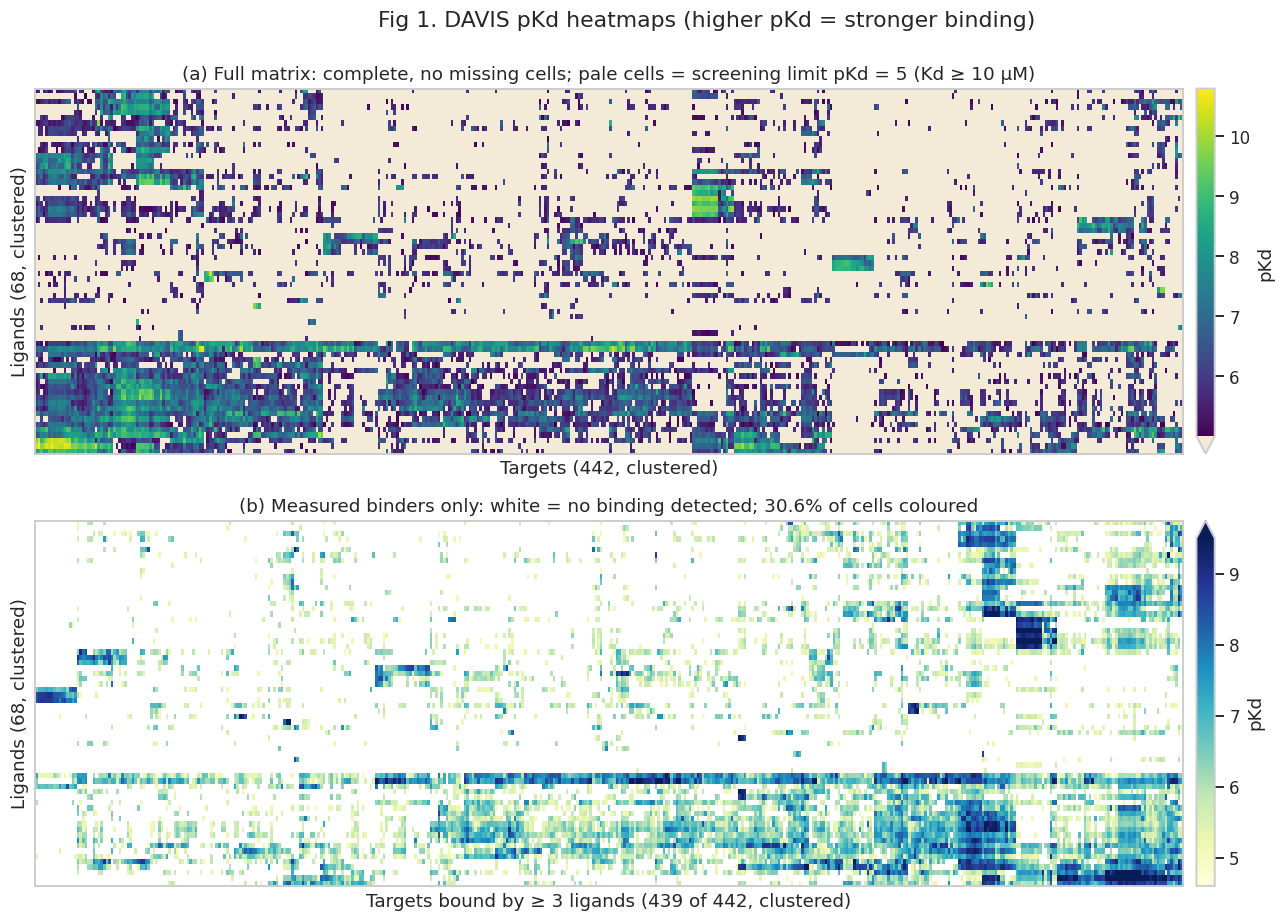

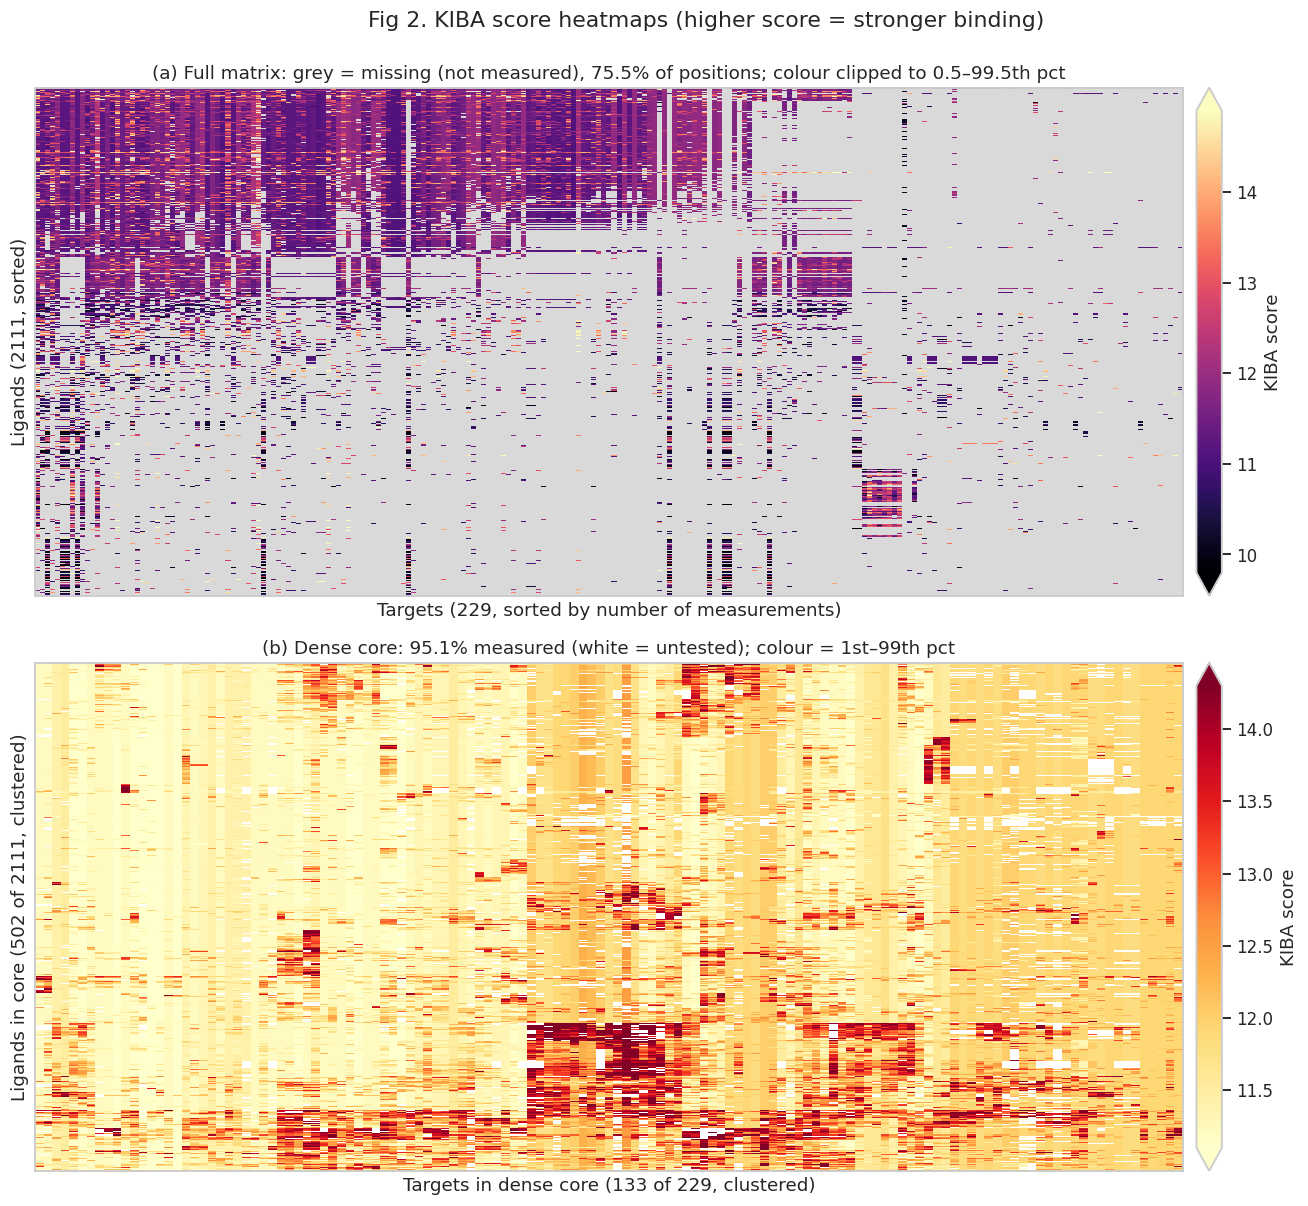

KIBA dense core: 502 ligands × 133 targets, 95.1% measured, 63,483 values (53.7% of all KIBA observations); median 11.70
Median spread (sd) across a core ligand's targets: 0.54;  across a core target's ligands: 0.58


In [ ]:
M_d = davis_c.pivot(index="ligand_id", columns="target_id", values="score")
M_k = kiba_c.pivot(index="ligand_id", columns="target_id", values="score")
row_o = leaves_list(linkage(M_d.values, "ward"))
col_o = leaves_list(linkage(M_d.values.T, "ward"))
Md_ord = M_d.iloc[row_o, col_o]

fig, axes = plt.subplots(2, 1, figsize=(13, 8.4))
ax = axes[0]
cmap = plt.get_cmap("viridis").copy(); cmap.set_under("#f3ead7")
im = ax.imshow(Md_ord.values, aspect="auto", cmap=cmap, vmin=5.0001, vmax=Md_ord.values.max(), interpolation="nearest")
cb = fig.colorbar(im, ax=ax, extend="min", pad=0.01); cb.set_label("pKd")
ax.set_xlabel(f"Targets ({M_d.shape[1]}, clustered)"); ax.set_ylabel(f"Ligands ({M_d.shape[0]}, clustered)")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("(a) Full matrix: complete, no missing cells; pale cells = screening limit pKd = 5 (Kd ≥ 10 µM)")

keep_t = (M_d > 5).sum(0) >= 3
Md_b = M_d.loc[:, keep_t]
ro = leaves_list(linkage(Md_b.values, "ward")); co = leaves_list(linkage(Md_b.values.T, "ward"))
show = Md_b.iloc[ro, co].where(Md_b.iloc[ro, co] > 5)
ax = axes[1]
cm = plt.get_cmap("YlGnBu").copy(); cm.set_bad("white")
im = ax.imshow(np.ma.masked_invalid(show.values), aspect="auto", cmap=cm, vmin=4.6, vmax=9.5, interpolation="nearest")
cb = fig.colorbar(im, ax=ax, extend="max", pad=0.01); cb.set_label("pKd")
ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel(f"Targets bound by ≥ 3 ligands ({show.shape[1]} of {M_d.shape[1]}, clustered)")
ax.set_ylabel(f"Ligands ({show.shape[0]}, clustered)")
ax.set_title(f"(b) Measured binders only: white = no binding detected; {show.notna().values.mean():.1%} of cells coloured")
fig.suptitle("Fig 1. DAVIS pKd heatmaps (higher pKd = stronger binding)", y=0.995)
fig.tight_layout(); fig.savefig("figures/fig1_davis_heatmaps.png"); plt.show()

r_k = M_k.notna().sum(1).sort_values(ascending=False).index
c_k = M_k.notna().sum(0).sort_values(ascending=False).index
Mk_ord = M_k.loc[r_k, c_k]
fig, axes = plt.subplots(2, 1, figsize=(13, 11))
ax = axes[0]
cmap2 = plt.get_cmap("magma").copy(); cmap2.set_bad("#d9d9d9")
vlo, vhi = np.nanpercentile(Mk_ord.values, [0.5, 99.5])
im = ax.imshow(np.ma.masked_invalid(Mk_ord.values), aspect="auto", cmap=cmap2, vmin=vlo, vmax=vhi, interpolation="nearest")
cb = fig.colorbar(im, ax=ax, extend="both", pad=0.01); cb.set_label("KIBA score")
ax.set_xlabel(f"Targets ({M_k.shape[1]}, sorted by number of measurements)")
ax.set_ylabel(f"Ligands ({M_k.shape[0]}, sorted)")
ax.set_xticks([]); ax.set_yticks([])
sp = 1 - M_k.notna().values.mean()
ax.set_title(f"(a) Full matrix: grey = missing (not measured), {sp:.1%} of positions; colour clipped to 0.5–99.5th pct")

O = M_k.notna().values; rows = np.arange(O.shape[0]); cols = np.arange(O.shape[1])
while O[np.ix_(rows, cols)].mean() < 0.95:
    sub = O[np.ix_(rows, cols)]; rf, cf = sub.mean(1), sub.mean(0)
    if rf.min() <= cf.min():
        rows = rows[rf > (np.quantile(rf, 0.02) if len(rows) > 50 else rf.min())]
    else:
        cols = cols[cf > (np.quantile(cf, 0.02) if len(cols) > 20 else cf.min())]
core = M_k.iloc[rows, cols]
filled = core.apply(lambda r: r.fillna(r.mean()), axis=1)  # ordering only
ro = leaves_list(linkage(filled.values, "ward")); co = leaves_list(linkage(filled.values.T, "ward"))
core_o = core.iloc[ro, co]
ax = axes[1]
cm2 = plt.get_cmap("YlOrRd").copy(); cm2.set_bad("white")
lo_, hi_ = np.nanpercentile(core_o.values, [1, 99])
im = ax.imshow(np.ma.masked_invalid(core_o.values), aspect="auto", cmap=cm2, vmin=lo_, vmax=hi_, interpolation="nearest")
cb = fig.colorbar(im, ax=ax, extend="both", pad=0.01); cb.set_label("KIBA score")
ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel(f"Targets in dense core ({core.shape[1]} of {M_k.shape[1]}, clustered)")
ax.set_ylabel(f"Ligands in core ({core.shape[0]} of {M_k.shape[0]}, clustered)")
ax.set_title(f"(b) Dense core: {core.notna().values.mean():.1%} measured (white = untested); colour = 1st–99th pct")
fig.suptitle("Fig 2. KIBA score heatmaps (higher score = stronger binding)", y=0.995)
fig.tight_layout(); fig.savefig("figures/fig2_kiba_heatmaps.png"); plt.show()
core_vals = core.values[~np.isnan(core.values)]
print(f"KIBA dense core: {core.shape[0]} ligands × {core.shape[1]} targets, {core.notna().values.mean():.1%} measured, "
      f"{len(core_vals):,} values ({len(core_vals) / len(kiba_c):.1%} of all KIBA observations); median {np.median(core_vals):.2f}")
print(f"Median spread (sd) across a core ligand's targets: {core.std(1).median():.2f};  across a core target's ligands: {core.std(0).median():.2f}")

**Heatmaps.** The two matrices look nothing alike.

DAVIS (Fig 1) is complete but mostly at its floor. Once the screening-limit cells are blanked (Fig 1b), only a third of cells carry a measured affinity, and those form clear blocks: tight dark blocks are selective ligands hitting a few related kinases hard, one dark stripe across the full width is the promiscuous ligand 44259 (staurosporine), and the broad lower band is ligands that bind widely but weakly. Dark vertical blocks are kinase groups that many ligands hit.

KIBA (Fig 2) is dominated by grey. Its observed cells form rectangular blocks, the signature of panel screening where a compound set is tested against a fixed kinase set. So missingness in KIBA is **structured, not random**: whether a pair is observed depends on which study the ligand came from, not on whether it binds. A missing cell therefore cannot be read as "does not bind". The dense core (Fig 2b) keeps 502 ligands and 133 targets at 95% measured, over half of all KIBA observations. There, vertical stripes are targets that score high against most ligands, horizontal bands are generally potent ligands, and the dark block at the lower middle is a group of ligands hitting one target family specifically, which is exactly the ligand-target interaction a recommender has to learn.

### 3.2 Score distributions (KDE)

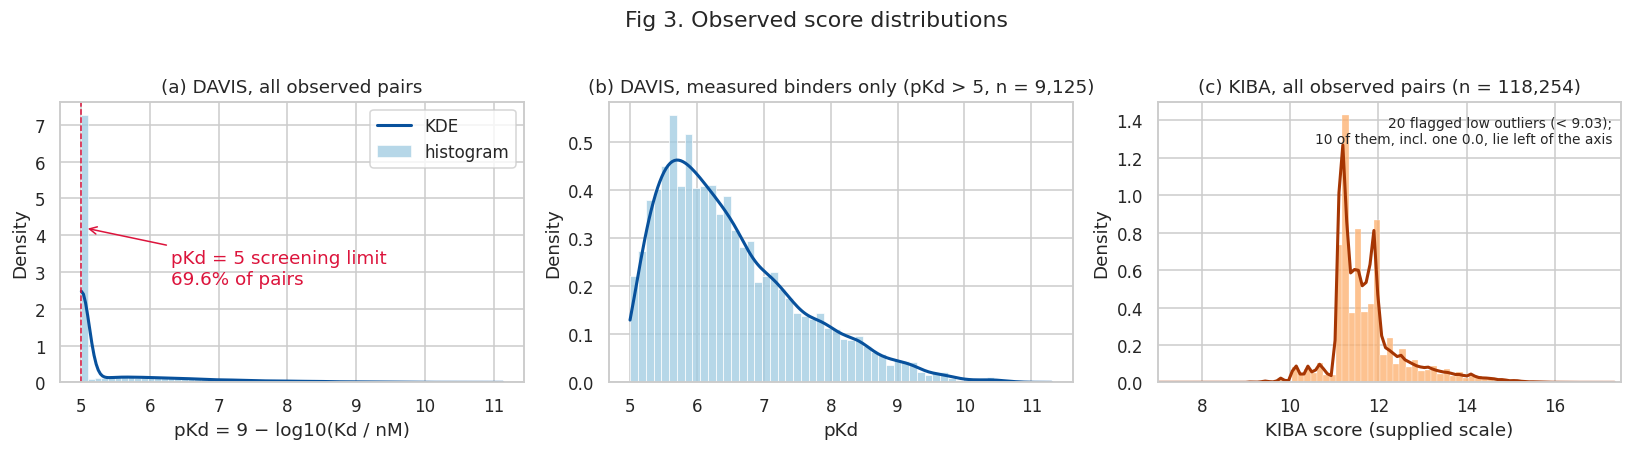

,DAVIS pKd (all),DAVIS pKd (> 5 only),KIBA score
n,30056.00,9125.00,118254.00
mean,5.45,6.49,11.72
sd,0.89,1.05,0.84
min,5.00,5.00,0.00
Q1,5.00,5.68,11.20
median,5.00,6.24,11.50
Q3,5.52,7.09,11.92
max,10.80,10.80,17.20
skew,2.30,0.98,1.16


Share of KIBA scores in 11.05–11.35: 31.1%
Share of KIBA scores that are exact multiples of 0.1: 84.3%
Ligand CHEMBL373751: 11 measurements, 10 of them flagged
KIBA flagged low outliers:


,ligand_id,target_id,score
103943,CHEMBL373751,P53350,0.000000
103939,CHEMBL373751,P00533,1.100000
103940,CHEMBL373751,P04626,1.100000
103941,CHEMBL373751,P49840,1.300000
103944,CHEMBL373751,P53779,1.300000
103942,CHEMBL373751,P49841,1.300000
103946,CHEMBL373751,Q15759,1.300000
103937,CHEMBL373751,O14920,6.100000
103938,CHEMBL373751,O15111,6.100000
103945,CHEMBL373751,Q14164,6.100004


In [ ]:
d_all = davis_c["score"]; d_unc = davis_c.loc[~davis_c["censored"], "score"]
k_all = kiba_c["score"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
sns.histplot(d_all, bins=60, stat="density", color="#9ecae1", ax=ax, label="histogram")
sns.kdeplot(d_all, ax=ax, color="#08519c", lw=2, label="KDE", clip=(5, None))
ax.axvline(5, color="crimson", ls="--", lw=1)
ymax = ax.get_ylim()[1]
ax.annotate(f"pKd = 5 screening limit\n{davis_c['censored'].mean():.1%} of pairs", xy=(5.05, ymax * 0.55),
            xytext=(6.3, ymax * 0.35), arrowprops=dict(arrowstyle="->", color="crimson"), color="crimson")
ax.set(xlabel="pKd = 9 − log10(Kd / nM)", ylabel="Density", title="(a) DAVIS, all observed pairs"); ax.legend(loc="upper right")
ax = axes[1]
sns.histplot(d_unc, bins=50, stat="density", color="#9ecae1", ax=ax)
sns.kdeplot(d_unc, ax=ax, color="#08519c", lw=2, clip=(5, None))
ax.set(xlabel="pKd", ylabel="Density", title=f"(b) DAVIS, measured binders only (pKd > 5, n = {len(d_unc):,})")
ax = axes[2]
sns.histplot(k_all, bins=120, stat="density", color="#fdae6b", ax=ax)
sns.kdeplot(k_all, ax=ax, color="#a63603", lw=2, bw_adjust=0.6)
ax.set(xlabel="KIBA score (supplied scale)", ylabel="Density", title=f"(c) KIBA, all observed pairs (n = {len(k_all):,})")
ax.set_xlim(7, 17.5)
n_low = int(kiba_c["low_outlier"].sum()); n_off = int((k_all < 7).sum())
ax.text(0.98, 0.95, f"{n_low} flagged low outliers (< 9.03);\n{n_off} of them, incl. one 0.0, lie left of the axis", transform=ax.transAxes, va="top", ha="right", fontsize=9)
fig.suptitle("Fig 3. Observed score distributions", y=1.02)
fig.tight_layout(); fig.savefig("figures/fig3_score_kde.png"); plt.show()

def describe(s):
    return pd.Series({"n": len(s), "mean": s.mean(), "sd": s.std(), "min": s.min(), "Q1": s.quantile(.25),
                      "median": s.median(), "Q3": s.quantile(.75), "max": s.max(), "skew": stats.skew(s)})
dist_table = pd.DataFrame({"DAVIS pKd (all)": describe(d_all), "DAVIS pKd (> 5 only)": describe(d_unc),
                           "KIBA score": describe(k_all)}).round(2)
dist_table.to_csv("results/table6_score_summary.csv")
display(dist_table)
print(f"Share of KIBA scores in 11.05–11.35: {((k_all >= 11.05) & (k_all <= 11.35)).mean():.1%}")
print(f"Share of KIBA scores that are exact multiples of 0.1: {(np.abs(k_all * 10 - np.round(k_all * 10)) < 1e-4).mean():.1%}")
print(f"Ligand CHEMBL373751: {(kiba_c['ligand_id'] == 'CHEMBL373751').sum()} measurements, "
      f"{kiba_c.loc[kiba_c['ligand_id'] == 'CHEMBL373751', 'low_outlier'].sum()} of them flagged")
print("KIBA flagged low outliers:")
display(kiba_c.loc[kiba_c["low_outlier"], ["ligand_id", "target_id", "score"]].sort_values("score"))

**Distributions.** DAVIS pKd is extremely right-skewed (skew 2.30). The median is exactly 5.00 because more than half the data sits at the censoring point, which a KDE can only draw as a tall narrow spike (Fig 3a). Looking only at measured binders (Fig 3b, n = 9,125) gives a smooth unimodal curve with median 6.24 and a long tail of strong binders up to pKd 10.80. KIBA (Fig 3c) is centred much higher (median 11.50) with a narrow IQR of 11.20–11.92 and a long right tail up to 17.20. It is also **spiky**. 31.1% of scores lie between 11.05 and 11.35, and 84.3% are exact multiples of 0.1, so the supplied scale is coarsely discretised.

Two consequences carry into Task 2. First, a model that predicts "pKd = 5" for every DAVIS pair, or the median for every KIBA pair, already gets a low MSE, so MSE alone will flatter weak models and we need ranking metrics (CI, Hit@k) and a baseline. Second, the many tied true scores mean CI ignores a large share of pairs, since it only counts pairs with different true scores.

### 3.3 Further analysis

The plots above describe the scores. The analyses below ask the questions that matter for Tasks 2 and 3.

* **(A)** How many measurements does each ligand and target have, and how many ligand pairs share enough targets to be compared? Collaborative filtering needs these "neighbours".
* **(B)** How selective is each DAVIS ligand? Some kinase inhibitors bind almost everything and others bind almost nothing.
* **(C)** How much of the score is explained by "which ligand" and "which target" alone, and how much is a specific interaction? This tells us how strong a simple mean baseline will be in Task 2.
* **(D)** Is the DAVIS matrix low-rank? Matrix-factorisation CF assumes it is.
* **(E)** Do structurally similar ligands, and similar protein sequences, bind similarly? If yes, structure can stand in for missing measurements, which is the idea behind Task 3.
* **(F)** Do the two datasets overlap, and do they agree where they do?

#### (A) Measurements per ligand and target, and neighbour availability

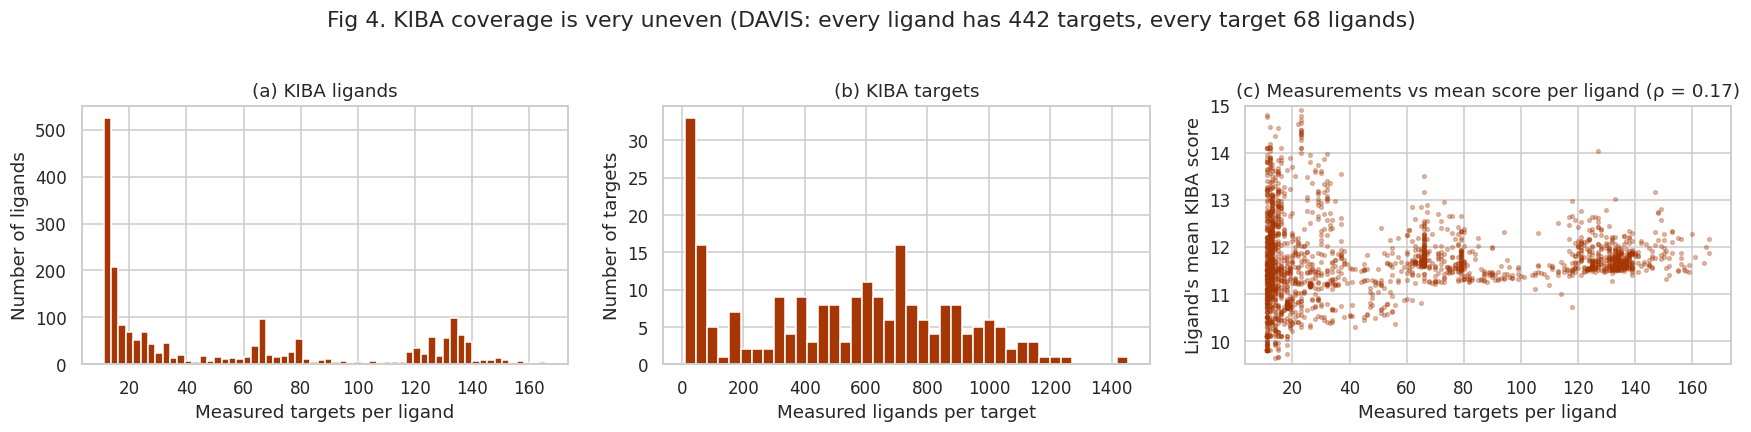

,KIBA ligands,KIBA targets
min,11.0,11.0
25%,14.0,173.0
50%,30.0,567.0
75%,96.0,774.0
max,166.0,1452.0


Spearman ρ between a ligand's number of measurements and its mean score: 0.17
Mean score, ligands with ≤ 20 measurements: 11.56 (n = 866);  ≥ 100: 11.77 (n = 520)


,KIBA
Ligands with ≤ 20 measured targets,41.0%
Ligand pairs sharing 0 targets,8.1%
Ligand pairs sharing ≥ 5 targets,62.1%
Ligand pairs sharing ≥ 20 targets,24.0%
Median shared targets per ligand pair,7
Ligands with no other ligand sharing ≥ 5 targets,0


In [ ]:
obs_k = M_k.notna().values.astype(np.float32)
per_lig_k = obs_k.sum(1); per_tgt_k = obs_k.sum(0)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(per_lig_k, bins=60, color="#a63603")
axes[0].set(xlabel="Measured targets per ligand", ylabel="Number of ligands", title="(a) KIBA ligands")
axes[1].hist(per_tgt_k, bins=40, color="#a63603")
axes[1].set(xlabel="Measured ligands per target", ylabel="Number of targets", title="(b) KIBA targets")
mean_lig_k = np.nanmean(M_k.values, axis=1)
rho_mnar = stats.spearmanr(per_lig_k, mean_lig_k).statistic
axes[2].scatter(per_lig_k, mean_lig_k, s=6, alpha=0.3, color="#a63603")
axes[2].set(xlabel="Measured targets per ligand", ylabel="Ligand's mean KIBA score", title=f"(c) Measurements vs mean score per ligand (ρ = {rho_mnar:.2f})")
axes[2].set_ylim(9.5, 15)
fig.suptitle("Fig 4. KIBA coverage is very uneven (DAVIS: every ligand has 442 targets, every target 68 ligands)", y=1.03)
fig.tight_layout(); fig.savefig("figures/fig4_kiba_coverage.png"); plt.show()

overlap = obs_k @ obs_k.T
iu = np.triu_indices_from(overlap, k=1)
ov = overlap[iu]
cov_table = pd.DataFrame({
    "KIBA ligands": pd.Series(per_lig_k).describe()[["min", "25%", "50%", "75%", "max"]],
    "KIBA targets": pd.Series(per_tgt_k).describe()[["min", "25%", "50%", "75%", "max"]],
}).round(0)
display(cov_table)
print(f"Spearman ρ between a ligand's number of measurements and its mean score: {rho_mnar:.2f}")
few, many = per_lig_k <= 20, per_lig_k >= 100
print(f"Mean score, ligands with ≤ 20 measurements: {mean_lig_k[few].mean():.2f} (n = {few.sum()});  ≥ 100: {mean_lig_k[many].mean():.2f} (n = {many.sum()})")
nb = pd.Series({
    "Ligands with ≤ 20 measured targets": f"{(per_lig_k <= 20).mean():.1%}",
    "Ligand pairs sharing 0 targets": f"{(ov == 0).mean():.1%}",
    "Ligand pairs sharing ≥ 5 targets": f"{(ov >= 5).mean():.1%}",
    "Ligand pairs sharing ≥ 20 targets": f"{(ov >= 20).mean():.1%}",
    "Median shared targets per ligand pair": f"{np.median(ov):.0f}",
    "Ligands with no other ligand sharing ≥ 5 targets": int((((overlap >= 5).sum(1) - 1) == 0).sum()),
}, name="KIBA")
nb.to_csv("results/table7_kiba_neighbours.csv")
display(nb.to_frame())

**Neighbour availability.** KIBA has already been filtered so that every ligand and target has at least 11 measurements, but coverage is still very uneven. The median ligand has 30 measured targets (out of 229) and 41.0% of ligands have 20 or fewer. Targets range from 11 to 1,452 measured ligands. For a pair of ligands, the median number of shared targets is only 7. 8.1% of ligand pairs share none at all, and only 24.0% share 20 or more. Any similarity between two KIBA ligands is therefore estimated from very few common targets and will be noisy, which is the key difficulty for neighbour-based CF on KIBA. DAVIS has the opposite situation: every ligand pair shares all 442 targets. Fig 4c shows a weak positive link between how often a ligand was measured and its mean score (ρ = 0.17), plus a clear split between lightly measured ligands, whose means range widely, and heavily screened panel ligands, whose means cluster tightly around 11.7.

#### (B) Ligand selectivity in DAVIS

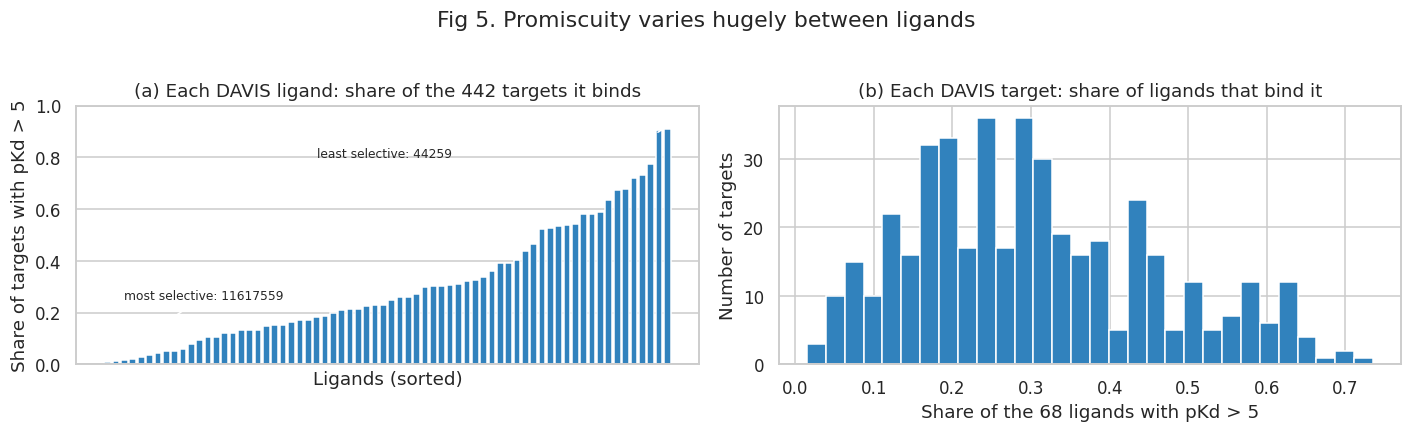

Ligand binding share: min 0.9% (11617559), median 24.0%, max 91.0% (44259)
Ligands binding < 10% of targets: 12 of 68;  binding > 50%: 16
Molecular formula of 44259: C28H26N4O3 (staurosporine is C28H26N4O3)
Targets bound by no ligand: 0;  median target binding share: 27.9%


In [ ]:
!pip install -q rdkit
sel = (M_d > 5).mean(1).sort_values()
tgt_hit = (M_d > 5).mean(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(range(len(sel)), sel.values, color="#3182bd")
axes[0].set(xlabel="Ligands (sorted)", ylabel="Share of targets with pKd > 5", title="(a) Each DAVIS ligand: share of the 442 targets it binds")
axes[0].set_xticks([])
axes[0].annotate(f"most selective: {sel.index[0]}", (0, sel.values[0]), xytext=(2, 0.25), fontsize=8, arrowprops=dict(arrowstyle="->"))
axes[0].annotate(f"least selective: {sel.index[-1]}", (len(sel) - 1, sel.values[-1]), xytext=(25, 0.8), fontsize=8, arrowprops=dict(arrowstyle="->"))
axes[0].set_ylim(0, 1)
axes[1].hist(tgt_hit, bins=30, color="#3182bd")
axes[1].set(xlabel="Share of the 68 ligands with pKd > 5", ylabel="Number of targets", title="(b) Each DAVIS target: share of ligands that bind it")
fig.suptitle("Fig 5. Promiscuity varies hugely between ligands", y=1.03)
fig.tight_layout(); fig.savefig("figures/fig5_davis_selectivity.png"); plt.show()
print(f"Ligand binding share: min {sel.min():.1%} ({sel.index[0]}), median {sel.median():.1%}, max {sel.max():.1%} ({sel.index[-1]})")
print(f"Ligands binding < 10% of targets: {(sel < .10).sum()} of {len(sel)};  binding > 50%: {(sel > .5).sum()}")
from rdkit.Chem.rdMolDescriptors import CalcMolFormula
from rdkit import Chem as _Chem
print(f"Molecular formula of {sel.index[-1]}: {CalcMolFormula(_Chem.MolFromSmiles(lig_d[sel.index[-1]]))} (staurosporine is C28H26N4O3)")
print(f"Targets bound by no ligand: {(tgt_hit == 0).sum()};  median target binding share: {tgt_hit.median():.1%}")

**Selectivity.** DAVIS ligands range from binding 0.9% of targets (ligand 11617559) to 91.0% (ligand 44259, whose formula C28H26N4O3 matches staurosporine, a well-known non-selective kinase inhibitor). 12 of the 68 ligands bind fewer than 10% of targets and 16 bind more than half. Every target is bound by at least one ligand, with a median target bound by 27.9% of ligands. This matters for recommendation. For a promiscuous ligand almost every target scores well, so ranking is hard and "best target" is close to a tie. For a highly selective ligand, almost every target sits at pKd = 5 and there is a single right answer. The three DAVIS case-study ligands in the brief can be checked against this spectrum.

#### (C) How much is ligand effect, target effect, or interaction?

We fit four simple descriptive models on all observed entries and report R² (share of score variance explained). The additive model `score ≈ μ + b_ligand + b_target` is fitted by alternating averages, using observed entries only, so it works on sparse KIBA too. This is purely descriptive and is not used for evaluation. Whatever the additive model cannot explain is the ligand–target *interaction*, the part only a personalised method such as CF can capture.

In [ ]:
def r2_decomposition(df, lig="ligand_id", tgt="target_id", iters=30):
    y = df["score"].values; mu = y.mean(); sst = ((y - mu) ** 2).sum()
    r2 = lambda pred: 1 - ((y - pred) ** 2).sum() / sst
    lm = df.groupby(lig)["score"].transform("mean").values
    tm = df.groupby(tgt)["score"].transform("mean").values
    bl = pd.Series(0.0, index=df[lig].unique()); bt = pd.Series(0.0, index=df[tgt].unique())
    for _ in range(iters):
        bt = (df["score"] - mu - df[lig].map(bl)).groupby(df[tgt]).mean()
        bl = (df["score"] - mu - df[tgt].map(bt)).groupby(df[lig]).mean()
    add = mu + df[lig].map(bl).values + df[tgt].map(bt).values
    return pd.Series({"Ligand mean only": r2(lm), "Target mean only": r2(tm),
                      "Ligand + target (additive)": r2(add), "Unexplained (interaction + noise)": 1 - r2(add)})

r2_tab = pd.DataFrame({"DAVIS": r2_decomposition(davis_c), "KIBA": r2_decomposition(kiba_c)}).round(3)
r2_tab.to_csv("results/table8_variance_decomposition.csv")
display(r2_tab)

,DAVIS,KIBA
Ligand mean only,0.226,0.420
Target mean only,0.126,0.141
Ligand + target (additive),0.353,0.521
Unexplained (interaction + noise),0.647,0.479


**Variance decomposition.** Knowing only the ligand explains 22.6% of score variance in DAVIS and 42.0% in KIBA. Adding the target as an additive effect raises this to 35.3% and 52.1%. The rest (64.7% in DAVIS and 47.9% in KIBA) is ligand–target interaction plus noise, which is exactly what a mean baseline cannot capture and CF could. KIBA is more "ligand-driven": a ligand's average score already tells you a lot, so a ligand-mean baseline will be strong there and CF has less room to improve. DAVIS has more interaction structure for CF to exploit, but much of it is the censored/non-censored pattern.

#### (D) Low-rank structure of DAVIS

DAVIS is complete, so we can take an SVD of the double-centred pKd matrix (ligand and target means removed) and see how many latent factors carry the interaction signal. KIBA cannot be decomposed this way without imputing three quarters of the matrix, and imputing would invent data.

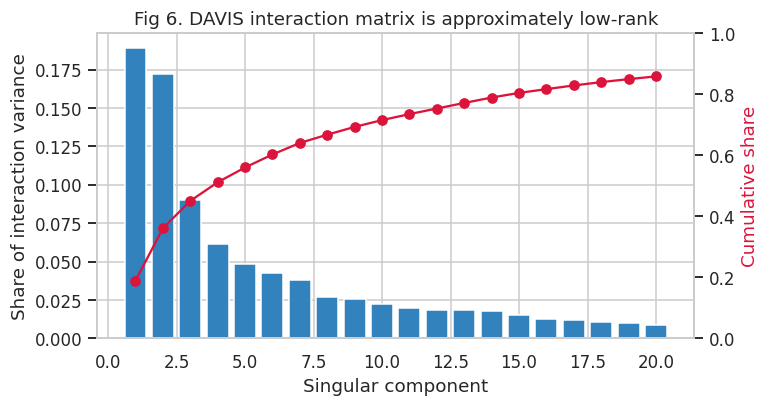

{'top 1': '18.9%', 'top 3': '45.1%', 'top 5': '56.0%', 'top 10': '71.6%', 'top 20': '85.9%'}


In [ ]:
X = M_d.values
Xc = X - X.mean(1, keepdims=True) - X.mean(0, keepdims=True) + X.mean()
s = np.linalg.svd(Xc, compute_uv=False)
ev = s ** 2 / (s ** 2).sum(); cum = np.cumsum(ev)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(np.arange(1, 21), ev[:20], color="#3182bd", label="per component")
ax2 = ax.twinx(); ax2.plot(np.arange(1, 21), cum[:20], "o-", color="crimson", label="cumulative"); ax2.set_ylim(0, 1)
ax2.grid(False)
ax.set(xlabel="Singular component", ylabel="Share of interaction variance", title="Fig 6. DAVIS interaction matrix is approximately low-rank")
ax2.set_ylabel("Cumulative share", color="crimson")
fig.savefig("figures/fig6_davis_svd.png"); plt.show()
print({f"top {k}": f"{cum[k-1]:.1%}" for k in [1, 3, 5, 10, 20]})

**Low rank.** The DAVIS interaction matrix (after removing ligand and target means) has 68 possible components, but the top 3 explain 45.1% of its variance, the top 10 explain 71.6% and the top 20 explain 85.9%. Binding profiles are therefore driven by a small number of latent factors, plausibly kinase families and inhibitor chemotypes. This supports matrix factorisation for Task 2 and suggests a latent dimension around 5–20 as a sensible search range on the validation set.

#### (E) Does structural similarity predict binding similarity?

For ligands we compare chemical similarity (Tanimoto on Morgan fingerprints, radius 2, 2048 bits, via RDKit) with binding-profile similarity (Pearson correlation of scores over the targets both ligands were measured on, needing at least 10 shared targets). For targets we compare sequence similarity (cosine of 3-mer amino-acid composition vectors) with binding-profile similarity over shared ligands. We use the deduplicated strings so that identical inputs are not compared with themselves.

*Code reuse:* Morgan fingerprints are generated with RDKit's standard `AllChem.GetMorganFingerprintAsBitVect` call. The masked pairwise Pearson formula is our own vectorised version of the textbook formula.

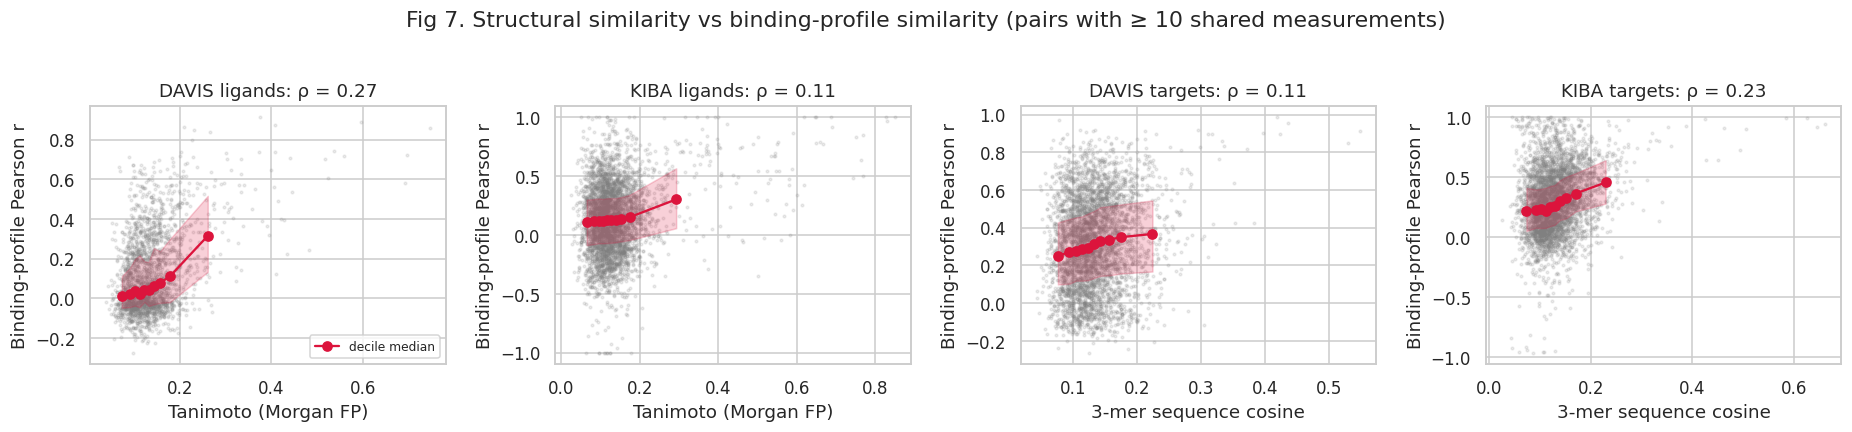

,dataset,entity,pairs compared,Spearman ρ
0,DAVIS,ligands,2278,0.270
1,KIBA,ligands,820286,0.114
2,DAVIS,targets,71631,0.114
3,KIBA,targets,17086,0.231


In [ ]:
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
RDLogger.DisableLog("rdApp.*")

def morgan_matrix(smiles_list):
    F = np.zeros((len(smiles_list), 2048), dtype=np.float32)
    for i, s in enumerate(smiles_list):
        fp = AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, nBits=2048)
        F[i, list(fp.GetOnBits())] = 1
    inter = F @ F.T; cnt = F.sum(1)
    return inter / (cnt[:, None] + cnt[None, :] - inter)

def kmer_cosine(seqs, k=3):
    from sklearn.feature_extraction.text import CountVectorizer
    V = CountVectorizer(analyzer="char", ngram_range=(k, k), lowercase=False).fit_transform(seqs).astype(np.float32)
    V = V.multiply(1 / np.sqrt(V.multiply(V).sum(1))).tocsr()
    return (V @ V.T).toarray()

def masked_pearson(Mat):
    """Pearson correlation between rows of Mat using only co-observed columns. Returns (corr, n_shared)."""
    Mat = Mat - np.nanmean(Mat, axis=1, keepdims=True)  # shifting a row does not change Pearson r, but avoids round-off
    O = (~np.isnan(Mat)).astype(np.float64); Xf = np.nan_to_num(Mat)
    n = O @ O.T; sx = Xf @ O.T; sy = sx.T; sxx = (Xf ** 2) @ O.T; syy = sxx.T; sxy = Xf @ Xf.T
    num = n * sxy - sx * sy
    den = np.sqrt(np.clip(n * sxx - sx ** 2, 0, None) * np.clip(n * syy - sy ** 2, 0, None))
    with np.errstate(invalid="ignore", divide="ignore"):
        C = np.where(den > 1e-9 * n ** 2, num / den, np.nan)  # undefined if either profile is constant on shared columns
    return np.clip(C, -1, 1), n

def sim_vs_profile(dd, struct_fn, entity, min_shared=10):
    key, other = ("smiles", "sequence") if entity == "ligand" else ("sequence", "smiles")
    Mat = dd.pivot(index=key, columns=other, values="score")
    S = struct_fn(list(Mat.index))
    C, n = masked_pearson(Mat.values)
    iu = np.triu_indices(len(Mat), 1)
    ok = (n[iu] >= min_shared) & np.isfinite(C[iu])
    return S[iu][ok], C[iu][ok]

res = {}
res[("DAVIS", "ligands")] = sim_vs_profile(davis_dd, morgan_matrix, "ligand")
res[("KIBA", "ligands")] = sim_vs_profile(kiba_dd, morgan_matrix, "ligand")
res[("DAVIS", "targets")] = sim_vs_profile(davis_dd, kmer_cosine, "target")
res[("KIBA", "targets")] = sim_vs_profile(kiba_dd, kmer_cosine, "target")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
rows = []
for ax, ((ds, ent), (sx, cy)) in zip(axes, res.items()):
    bins = np.quantile(sx, np.linspace(0, 1, 11))
    idx = np.clip(np.digitize(sx, bins[1:-1]), 0, 9)
    mids = [sx[idx == b].mean() for b in range(10)]
    med = [np.median(cy[idx == b]) for b in range(10)]
    q1 = [np.quantile(cy[idx == b], .25) for b in range(10)]; q3 = [np.quantile(cy[idx == b], .75) for b in range(10)]
    sub = rng.choice(len(sx), min(4000, len(sx)), replace=False)
    ax.scatter(sx[sub], cy[sub], s=3, alpha=0.15, color="grey")
    ax.plot(mids, med, "o-", color="crimson", label="decile median"); ax.fill_between(mids, q1, q3, color="crimson", alpha=0.2)
    rho = stats.spearmanr(sx, cy).statistic
    rows.append({"dataset": ds, "entity": ent, "pairs compared": len(sx), "Spearman ρ": round(rho, 3)})
    xl = "Tanimoto (Morgan FP)" if ent == "ligands" else "3-mer sequence cosine"
    ax.set(xlabel=xl, ylabel="Binding-profile Pearson r", title=f"{ds} {ent}: ρ = {rho:.2f}")
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Fig 7. Structural similarity vs binding-profile similarity (pairs with ≥ 10 shared measurements)", y=1.03)
fig.tight_layout(); fig.savefig("figures/fig7_structure_vs_profile.png"); plt.show()
sim_table = pd.DataFrame(rows); sim_table.to_csv("results/table9_structure_vs_profile.csv", index=False)
display(sim_table)

**Structure vs binding.** All four correlations are positive but weak (ρ = 0.11 to 0.27). Chemically similar DAVIS ligands bind similar target sets (ρ = 0.27), and the trend is steepest in the top decile of Tanimoto similarity. Similar KIBA target sequences have similar ligand profiles (ρ = 0.23). The KIBA ligand signal is weakest (ρ = 0.11), partly because profiles are compared over few shared targets. DAVIS targets are weak (ρ = 0.11) because 3-mer composition over a full-length sequence mostly captures general protein composition rather than the binding pocket, and because mutants share sequences.

This is the motivating evidence for Task 3. Sequence similarity carries a real but modest signal about how a target binds, so a cold-target model can use it to replace missing measurements, but simple whole-sequence features will not be enough. Better protein representations, such as pocket- or domain-focused features or learned embeddings, are likely needed.

#### (F) Overlap and agreement between DAVIS and KIBA

Shared ligands (identical SMILES): 9
Shared targets (identical sequence): 179
Pairs measured in both datasets: 1043
Spearman ρ between DAVIS pKd and KIBA score on shared pairs: 0.69
KIBA score where DAVIS is censored (n = 571): mean 11.59, median 11.50;  where DAVIS is fully measured (n = 457): mean 12.77


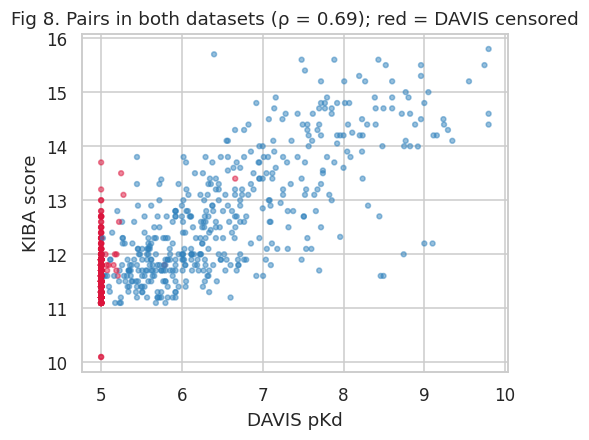

In [ ]:
shared_lig = set(davis_dd["smiles"]) & set(kiba_dd["smiles"])
shared_seq = set(davis_dd["sequence"]) & set(kiba_dd["sequence"])
both = davis_dd.merge(kiba_dd, on=["smiles", "sequence"], suffixes=("_davis", "_kiba"))
print(f"Shared ligands (identical SMILES): {len(shared_lig)}")
print(f"Shared targets (identical sequence): {len(shared_seq)}")
print(f"Pairs measured in both datasets: {len(both)}")
if len(both) >= 10:
    rho = stats.spearmanr(both["score_davis"], both["score_kiba"]).statistic
    print(f"Spearman ρ between DAVIS pKd and KIBA score on shared pairs: {rho:.2f}")
    cen = both["censored_frac"] == 1
    print(f"KIBA score where DAVIS is censored (n = {cen.sum()}): mean {both.loc[cen, 'score_kiba'].mean():.2f}, "
          f"median {both.loc[cen, 'score_kiba'].median():.2f};  where DAVIS is fully measured (n = {(both['censored_frac'] == 0).sum()}): "
          f"mean {both.loc[both['censored_frac'] == 0, 'score_kiba'].mean():.2f}")
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.scatter(both["score_davis"], both["score_kiba"], s=10, alpha=0.5, c=np.where(both["censored_frac"] > 0, "crimson", "#3182bd"))
    ax.set(xlabel="DAVIS pKd", ylabel="KIBA score", title=f"Fig 8. Pairs in both datasets (ρ = {rho:.2f}); red = DAVIS censored")
    fig.savefig("figures/fig8_davis_kiba_overlap.png"); plt.show()

**Overlap.** The two datasets share only 9 identical ligands but 179 identical target sequences, and 1,043 pairs are measured in both. Where both exist, the scores agree well in rank (Spearman ρ = 0.69, Fig 8), which supports treating both as measures of the same underlying affinity. The censored DAVIS pairs are informative here. Where DAVIS says "pKd = 5 (no binding detected)", KIBA gives a mean of 11.59, close to its own spike at ~11.2, while fully measured DAVIS pairs average 12.77 in KIBA. KIBA's dense band around 11.1–11.9 therefore behaves much like DAVIS's censored floor, a weak-or-inactive region rather than precise affinities. This is our interpretation of the overlap, not something documented with the dataset.

## 4. Summary table: key differences between DAVIS and KIBA

In [ ]:
summary = pd.DataFrame({
    "DAVIS": {
        "Size (dedup ligands × targets)": f"{davis_dd['smiles'].nunique()} × {davis_dd['sequence'].nunique()}",
        "Observed pairs (dedup)": f"{len(davis_dd):,}",
        "Sparsity": "0% (complete)",
        "Score": "pKd from a single assay type (Kd)",
        "Typical score": f"median {d_all.median():.2f}, mean {d_all.mean():.2f}",
        "Main abnormality": f"{davis_c['censored'].mean():.1%} of pairs at screening limit pKd = 5",
        "Variance explained by ligand + target means": f"{r2_tab.loc['Ligand + target (additive)', 'DAVIS']:.1%}",
        "Duplicate issue": f"{len(g_dp)} sequence groups merge {sum(len(g) for g in g_dp)} target IDs (mutants, domains)",
    },
    "KIBA": {
        "Size (dedup ligands × targets)": f"{kiba_dd['smiles'].nunique()} × {kiba_dd['sequence'].nunique()}",
        "Observed pairs (dedup)": f"{len(kiba_dd):,}",
        "Sparsity": count_table[("KIBA", "Deduplicated (SMILES, sequence)")]["Sparsity (missing / all positions)"],
        "Score": "Composite of Ki, Kd, IC50",
        "Typical score": f"median {k_all.median():.2f}, mean {k_all.mean():.2f}",
        "Main abnormality": f"{n_low} extreme low values incl. one 0.0; missingness is not random",
        "Variance explained by ligand + target means": f"{r2_tab.loc['Ligand + target (additive)', 'KIBA']:.1%}",
        "Duplicate issue": f"{len(g_kl)} SMILES groups merge {sum(len(g) for g in g_kl)} ligand IDs (stereoisomers)",
    },
})
summary.to_csv("results/table10_davis_vs_kiba.csv")
display(summary)

,DAVIS,KIBA
Size (dedup ligands × targets),68 × 379,2068 × 229
Observed pairs (dedup),"25,772","117,657"
Sparsity,0% (complete),75.16%
Score,pKd from a single assay type (Kd),"Composite of Ki, Kd, IC50"
Typical score,"median 5.00, mean 5.45","median 11.50, mean 11.72"
Main abnormality,69.6% of pairs at screening limit pKd = 5,20 extreme low values incl. one 0.0; missingness is not ...
Variance explained by ligand + target means,35.3%,52.1%
Duplicate issue,"18 sequence groups merge 81 target IDs (mutants, domains)",32 SMILES groups merge 75 ligand IDs (stereoisomers)


## 5. Key findings and what they mean for Tasks 2 and 3

1. **DAVIS is complete but heavily censored.** 69.6% of pairs sit at the pKd = 5 screening limit; blanking them (Fig 1b) leaves only a third of the matrix as real measurements. They are kept and flagged. A model that predicts "5" everywhere already scores a low MSE, so Task 2 must compare against a baseline and report ranking metrics.
2. **KIBA is large but 75.5% missing, and missingness is structured by screening panels** (Fig 2a). Ligand pairs share a median of only 7 targets, so neighbour similarities are noisy and many predictions will fall back to means. Missing is never treated as non-binding.
3. **Deduplication depends on the input.** At ID level there are no duplicates. At string level, DAVIS mutants collapse (442 to 379 targets) and KIBA stereoisomers collapse (2,111 to 2,068 ligands), and merged scores can differ by up to 4.75 pKd units. We keep both versions and use the one that matches each task's input.
4. **Ligand identity explains a lot.** It accounts for 22.6% (DAVIS) and 42.0% (KIBA) of variance alone, and ligand + target means explain 35.3% and 52.1%. CF only adds value through the remaining interaction, which is larger in DAVIS. The dense-core view (Fig 2b) shows that interaction directly, as blocks that cut across the general ligand and target effects.
5. **DAVIS interactions are low-rank** (top 10 components = 71.6%, Fig 6), which supports matrix factorisation.
6. **Structural similarity weakly predicts binding similarity** (ρ = 0.11 to 0.27, Fig 7), which is the starting point for cold-target prediction in Task 3.

**Figure index.** Fig 1 DAVIS heatmaps (full, binders only) · Fig 2 KIBA heatmaps (full, dense core) · Fig 3 score distributions · Fig 4 KIBA coverage · Fig 5 DAVIS selectivity · Fig 6 DAVIS SVD · Fig 7 structure vs binding profile · Fig 8 DAVIS-KIBA overlap.

In [ ]:
#splitting of dataset
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import os

SEED = 42

def make_cf_split(df, seed=SEED):
    """
    70/15/15 pair-level split.
    Every ligand and target must occur in training.
    """
    df = df[["ligand_id", "target_id", "score"]].copy()
    df = df.dropna(subset=["score"]).reset_index(drop=True)

    # Each ligand-target pair must be unique
    assert not df.duplicated(["ligand_id", "target_id"]).any()

    all_ligands = set(df["ligand_id"])
    all_targets = set(df["target_id"])

    for attempt in range(1000):
        random_state = seed + attempt

        train, remaining = train_test_split(
            df,
            test_size=0.30,
            random_state=random_state
        )

        val, test = train_test_split(
            remaining,
            test_size=0.50,
            random_state=random_state
        )

        train_ligands = set(train["ligand_id"])
        train_targets = set(train["target_id"])

        # All entities must have training observations
        if (all_ligands.issubset(train_ligands)
                and all_targets.issubset(train_targets)):
            break
    else:
        raise ValueError("Could not find a valid split.")

    # Verify there is no pair overlap
    train_pairs = set(zip(train.ligand_id, train.target_id))
    val_pairs = set(zip(val.ligand_id, val.target_id))
    test_pairs = set(zip(test.ligand_id, test.target_id))

    assert train_pairs.isdisjoint(val_pairs)
    assert train_pairs.isdisjoint(test_pairs)
    assert val_pairs.isdisjoint(test_pairs)

    # Verify no cold-start entities
    for split in [val, test]:
        assert set(split.ligand_id).issubset(train_ligands)
        assert set(split.target_id).issubset(train_targets)

    return train, val, test


davis_train, davis_val, davis_test = make_cf_split(davis_c)
kiba_train, kiba_val, kiba_test = make_cf_split(kiba_c)

def split_summary(name, train, val, test):
    return pd.DataFrame({
        "Dataset": [name] * 3,
        "Partition": ["Train", "Validation", "Test"],
        "Observations": [len(train), len(val), len(test)],
        "Percentage": [
            len(train) / (len(train) + len(val) + len(test)) * 100,
            len(val) / (len(train) + len(val) + len(test)) * 100,
            len(test) / (len(train) + len(val) + len(test)) * 100
        ]
    })

split_results = pd.concat([
    split_summary("DAVIS", davis_train, davis_val, davis_test),
    split_summary("KIBA", kiba_train, kiba_val, kiba_test)
])

display(split_results.round(2))



,Dataset,Partition,Observations,Percentage
0,DAVIS,Train,21039,70.0
1,DAVIS,Validation,4508,15.0
2,DAVIS,Test,4509,15.0
0,KIBA,Train,82777,70.0
1,KIBA,Validation,17738,15.0
2,KIBA,Test,17739,15.0


##2.2 Recommending a Drug to a Given Target with collaborative filtering


In [ ]:
from itertools import product

class BiasedMatrixFactorization:

    def __init__(self, n_factors=16, learning_rate=0.005,
                 reg=0.01, epochs=100, seed=42):

        self.n_factors = n_factors
        self.lr = learning_rate
        self.reg = reg
        self.epochs = epochs
        self.seed = seed

    def fit(self, train_df, verbose=False):

        rng = np.random.default_rng(self.seed)

        # Map ligand and target IDs to integer indices
        self.ligands = sorted(train_df["ligand_id"].unique())
        self.targets = sorted(train_df["target_id"].unique())

        self.lig_to_idx = {x: i for i, x in enumerate(self.ligands)}
        self.tar_to_idx = {x: i for i, x in enumerate(self.targets)}

        u = train_df["ligand_id"].map(self.lig_to_idx).to_numpy()
        i = train_df["target_id"].map(self.tar_to_idx).to_numpy()
        r = train_df["score"].to_numpy(dtype=np.float64)

        self.global_mean = r.mean()

        n_users = len(self.ligands)
        n_items = len(self.targets)

        # Initialise latent factors and biases
        self.P = rng.normal(0, 0.05, (n_users, self.n_factors))
        self.Q = rng.normal(0, 0.05, (n_items, self.n_factors))

        self.bu = np.zeros(n_users)
        self.bi = np.zeros(n_items)

        self.training_history = []

        # Mini-batch SGD
        batch_size = 4096

        for epoch in range(self.epochs):

            order = rng.permutation(len(r))

            for start in range(0, len(r), batch_size):

                batch = order[start:start + batch_size]

                ub = u[batch]
                ib = i[batch]
                rb = r[batch]

                pu = self.P[ub].copy()
                qi = self.Q[ib].copy()

                pred = (
                    self.global_mean
                    + self.bu[ub]
                    + self.bi[ib]
                    + np.sum(pu * qi, axis=1)
                )

                error = rb - pred

                # Bias updates
                np.add.at(
                    self.bu, ub,
                    self.lr * (error - self.reg * self.bu[ub])
                )

                np.add.at(
                    self.bi, ib,
                    self.lr * (error - self.reg * self.bi[ib])
                )

                # Latent factor updates
                grad_p = (
                    error[:, None] * qi
                    - self.reg * pu
                )

                grad_q = (
                    error[:, None] * pu
                    - self.reg * qi
                )

                np.add.at(self.P, ub, self.lr * grad_p)
                np.add.at(self.Q, ib, self.lr * grad_q)

            # Record training MSE
            train_pred = self.predict(
                train_df["ligand_id"],
                train_df["target_id"]
            )

            train_mse = np.mean(
                (train_df["score"].to_numpy() - train_pred) ** 2
            )

            self.training_history.append(train_mse)

            if verbose and (epoch + 1) % 20 == 0:
                print(
                    f"Epoch {epoch + 1}/{self.epochs} "
                    f"| Training MSE: {train_mse:.4f}"
                )

        return self

    def predict(self, ligand_ids, target_ids):

        ligand_idx = np.array([
            self.lig_to_idx[x] for x in ligand_ids
        ])

        target_idx = np.array([
            self.tar_to_idx[x] for x in target_ids
        ])

        return (
            self.global_mean
            + self.bu[ligand_idx]
            + self.bi[target_idx]
            + np.sum(
                self.P[ligand_idx] * self.Q[target_idx],
                axis=1
            )
        )

In [ ]:
#test model on davis data
davis_model = BiasedMatrixFactorization(
    n_factors=16,
    learning_rate=0.005,
    reg=0.01,
    epochs=100,
    seed=42
)

davis_model.fit(davis_train, verbose=True)

davis_val_pred = davis_model.predict(
    davis_val["ligand_id"],
    davis_val["target_id"]
)

davis_val_mse = np.mean(
    (davis_val["score"].to_numpy() - davis_val_pred) ** 2
)

print("DAVIS validation MSE:", round(davis_val_mse, 4))

Epoch 20/100 | Training MSE: 0.4114
Epoch 40/100 | Training MSE: 0.1917
Epoch 60/100 | Training MSE: 0.1295
Epoch 80/100 | Training MSE: 0.1052
Epoch 100/100 | Training MSE: 0.0935
DAVIS validation MSE: 0.276


###Hyperparameter tuning


In [ ]:
def tune_cf_model(train_df, val_df, dataset_name):

    param_grid = {
        "n_factors": [8, 16, 32],
        "learning_rate": [0.005, 0.01],
        "reg": [0.01, 0.1]
    }

    results = []

    configs = list(product(
        param_grid["n_factors"],
        param_grid["learning_rate"],
        param_grid["reg"]
    ))

    for count, (factors, lr, reg) in enumerate(configs, 1):

        print(
            f"{dataset_name}: Configuration "
            f"{count}/{len(configs)}"
        )

        model = BiasedMatrixFactorization(
            n_factors=factors,
            learning_rate=lr,
            reg=reg,
            epochs=100,
            seed=42
        )

        model.fit(train_df)

        predictions = model.predict(
            val_df["ligand_id"],
            val_df["target_id"]
        )

        mse = np.mean(
            (val_df["score"].to_numpy() - predictions) ** 2
        )

        results.append({
            "n_factors": factors,
            "learning_rate": lr,
            "regularization": reg,
            "validation_MSE": mse
        })

    results_df = pd.DataFrame(results).sort_values(
        "validation_MSE"
    ).reset_index(drop=True)

    best = results_df.iloc[0]

    best_model = BiasedMatrixFactorization(
        n_factors=int(best["n_factors"]),
        learning_rate=float(best["learning_rate"]),
        reg=float(best["regularization"]),
        epochs=100,
        seed=42
    )

    best_model.fit(train_df)

    print(f"\nBest {dataset_name} configuration:")
    display(results_df.head())

    return best_model, results_df

In [ ]:
best_davis_model, davis_tuning = tune_cf_model(
    davis_train,
    davis_val,
    "DAVIS"
)

best_kiba_model, kiba_tuning = tune_cf_model(
    kiba_train,
    kiba_val,
    "KIBA"
)

davis_tuning.to_csv(
    "results/davis_cf_tuning.csv", index=False
)

kiba_tuning.to_csv(
    "results/kiba_cf_tuning.csv", index=False
)

DAVIS: Configuration 1/12
DAVIS: Configuration 2/12
DAVIS: Configuration 3/12
DAVIS: Configuration 4/12
DAVIS: Configuration 5/12
DAVIS: Configuration 6/12
DAVIS: Configuration 7/12
DAVIS: Configuration 8/12
DAVIS: Configuration 9/12
DAVIS: Configuration 10/12
DAVIS: Configuration 11/12
DAVIS: Configuration 12/12

Best DAVIS configuration:


,n_factors,learning_rate,regularization,validation_MSE
0,32,0.005,0.01,0.258968
1,32,0.010,0.01,0.261817
2,16,0.005,0.01,0.276044
3,16,0.010,0.01,0.287210
4,8,0.005,0.01,0.293074


KIBA: Configuration 1/12
KIBA: Configuration 2/12
KIBA: Configuration 3/12
KIBA: Configuration 4/12
KIBA: Configuration 5/12
KIBA: Configuration 6/12
KIBA: Configuration 7/12
KIBA: Configuration 8/12
KIBA: Configuration 9/12
KIBA: Configuration 10/12
KIBA: Configuration 11/12
KIBA: Configuration 12/12

Best KIBA configuration:


,n_factors,learning_rate,regularization,validation_MSE
0,32,0.005,0.01,0.207204
1,32,0.010,0.01,0.212289
2,16,0.005,0.01,0.219134
3,16,0.010,0.01,0.221449
4,8,0.005,0.01,0.232301


## Evaluation of metrics

In [ ]:
from sklearn.metrics import mean_squared_error

def calculate_ci(y_true, y_pred, max_pairs=1_000_000, seed=42):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    n = len(y_true)

    if n < 2:
        return np.nan

    rng = np.random.default_rng(seed)

    # Randomly sample pairs of observations
    n_pairs = min(max_pairs, n * (n - 1) // 2)

    a = rng.integers(0, n, size=n_pairs)
    b = rng.integers(0, n, size=n_pairs)

    valid = a != b
    a = a[valid]
    b = b[valid]

    true_diff = y_true[a] - y_true[b]
    pred_diff = y_pred[a] - y_pred[b]

    # Exclude pairs tied in true scores
    valid = true_diff != 0

    true_diff = true_diff[valid]
    pred_diff = pred_diff[valid]

    if len(true_diff) == 0:
        return np.nan

    concordant = true_diff * pred_diff > 0
    predicted_ties = pred_diff == 0

    ci = (
        concordant.sum() + 0.5 * predicted_ties.sum()
    ) / len(true_diff)

    return ci


def calculate_hit_rates(test_df, predictions):

    result = test_df[
        ["ligand_id", "target_id", "score"]
    ].copy()

    result["predicted_score"] = predictions

    hits_1 = []
    hits_5 = []

    for ligand, group in result.groupby("ligand_id"):

        # Highest true score among held-out observed candidates
        best_score = group["score"].max()

        # Allow multiple true best targets in case of ties
        true_best = set(
            group.loc[
                group["score"] == best_score,
                "target_id"
            ]
        )

        ranked = group.sort_values(
            "predicted_score",
            ascending=False
        )

        top_1 = set(ranked.head(1)["target_id"])
        top_5 = set(ranked.head(5)["target_id"])

        hits_1.append(int(bool(true_best & top_1)))
        hits_5.append(int(bool(true_best & top_5)))

    return {
        "Hit@1": np.mean(hits_1),
        "Hit@5": np.mean(hits_5)
    }


def evaluate_model(model, df, dataset_name, split_name):

    pred = model.predict(
        df["ligand_id"],
        df["target_id"]
    )

    mse = mean_squared_error(df["score"], pred)
    ci = calculate_ci(df["score"], pred)

    # Ranking metrics are most meaningful on held-out observations
    if split_name == "Test":
        hits = calculate_hit_rates(df, pred)
    else:
        hits = {"Hit@1": np.nan, "Hit@5": np.nan}

    return {
        "Dataset": dataset_name,
        "Partition": split_name,
        "MSE": mse,
        "CI": ci,
        **hits
    }

In [ ]:
evaluation_results = []

for dataset_name, model, train, val, test in [
    ("DAVIS", best_davis_model,
     davis_train, davis_val, davis_test),

    ("KIBA", best_kiba_model,
     kiba_train, kiba_val, kiba_test)
]:

    for split_name, df in [
        ("Train", train),
        ("Validation", val),
        ("Test", test)
    ]:

        result = evaluate_model(
            model, df, dataset_name, split_name
        )

        evaluation_results.append(result)


evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

evaluation_df.to_csv(
    "results/cf_evaluation_results.csv",
    index=False
)

,Dataset,Partition,MSE,CI,Hit@1,Hit@5
0,DAVIS,Train,0.0507,0.9644,NaN,NaN
1,DAVIS,Validation,0.2590,0.8751,NaN,NaN
2,DAVIS,Test,0.2547,0.8799,0.4265,0.6912
3,KIBA,Train,0.0535,0.9218,NaN,NaN
4,KIBA,Validation,0.2072,0.8428,NaN,NaN
5,KIBA,Test,0.1962,0.8423,0.6700,0.9361


In [ ]:
#comparing against baseline
class AdditiveBaseline:

    def fit(self, train_df):

        self.global_mean = train_df["score"].mean()

        self.ligand_means = (
            train_df.groupby("ligand_id")["score"].mean()
        )

        self.target_means = (
            train_df.groupby("target_id")["score"].mean()
        )

        return self

    def predict(self, ligand_ids, target_ids):

        ligand_mean = pd.Series(ligand_ids).map(
            self.ligand_means
        ).to_numpy()

        target_mean = pd.Series(target_ids).map(
            self.target_means
        ).to_numpy()

        return ligand_mean + target_mean - self.global_mean


# Train separate baselines
davis_baseline = AdditiveBaseline().fit(davis_train)
kiba_baseline = AdditiveBaseline().fit(kiba_train)

baseline_results = []

for dataset_name, model, train, val, test in [
    ("DAVIS", davis_baseline,
     davis_train, davis_val, davis_test),

    ("KIBA", kiba_baseline,
     kiba_train, kiba_val, kiba_test)
]:

    for split_name, df in [
        ("Train", train),
        ("Validation", val),
        ("Test", test)
    ]:

        baseline_results.append(
            evaluate_model(
                model, df, dataset_name, split_name
            )
        )

baseline_df = pd.DataFrame(baseline_results)

comparison_df = pd.concat([
    evaluation_df.assign(Model="Collaborative Filtering"),
    baseline_df.assign(Model="Additive Baseline")
], ignore_index=True)

display(
    comparison_df.sort_values(
        ["Dataset", "Partition", "Model"]
    ).round(4)
)

comparison_df.to_csv(
    "results/cf_vs_baseline.csv",
    index=False
)

,Dataset,Partition,MSE,CI,Hit@1,Hit@5,Model
8,DAVIS,Test,0.5473,0.7919,0.1618,0.3088,Additive Baseline
2,DAVIS,Test,0.2547,0.8799,0.4265,0.6912,Collaborative Filtering
6,DAVIS,Train,0.5218,0.8038,NaN,NaN,Additive Baseline
0,DAVIS,Train,0.0507,0.9644,NaN,NaN,Collaborative Filtering
7,DAVIS,Validation,0.5070,0.8001,NaN,NaN,Additive Baseline
1,DAVIS,Validation,0.2590,0.8751,NaN,NaN,Collaborative Filtering
11,KIBA,Test,0.3648,0.7798,0.4928,0.8208,Additive Baseline
5,KIBA,Test,0.1962,0.8423,0.6700,0.9361,Collaborative Filtering
9,KIBA,Train,0.3515,0.7873,NaN,NaN,Additive Baseline
3,KIBA,Train,0.0535,0.9218,NaN,NaN,Collaborative Filtering


In [ ]:
#Saving models
os.makedirs("saved_models", exist_ok=True)

def save_cf_model(model, path, dataset_name):

    np.savez(
        path,
        ligands=np.array(model.ligands, dtype=str),
        targets=np.array(model.targets, dtype=str),

        P=model.P,
        Q=model.Q,

        bu=model.bu,
        bi=model.bi,

        global_mean=model.global_mean,

        n_factors=model.n_factors,
        learning_rate=model.lr,
        regularization=model.reg,
        epochs=model.epochs,

        dataset=dataset_name,
        score_scale=(
            "pKd" if dataset_name == "DAVIS"
            else "KIBA supplied score"
        )
    )

    print(f"Saved model: {path}")


save_cf_model(
    best_davis_model,
    "saved_models/davis_cf.npz",
    "DAVIS"
)

save_cf_model(
    best_kiba_model,
    "saved_models/kiba_cf.npz",
    "KIBA"
)

Saved model: saved_models/davis_cf.npz
Saved model: saved_models/kiba_cf.npz


In [ ]:
def load_cf_model(path):

    data = np.load(path, allow_pickle=False)

    model = BiasedMatrixFactorization(
        n_factors=int(data["n_factors"]),
        learning_rate=float(data["learning_rate"]),
        reg=float(data["regularization"]),
        epochs=int(data["epochs"])
    )

    model.ligands = data["ligands"].tolist()
    model.targets = data["targets"].tolist()

    model.lig_to_idx = {
        x: i for i, x in enumerate(model.ligands)
    }

    model.tar_to_idx = {
        x: i for i, x in enumerate(model.targets)
    }

    model.P = data["P"]
    model.Q = data["Q"]

    model.bu = data["bu"]
    model.bi = data["bi"]

    model.global_mean = float(data["global_mean"])

    return model


loaded_davis = load_cf_model(
    "saved_models/davis_cf.npz"
)

loaded_kiba = load_cf_model(
    "saved_models/kiba_cf.npz"
)

In [ ]:
def verify_reload(original, loaded, test_df, name):

    original_pred = original.predict(
        test_df["ligand_id"],
        test_df["target_id"]
    )

    loaded_pred = loaded.predict(
        test_df["ligand_id"],
        test_df["target_id"]
    )

    max_difference = np.max(
        np.abs(original_pred - loaded_pred)
    )

    print(f"{name} maximum prediction difference:",
          max_difference)

    assert np.allclose(
        original_pred,
        loaded_pred,
        atol=1e-10
    )

    print(f"{name}: Reload verification passed.\n")


verify_reload(
    best_davis_model,
    loaded_davis,
    davis_test,
    "DAVIS"
)

verify_reload(
    best_kiba_model,
    loaded_kiba,
    kiba_test,
    "KIBA"
)

DAVIS maximum prediction difference: 0.0
DAVIS: Reload verification passed.

KIBA maximum prediction difference: 0.0
KIBA: Reload verification passed.



## Test againt three ligand case study

In [ ]:
def select_case_ligands(test_df, n=3):

    counts = (
        test_df.groupby("ligand_id")
        .size()
        .sort_values(ascending=False)
    )

    selected = counts.head(n).index.tolist()

    print("Selected test ligands:")
    for ligand in selected:
        print(
            ligand,
            "| Held-out targets:",
            int(counts[ligand])
        )

    return selected


davis_cases = select_case_ligands(davis_test)
kiba_cases = select_case_ligands(kiba_test)

Selected test ligands:
6450551 | Held-out targets: 87
3062316 | Held-out targets: 82
176167 | Held-out targets: 81
Selected test ligands:
CHEMBL2002992 | Held-out targets: 33
CHEMBL1986499 | Held-out targets: 33
CHEMBL2002702 | Held-out targets: 31


In [ ]:
def generate_case_study(model, test_df, case_ligands, dataset_name):

    all_recommendations = []
    case_metrics = []

    for ligand in case_ligands:

        # Only use this ligand's held-out test observations
        group = test_df[
            test_df["ligand_id"] == ligand
        ].copy()

        group["predicted_score"] = model.predict(
            group["ligand_id"],
            group["target_id"]
        )

        # Actual best target among held-out candidates
        best_true_score = group["score"].max()

        true_best_targets = set(
            group.loc[
                group["score"] == best_true_score,
                "target_id"
            ]
        )

        # Rank by predicted score
        group = group.sort_values(
            "predicted_score",
            ascending=False
        ).reset_index(drop=True)

        group["predicted_rank"] = np.arange(
            1, len(group) + 1
        )

        # Mark the actual best target as correct
        group["label"] = group["target_id"].apply(
            lambda x: "correct"
            if x in true_best_targets
            else "wrong"
        )

        # Rank of the true best target
        true_best_rank = group.loc[
            group["target_id"].isin(true_best_targets),
            "predicted_rank"
        ].min()

        # Metrics for this ligand
        ligand_mse = mean_squared_error(
            group["score"],
            group["predicted_score"]
        )

        ligand_ci = calculate_ci(
            group["score"],
            group["predicted_score"]
        )

        hit1 = int(true_best_rank <= 1)
        hit5 = int(true_best_rank <= 5)

        case_metrics.append({
            "Dataset": dataset_name,
            "Ligand ID": ligand,
            "Held-out targets": len(group),
            "MSE": ligand_mse,
            "CI": ligand_ci,
            "Hit@1": hit1,
            "Hit@5": hit5,
            "True best target": ", ".join(
                sorted(true_best_targets)
            ),
            "Predicted rank of true best": true_best_rank
        })

        # Show top 5 predictions, plus true best if outside top 5
        selected_rows = group.head(5).copy()

        if not selected_rows["target_id"].isin(
            true_best_targets
        ).any():

            true_best_row = group[
                group["target_id"].isin(true_best_targets)
            ].head(1)

            selected_rows = pd.concat(
                [selected_rows, true_best_row]
            )

        selected_rows.insert(0, "Dataset", dataset_name)
        selected_rows.insert(1, "Ligand ID", ligand)

        all_recommendations.append(selected_rows)

    recommendations = pd.concat(
        all_recommendations,
        ignore_index=True
    )

    metrics = pd.DataFrame(case_metrics)

    return recommendations, metrics

In [ ]:
davis_recommendations, davis_case_metrics = (
    generate_case_study(
        loaded_davis,
        davis_test,
        davis_cases,
        "DAVIS"
    )
)

kiba_recommendations, kiba_case_metrics = (
    generate_case_study(
        loaded_kiba,
        kiba_test,
        kiba_cases,
        "KIBA"
    )
)

all_recommendations = pd.concat([
    davis_recommendations,
    kiba_recommendations
], ignore_index=True)

all_case_metrics = pd.concat([
    davis_case_metrics,
    kiba_case_metrics
], ignore_index=True)

display(
    all_recommendations[
        [
            "Dataset",
            "Ligand ID",
            "target_id",
            "predicted_score",
            "score",
            "predicted_rank",
            "label"
        ]
    ].round(3)
)

display(all_case_metrics.round(4))

all_recommendations.to_csv(
    "results/cf_case_recommendations.csv",
    index=False
)

all_case_metrics.to_csv(
    "results/cf_case_metrics.csv",
    index=False
)

,Dataset,Ligand ID,target_id,predicted_score,score,predicted_rank,label
0,DAVIS,6450551,DDR1,7.398,6.469,1,wrong
1,DAVIS,6450551,KIT(V559D-V654A),7.314,8.456,2,correct
2,DAVIS,6450551,LCK,6.816,5.569,3,wrong
3,DAVIS,6450551,VEGFR2,6.803,8.229,4,wrong
4,DAVIS,6450551,FLT3(ITD),6.583,6.602,5,wrong
5,DAVIS,3062316,ABL1(E255K),10.030,10.328,1,correct
6,DAVIS,3062316,ABL1(F317I),9.654,10.000,2,wrong
7,DAVIS,3062316,LCK,9.283,9.699,3,wrong
8,DAVIS,3062316,BLK,9.215,9.678,4,wrong
9,DAVIS,3062316,GAK,8.880,8.585,5,wrong


,Dataset,Ligand ID,Held-out targets,MSE,CI,Hit@1,Hit@5,True best target,Predicted rank of true best
0,DAVIS,6450551,87,0.2017,0.8304,0,1,KIT(V559D-V654A),2
1,DAVIS,3062316,82,0.3445,0.9390,1,1,ABL1(E255K),1
2,DAVIS,176167,81,0.1890,0.7894,0,0,GSK3B,6
3,KIBA,CHEMBL2002992,33,0.1963,0.8025,0,1,Q04759,3
4,KIBA,CHEMBL1986499,33,0.1716,0.7305,0,0,Q96GD4,19
5,KIBA,CHEMBL2002702,31,0.1579,0.8089,1,1,P36888,1


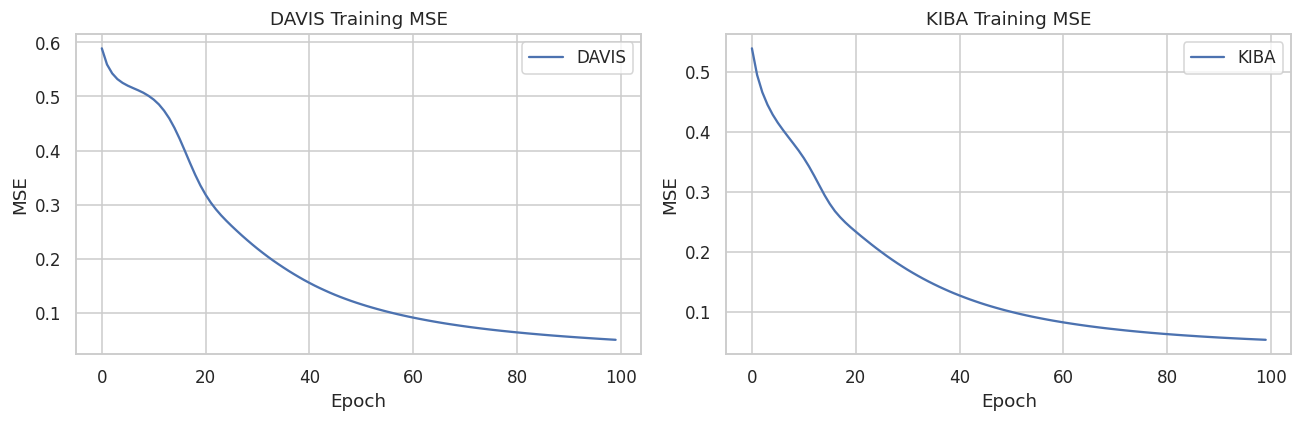

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    best_davis_model.training_history,
    label="DAVIS"
)
axes[0].set_title("DAVIS Training MSE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()

axes[1].plot(
    best_kiba_model.training_history,
    label="KIBA"
)
axes[1].set_title("KIBA Training MSE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/cf_training_convergence.png")
plt.show()

# Task 2.2 revision: collaborative filtering (supersedes the first-pass cells above)

**These cells were added after the first-pass 2.2 cells (splitting, `BiasedMatrixFactorization`, tuning, metrics, case study) and replace them.** They re-use the Task 1 cleaned data already produced above, so nothing from Task 1 needs to be re-run. Run them top to bottom.

**What changed and why.** Exact CI instead of the sampled one; random-ranking, global-, ligand- and target-mean baselines; Hit@k also on ligands with at least 10 candidates (KIBA Hit@k is inflated for ligands with few candidates); MRR and NDCG@5; a wider hyper-parameter grid with early stopping on validation; a ligand-kNN collaborative filter with fallback; sparsity, censoring and sibling-mutant analyses; a bootstrap over test ligands; a redone case study; and models saved with score-scale information.

**Tuning cache.** The full search takes about an hour. The next code cell writes the top 10 rows of each saved search result (from a complete earlier run of this exact code) into `results/*_v2.csv` so that the later cells can pick the best configuration without repeating it. To redo the whole search, set `FORCE_RETUNE = True` in the setup cell and delete the `*_v2.csv` files.

**Framing.** In collaborative-filtering terms, **ligands are the "users"**, **targets are the "items"**, and the **score is the "rating"** (pKd for DAVIS, KIBA score for KIBA; higher means stronger binding). A missing KIBA cell is "not measured", never "does not bind". The model only ever sees ligand and target **IDs**, never SMILES or sequences.

**This notebook is standalone.** It reads the Task 1 file `data/processed/{davis,kiba}_clean_ids.csv`. If those files are missing (for example on a fresh Colab runtime) it rebuilds them from the DeepDTA files with exactly the Task 1 cleaning rules, so Task 1 does not need to be re-run.

**Protocol.** One fixed 70/15/15 split (seed 42). All fitting uses the training partition only. All tuning (hyper-parameters, number of epochs, kNN settings) uses the validation partition only. The test partition is scored once per model, in section 6, and never used to choose anything.

**Sections.** 1 Data and split · 2 Models · 3 Metrics · 4 Tuning (validation only) · 5 Final models and training curves · 6 Test evaluation against baselines · 7 Save, reload and verify · 8 Analyses (sparsity, censoring, neighbours, "is it just a lookup?") · 9 Case study from the reloaded model · 10 Output inventory.

In [34]:
import os, json, pickle, time, itertools, urllib.request, warnings
from collections import OrderedDict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import kendalltau
from sklearn.model_selection import train_test_split
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

SEED = 42
FORCE_RETUNE = False      # False: reuse results/*_cf_tuning.csv if it exists. True: always redo the search.
for d in ["data/davis", "data/kiba", "data/processed", "saved_models", "results", "figures"]:
    os.makedirs(d, exist_ok=True)

In [35]:
# Top 10 rows of each hyper-parameter search from the full run (60 MF configurations and 210 kNN configurations per dataset).
CACHED_TUNING = {
    "davis_cf_tuning_v2": """n_factors,learning_rate,reg,best_epoch,epochs_run,val_MSE,train_MSE_at_stop,seconds
128,0.02,0.01,65,85,0.2377178223602835,0.0052223149846477,7.6
128,0.01,0.01,135,155,0.237998070103316,0.0056399013398059,12.8
128,0.005,0.01,294,314,0.2382551034050462,0.0057741188625658,61.0
64,0.01,0.03,132,152,0.2383267138749667,0.0432189391755283,15.3
64,0.005,0.03,232,252,0.2385729356075557,0.0462340170267755,26.9
64,0.02,0.03,67,87,0.2385879251520894,0.0414731044690383,8.0
32,0.01,0.03,150,170,0.2387589590464942,0.05154133336906,10.5
128,0.01,0.03,135,155,0.2388611902427496,0.0403871121047621,13.7
64,0.01,0.01,182,202,0.2388761742772623,0.0061329644532723,21.5
32,0.02,0.03,87,107,0.2388900040559096,0.0499590913799378,6.4
""",
    "kiba_cf_tuning_v2": """n_factors,learning_rate,reg,best_epoch,epochs_run,val_MSE,train_MSE_at_stop,seconds
128,0.02,0.01,96,116,0.1954555848940087,0.0067249534694382,45.7
256,0.02,0.01,119,139,0.1957267385190383,0.0060828275001324,123.7
128,0.01,0.01,193,213,0.1958377381895893,0.0070969269782045,81.3
256,0.01,0.01,253,273,0.1958872873426701,0.0063581832240935,221.6
128,0.005,0.01,360,380,0.1959855407346017,0.0074600286990174,165.4
256,0.005,0.01,400,400,0.1962259806474528,0.0067228589414943,331.6
256,0.01,0.03,163,183,0.1974394587805357,0.0444617799937294,152.8
128,0.01,0.03,123,143,0.197472326349969,0.0470652424370034,57.5
128,0.02,0.03,74,94,0.197619439163194,0.0456714131628628,37.8
128,0.005,0.03,222,242,0.1976197374166433,0.0488522415626716,99.3
""",
    "davis_knn_tuning_v2": """k,lam,min_shared,min_neighbours,val_MSE,fallback_rate
5,500,10,2,0.2984812009603843,0.0
5,500,3,1,0.2984812009603843,0.0
5,500,10,1,0.2984812009603843,0.0
5,500,10,3,0.2984812009603843,0.0
5,500,3,3,0.2984812009603843,0.0
5,500,3,2,0.2984812009603843,0.0
5,200,3,2,0.2989891491246816,0.0
5,200,3,1,0.2989891491246816,0.0
5,200,10,2,0.2989891491246816,0.0
5,200,10,1,0.2989891491246816,0.0
""",
    "kiba_knn_tuning_v2": """k,lam,min_shared,min_neighbours,val_MSE,fallback_rate
5,50,3,2,0.200217622757906,0.0001691284248506
5,50,3,1,0.2003483759679863,5.637614161686774e-05
5,50,3,3,0.2004051892084579,0.0006201375577855
5,100,3,2,0.2014675844034423,0.0001691284248506
5,100,3,1,0.2015983376135226,5.637614161686774e-05
5,100,3,3,0.2016547512467798,0.0006201375577855
5,10,3,2,0.2018134480533914,0.0001691284248506
5,10,3,1,0.2019442012634716,5.637614161686774e-05
5,10,3,3,0.2020024640728032,0.0006201375577855
5,200,3,2,0.2022113848550657,0.0001691284248506
""",
}
for name, text in CACHED_TUNING.items():
    path = f"results/{name}.csv"
    if not FORCE_RETUNE and not os.path.exists(path):
        open(path, "w").write(text)
        print("wrote cached tuning table", path)


wrote cached tuning table results/davis_cf_tuning_v2.csv
wrote cached tuning table results/kiba_cf_tuning_v2.csv
wrote cached tuning table results/davis_knn_tuning_v2.csv
wrote cached tuning table results/kiba_knn_tuning_v2.csv


## 1. Data and split

In [36]:
BASE = "https://raw.githubusercontent.com/hkmztrk/DeepDTA/master/data/{}/{}"

def load_raw(ds):
    for f in ["Y", "ligands_can.txt", "proteins.txt"]:
        path = f"data/{ds}/{f}"
        if not os.path.exists(path):
            urllib.request.urlretrieve(BASE.format(ds, f), path)
    Y = pickle.load(open(f"data/{ds}/Y", "rb"), encoding="latin1").astype(float)
    lig = json.load(open(f"data/{ds}/ligands_can.txt"), object_pairs_hook=OrderedDict)
    pro = json.load(open(f"data/{ds}/proteins.txt"), object_pairs_hook=OrderedDict)
    return Y, lig, pro

def rebuild_clean_ids(ds):
    # Same rules as Task 1: NaN = unmeasured (dropped), DAVIS pKd = 9 - log10(Kd nM) with Kd = 10,000 nM flagged as censored,
    # KIBA scores more than 3*IQR below Q1 flagged as low outliers (kept).
    Y, lig, pro = load_raw(ds)
    i, j = np.indices(Y.shape)
    score = "Kd_nM" if ds == "davis" else "kiba_score"
    df = pd.DataFrame({"ligand_id": np.array(list(lig), dtype=object)[i.ravel()],
                       "target_id": np.array(list(pro), dtype=object)[j.ravel()], score: Y.ravel()})
    df = df[np.isfinite(df[score])].copy()
    if ds == "davis":
        df = df[df["Kd_nM"] > 0].copy()
        df["score"] = 9 - np.log10(df["Kd_nM"]); df["censored"] = df["Kd_nM"] >= 10000
    else:
        df["score"] = df["kiba_score"]
        q1, q3 = df["score"].quantile([0.25, 0.75]); df["low_outlier"] = df["score"] < q1 - 3 * (q3 - q1)
    return df.reset_index(drop=True)

def get_clean_ids(ds):
    path = f"data/processed/{ds}_clean_ids.csv"
    if not os.path.exists(path):
        print(f"{path} not found: rebuilding it from the DeepDTA files with the Task 1 cleaning rules")
        rebuild_clean_ids(ds).to_csv(path, index=False)
    return pd.read_csv(path, dtype={"ligand_id": str, "target_id": str})   # IDs are strings (DAVIS ligand IDs are PubChem CIDs)

davis_c, kiba_c = get_clean_ids("davis"), get_clean_ids("kiba")
assert len(davis_c) == 30056 and len(kiba_c) == 118254, "unexpected row counts: not the Task 1 cleaned data"
print(f"DAVIS: {davis_c.ligand_id.nunique()} ligands x {davis_c.target_id.nunique()} targets, {len(davis_c):,} pairs "
      f"({davis_c.censored.mean():.1%} censored at pKd = 5)")
print(f"KIBA : {kiba_c.ligand_id.nunique()} ligands x {kiba_c.target_id.nunique()} targets, {len(kiba_c):,} pairs "
      f"({1 - len(kiba_c) / (kiba_c.ligand_id.nunique() * kiba_c.target_id.nunique()):.1%} missing, {kiba_c.low_outlier.sum()} flagged low outliers)")

DAVIS: 68 ligands x 442 targets, 30,056 pairs (69.6% censored at pKd = 5)
KIBA : 2111 ligands x 229 targets, 118,254 pairs (75.5% missing, 20 flagged low outliers)


In [37]:
def make_cf_split(df, seed=SEED):
    """70/15/15 pair-level split. Retries seed, seed+1, ... until every ligand and target occurs in the training partition."""
    df = df.dropna(subset=["score"]).reset_index(drop=True)
    assert not df.duplicated(["ligand_id", "target_id"]).any()
    all_l, all_t = set(df.ligand_id), set(df.target_id)
    for attempt in range(1000):
        rs = seed + attempt
        train, rest = train_test_split(df, test_size=0.30, random_state=rs)
        val, test = train_test_split(rest, test_size=0.50, random_state=rs)
        if all_l <= set(train.ligand_id) and all_t <= set(train.target_id):
            break
    else:
        raise ValueError("could not find a valid split")
    pairs = lambda d: set(zip(d.ligand_id, d.target_id))
    assert pairs(train).isdisjoint(pairs(val)) and pairs(train).isdisjoint(pairs(test)) and pairs(val).isdisjoint(pairs(test))
    for part in (val, test):
        assert set(part.ligand_id) <= set(train.ligand_id) and set(part.target_id) <= set(train.target_id)
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True), rs

SPLITS = {}
for name, df in [("DAVIS", davis_c), ("KIBA", kiba_c)]:
    tr, va, te, used_seed = make_cf_split(df)
    SPLITS[name] = dict(train=tr, val=va, test=te, seed=used_seed)

split_table = pd.DataFrame([{"Dataset": n, "Partition": p, "Pairs": len(s[p.lower()]), "Share": len(s[p.lower()]) / sum(len(s[q]) for q in ("train", "val", "test")),
                             "Ligands": s[p.lower()].ligand_id.nunique(), "Targets": s[p.lower()].target_id.nunique(), "Seed used": s["seed"]}
                            for n, s in SPLITS.items() for p in ("Train", "Val", "Test")])
display(split_table.round(3))
split_table.to_csv("results/cf_split_summary.csv", index=False)
pd.concat([s[p].assign(dataset=n, partition=p)[["dataset", "partition", "ligand_id", "target_id"]]
           for n, s in SPLITS.items() for p in ("train", "val", "test")]).to_csv("results/cf_split_pairs.csv", index=False)
print("Checks passed: no pair appears in two partitions; every ligand and target of validation/test also occurs in train.")

,Dataset,Partition,Pairs,Share,Ligands,Targets,Seed used
0,DAVIS,Train,21039,0.70,68,442,42
1,DAVIS,Val,4508,0.15,68,442,42
2,DAVIS,Test,4509,0.15,68,442,42
3,KIBA,Train,82777,0.70,2111,229,42
4,KIBA,Val,17738,0.15,1988,227,42
5,KIBA,Test,17739,0.15,2003,227,42


Checks passed: no pair appears in two partitions; every ligand and target of validation/test also occurs in train.


## 2. Models

**Biased matrix factorisation** (the main collaborative-filtering model):
`score(l, t) = mu + b_l + b_t + p_l . q_t`, with `mu` the training mean, `b_l`, `b_t` ligand and target biases, and `p_l`, `q_t` latent vectors. Fitted by mini-batch SGD (batch 4096) on the squared error with L2 regularisation `reg` on biases and factors, initial factors N(0, 0.05²), data order reshuffled each epoch, seed 42.

New relative to the first version: the number of epochs is now chosen on the validation partition. Training runs up to `epochs` and the weights of the best validation epoch are restored (early stopping, patience in epochs).

**Ligand-kNN** (neighbour-based collaborative filtering, used as a second CF model and to study sparsity). It works on residuals from the additive baseline: `pred(l,t) = base(l,t) + sum_n w(l,n) * (r(n,t) - base(n,t)) / sum_n w(l,n)`, over the `k` most similar ligands `n` that were measured on `t`. `w` is the cosine similarity of two ligands' residual profiles over the targets both were measured on, shrunk by `n_shared / (n_shared + lam)` and set to 0 when fewer than `min_shared` targets are shared. Only positively similar neighbours are used. If fewer than `min_neighbours` neighbours exist, the prediction **falls back to the additive baseline**.

**Saved model class.** `CFModel` holds only the arrays that are written to `.npz`, so a reloaded model can predict without the training code. For IDs it has never seen it uses a documented fallback instead of raising `KeyError` (relevant for Task 3): unseen target means the ligand's training mean, unseen ligand means the global mean plus the target bias, both unseen means the global mean.

In [38]:
class BiasedMatrixFactorization:
    def __init__(self, n_factors=16, learning_rate=0.005, reg=0.01, epochs=100, seed=SEED):
        self.n_factors, self.lr, self.reg, self.epochs, self.seed = n_factors, learning_rate, reg, epochs, seed

    def _predict_idx(self, ui, ii):
        return self.global_mean + self.bu[ui] + self.bi[ii] + np.sum(self.P[ui] * self.Q[ii], axis=1)

    def fit(self, train_df, val_df=None, patience=None):
        rng = np.random.default_rng(self.seed)
        self.ligands = sorted(train_df.ligand_id.unique()); self.targets = sorted(train_df.target_id.unique())
        self.lig_to_idx = {x: i for i, x in enumerate(self.ligands)}; self.tar_to_idx = {x: i for i, x in enumerate(self.targets)}
        u = train_df.ligand_id.map(self.lig_to_idx).to_numpy(); i = train_df.target_id.map(self.tar_to_idx).to_numpy()
        r = train_df.score.to_numpy(dtype=np.float64)
        self.global_mean = r.mean()
        nu, ni = len(self.ligands), len(self.targets)
        self.P = rng.normal(0, 0.05, (nu, self.n_factors)); self.Q = rng.normal(0, 0.05, (ni, self.n_factors))
        self.bu = np.zeros(nu); self.bi = np.zeros(ni)
        self.train_history, self.val_history = [], []
        if val_df is not None:
            vu = val_df.ligand_id.map(self.lig_to_idx).to_numpy(); vi = val_df.target_id.map(self.tar_to_idx).to_numpy()
            vr = val_df.score.to_numpy(dtype=np.float64)
        best_val, best_state, self.best_epoch, bs = np.inf, None, self.epochs, 4096
        for epoch in range(1, self.epochs + 1):
            order = rng.permutation(len(r))
            for s in range(0, len(r), bs):
                b = order[s:s + bs]; ub, ib, rb = u[b], i[b], r[b]
                pu, qi = self.P[ub].copy(), self.Q[ib].copy()
                err = rb - (self.global_mean + self.bu[ub] + self.bi[ib] + np.sum(pu * qi, axis=1))
                np.add.at(self.bu, ub, self.lr * (err - self.reg * self.bu[ub]))
                np.add.at(self.bi, ib, self.lr * (err - self.reg * self.bi[ib]))
                np.add.at(self.P, ub, self.lr * (err[:, None] * qi - self.reg * pu))
                np.add.at(self.Q, ib, self.lr * (err[:, None] * pu - self.reg * qi))
            self.train_history.append(float(np.mean((r - self._predict_idx(u, i)) ** 2)))
            if val_df is not None:
                v = float(np.mean((vr - self._predict_idx(vu, vi)) ** 2)); self.val_history.append(v)
                if v < best_val:
                    best_val, self.best_epoch = v, epoch
                    best_state = (self.P.copy(), self.Q.copy(), self.bu.copy(), self.bi.copy())
                if patience and epoch - self.best_epoch >= patience:
                    break
        if val_df is not None and patience:
            self.P, self.Q, self.bu, self.bi = best_state       # restore the best validation epoch
        self.best_val_mse = best_val if val_df is not None else np.nan
        return self

    def predict(self, ligand_ids, target_ids):
        ui = np.array([self.lig_to_idx[x] for x in ligand_ids]); ii = np.array([self.tar_to_idx[x] for x in target_ids])
        return self._predict_idx(ui, ii)


class LigandKNN:
    def __init__(self, k=20, lam=10.0, min_shared=3, min_neighbours=1):
        self.k, self.lam, self.min_shared, self.min_neighbours = k, lam, min_shared, min_neighbours

    def fit(self, train_df):
        self.ligands = sorted(train_df.ligand_id.unique()); self.targets = sorted(train_df.target_id.unique())
        self.li = {x: i for i, x in enumerate(self.ligands)}; self.ti = {x: i for i, x in enumerate(self.targets)}
        nl, nt = len(self.ligands), len(self.targets)
        u = train_df.ligand_id.map(self.li).to_numpy(); i = train_df.target_id.map(self.ti).to_numpy()
        r = train_df.score.to_numpy(float)
        self.mu = r.mean()
        lm = np.bincount(u, r, nl) / np.bincount(u, minlength=nl); tm = np.bincount(i, r, nt) / np.bincount(i, minlength=nt)
        self.base_mat = lm[:, None] + tm[None, :] - self.mu              # additive baseline for every (ligand, target)
        self.R = np.zeros((nl, nt)); self.O = np.zeros((nl, nt))
        self.R[u, i] = r - self.base_mat[u, i]; self.O[u, i] = 1.0       # residuals; 0 where unmeasured
        n = self.O @ self.O.T                                            # number of shared measured targets
        num = self.R @ self.R.T
        sa = (self.R ** 2) @ self.O.T                                    # sum of own squared residuals over the shared targets
        den = np.sqrt(sa * sa.T)
        with np.errstate(invalid="ignore", divide="ignore"):
            w = np.where(den > 1e-12, num / den, 0.0)
        w = w * n / (n + self.lam)                                       # shrink similarities that rest on few shared targets
        w[n < self.min_shared] = 0.0; np.fill_diagonal(w, 0.0)
        self.W, self.n_shared = w, n
        return self

    def predict(self, lig, tgt, return_info=False):
        ui = np.array([self.li[x] for x in lig]); ti = np.array([self.ti[x] for x in tgt])
        base = self.base_mat[ui, ti]; pred = base.copy()
        nn = np.zeros(len(ui), int); msim = np.zeros(len(ui))
        for q in range(len(ui)):
            w = self.W[ui[q]]; cand = np.flatnonzero((w > 0) & (self.O[:, ti[q]] > 0))
            if len(cand) == 0:
                continue
            if len(cand) > self.k:
                cand = cand[np.argpartition(-w[cand], self.k - 1)[:self.k]]
            nn[q], msim[q] = len(cand), w[cand].mean()
            if nn[q] >= self.min_neighbours:
                pred[q] = base[q] + (w[cand] * self.R[cand, ti[q]]).sum() / w[cand].sum()
        fallback = nn < self.min_neighbours
        return (pred, nn, fallback, msim) if return_info else pred


class CFModel:
    """Biased MF restored from a .npz file. Needs nothing but the file."""
    def __init__(self, **a):
        self.__dict__.update(a)
        self.lig_to_idx = {x: i for i, x in enumerate(self.ligands)}; self.tar_to_idx = {x: i for i, x in enumerate(self.targets)}

    @classmethod
    def from_mf(cls, mf, train_df, dataset, score_scale, censor_limit=np.nan):
        lm = train_df.groupby("ligand_id").score.mean().reindex(mf.ligands).to_numpy()
        tm = train_df.groupby("target_id").score.mean().reindex(mf.targets).to_numpy()
        return cls(P=mf.P.copy(), Q=mf.Q.copy(), bu=mf.bu.copy(), bi=mf.bi.copy(), global_mean=float(mf.global_mean),
                   ligands=np.array(mf.ligands), targets=np.array(mf.targets), ligand_train_mean=lm, target_train_mean=tm,
                   dataset=dataset, score_scale=score_scale, score_min=float(train_df.score.min()), score_max=float(train_df.score.max()),
                   censor_limit=float(censor_limit),
                   hyperparameters=json.dumps(dict(n_factors=mf.n_factors, learning_rate=mf.lr, reg=mf.reg, epochs_trained=int(mf.best_epoch), seed=mf.seed)))

    def save(self, path):
        np.savez(path, P=self.P, Q=self.Q, bu=self.bu, bi=self.bi, global_mean=self.global_mean, ligands=self.ligands, targets=self.targets,
                 ligand_train_mean=self.ligand_train_mean, target_train_mean=self.target_train_mean, dataset=self.dataset,
                 score_scale=self.score_scale, score_min=self.score_min, score_max=self.score_max, censor_limit=self.censor_limit,
                 hyperparameters=self.hyperparameters)

    @classmethod
    def load(cls, path):
        z = np.load(path, allow_pickle=False)
        return cls(P=z["P"], Q=z["Q"], bu=z["bu"], bi=z["bi"], global_mean=float(z["global_mean"]), ligands=z["ligands"], targets=z["targets"],
                   ligand_train_mean=z["ligand_train_mean"], target_train_mean=z["target_train_mean"], dataset=str(z["dataset"]),
                   score_scale=str(z["score_scale"]), score_min=float(z["score_min"]), score_max=float(z["score_max"]),
                   censor_limit=float(z["censor_limit"]), hyperparameters=str(z["hyperparameters"]))

    def predict(self, ligand_ids, target_ids, fallback=True):
        li = np.array([self.lig_to_idx.get(x, -1) for x in ligand_ids]); ti = np.array([self.tar_to_idx.get(x, -1) for x in target_ids])
        ok = (li >= 0) & (ti >= 0); out = np.empty(len(li))
        out[ok] = self.global_mean + self.bu[li[ok]] + self.bi[ti[ok]] + np.sum(self.P[li[ok]] * self.Q[ti[ok]], axis=1)
        if not ok.all():
            if not fallback:
                raise KeyError("unseen ligand or target ID (call predict(..., fallback=True) to use the documented fallback)")
            m = (li >= 0) & (ti < 0); out[m] = self.ligand_train_mean[li[m]]            # unseen target: ligand's training mean
            m = (li < 0) & (ti >= 0); out[m] = self.global_mean + self.bi[ti[m]]        # unseen ligand: global mean + target bias
            m = (li < 0) & (ti < 0);  out[m] = self.global_mean                         # both unseen
        return out

## 3. Metrics

* **MSE** between predicted and true score.
* **CI (concordance index), exact.** The probability that, for two pairs with different true scores, the model orders them correctly (prediction ties count 0.5). It is computed over **all** such pairs from Kendall's tau-b: with `C` concordant and `D` discordant pairs, `CI = 0.5 + (C - D) / (2 P)`, where `P` is the number of pairs with different true scores. This replaces the earlier version that sampled one million random pairs. The cell checks the formula against a brute-force count.
* **Per-ligand ranking metrics** on held-out pairs. For each test ligand, its held-out targets are the candidates, and the "true best" is the candidate(s) with the highest true score (ties count: any tied-best target is a correct answer). **Hit@k** is 1 when a true-best target is among the model's top k. **MRR** is the mean reciprocal rank of the first true-best target. **NDCG@5** uses gain = true score minus the ligand's lowest candidate score; ligands whose candidates all tie are excluded from NDCG.
* **The "true best" is only the best among that ligand's held-out targets**, not among all targets. This is a limitation of ranking evaluation on partially observed data.
* **Random-ranking reference.** Hit@k is inflated when a ligand has few candidates (a ligand with 5 or fewer candidates always scores Hit@5 = 1). So every ranking result is reported (a) over all test ligands, (b) over ligands with at least 10 candidates, and (c) next to the expected score of a **random ranking** on the same ligands (average of 200 random rankings). Prediction ties are broken at random so that constant predictors behave like random rankings.

In [39]:
def _tie_pairs(a):
    c = np.unique(a, return_counts=True)[1].astype(float)
    return float((c * (c - 1) / 2).sum())

def exact_ci(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    n = len(y_true)
    n0 = n * (n - 1) / 2
    P = n0 - _tie_pairs(y_true)                           # pairs with different true scores
    if n < 2 or P == 0:
        return np.nan
    n2 = _tie_pairs(y_pred)
    if n2 == n0:                                          # constant prediction: every pair tied
        return 0.5
    tau_b = kendalltau(y_true, y_pred, variant="b").statistic
    return 0.5 + tau_b * np.sqrt(P * (n0 - n2)) / (2 * P)  # tau_b * sqrt(P*(n0-n2)) = C - D

def brute_ci(y_true, y_pred):                             # O(n^2) reference, only used for the check below
    dt = y_true[:, None] - y_true[None, :]; dp = y_pred[:, None] - y_pred[None, :]
    m = np.triu(dt != 0, 1)
    return ((dt[m] * dp[m] > 0).sum() + 0.5 * (dp[m] == 0).sum()) / m.sum()

_rng = np.random.default_rng(1)
for _ in range(5):
    yt = _rng.integers(0, 6, 400).astype(float); yp = np.round(yt + _rng.normal(0, 1.5, 400), 1)   # many ties on purpose
    assert abs(exact_ci(yt, yp) - brute_ci(yt, yp)) < 1e-12
print("exact CI matches the brute-force pair count on 5 random tie-heavy samples")

def mse(y, p):
    return float(np.mean((np.asarray(y, float) - np.asarray(p, float)) ** 2))

def rank_table(df, pred, seed=0):
    """One row per ligand with its held-out candidates."""
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({"lig": df.ligand_id.to_numpy(), "y": df.score.to_numpy(float), "p": np.asarray(pred, float), "j": rng.random(len(df))})
    rows = []
    for lig, g in d.groupby("lig", sort=False):
        m = len(g)
        order = np.lexsort((g.j.to_numpy(), -g.p.to_numpy()))       # best predicted first, ties broken at random
        y = g.y.to_numpy()[order]
        first_best = int(np.argmax(y == y.max())) + 1
        gain = y - y.min(); ideal = np.sort(gain)[::-1]; disc = 1 / np.log2(np.arange(2, m + 2)); k = min(5, m)
        idcg = (ideal[:k] * disc[:k]).sum()
        rows.append({"ligand_id": lig, "n_cand": m, "first_best_rank": first_best, "hit1": float(first_best <= 1),
                     "hit5": float(first_best <= 5), "rr": 1 / first_best,
                     "ndcg5": np.nan if idcg == 0 else (gain[:k] * disc[:k]).sum() / idcg})
    return pd.DataFrame(rows)

def rank_summary(rt, min_cand=1):
    r = rt[rt.n_cand >= min_cand]
    return {"N ligands": len(r), "Hit@1": r.hit1.mean(), "Hit@5": r.hit5.mean(), "MRR": r.rr.mean(), "NDCG@5": r.ndcg5.mean()}

def random_rank_table(df, n_sims=200):
    """Expected per-ligand metrics of a random ranking (mean of n_sims random permutations)."""
    tabs = [rank_table(df, np.random.default_rng(1000 + s).random(len(df)), seed=2000 + s).set_index("ligand_id") for s in range(n_sims)]
    out = sum(t[["hit1", "hit5", "rr", "ndcg5"]] for t in tabs) / n_sims
    out["n_cand"] = tabs[0]["n_cand"]
    return out.reset_index()

exact CI matches the brute-force pair count on 5 random tie-heavy samples


## 4. Baselines and tuning (validation partition only)

Reference predictors, all fitted on the training partition: **global mean**, **ligand mean**, **target mean**, and the **additive baseline** `ligand mean + target mean - global mean`. The ligand-mean and global-mean predictors cannot rank targets within a ligand at all, and the additive baseline ranks targets in the same order for every ligand (by target mean). Any gain in Hit@k over the additive baseline therefore comes from ligand-specific structure, which is exactly what collaborative filtering should add.

**Matrix factorisation search.** `n_factors` in {16, 32, 64, 128, 256}, learning rate in {0.005, 0.01, 0.02}, `reg` in {0.003, 0.01, 0.03, 0.1}, up to 400 epochs with early stopping (patience 20 epochs on validation MSE). The earlier grid had its best point at the edge on all three axes; this grid is wider on every axis, and the number of epochs is now learned instead of fixed at 100. The cell afterwards checks whether the winner is still at an edge.

In [40]:
class Baselines:
    def __init__(self, train):
        self.mu = train.score.mean()
        self.lm = train.groupby("ligand_id").score.mean(); self.tm = train.groupby("target_id").score.mean()
    def predict(self, df):
        l, t = df.ligand_id.map(self.lm).to_numpy(), df.target_id.map(self.tm).to_numpy()
        return {"Global mean": np.full(len(df), self.mu), "Ligand mean": l, "Target mean": t, "Additive baseline": l + t - self.mu}

MF_GRID = {"n_factors": [16, 32, 64, 128, 256], "learning_rate": [0.005, 0.01, 0.02], "reg": [0.003, 0.01, 0.03, 0.1]}
MAX_EPOCHS, PATIENCE = 400, 20

def _run_cfg(cfg, tr, va):
    t = time.time()
    m = BiasedMatrixFactorization(cfg[0], cfg[1], cfg[2], epochs=MAX_EPOCHS, seed=SEED).fit(tr, va, patience=PATIENCE)
    return {"n_factors": cfg[0], "learning_rate": cfg[1], "reg": cfg[2], "best_epoch": m.best_epoch, "epochs_run": len(m.val_history),
            "val_MSE": m.best_val_mse, "train_MSE_at_stop": m.train_history[-1], "seconds": round(time.time() - t, 1)}

MF_TUNING = {}
for name in ["DAVIS", "KIBA"]:
    path = f"results/{name.lower()}_cf_tuning_v2.csv"
    if os.path.exists(path) and not FORCE_RETUNE:
        MF_TUNING[name] = pd.read_csv(path); print(f"{name}: loaded {path}")
        continue
    s = SPLITS[name]; cfgs = list(itertools.product(*MF_GRID.values())); t0 = time.time()
    rows = Parallel(n_jobs=2)(delayed(_run_cfg)(c, s["train"], s["val"]) for c in cfgs)
    MF_TUNING[name] = pd.DataFrame(rows).sort_values("val_MSE").reset_index(drop=True)
    MF_TUNING[name].to_csv(path, index=False)
    print(f"{name}: {len(cfgs)} configurations in {time.time() - t0:.0f}s")

for name, t in MF_TUNING.items():
    b = t.iloc[0]
    edges = [ax for ax, vals in [("n_factors", MF_GRID["n_factors"]), ("learning_rate", MF_GRID["learning_rate"]), ("reg", MF_GRID["reg"])]
             if b[ax] in (min(vals), max(vals))]
    print(f"\n{name}: best validation MSE {b.val_MSE:.4f} with n_factors={int(b.n_factors)}, lr={b.learning_rate}, reg={b.reg}, best epoch {int(b.best_epoch)}; "
          f"best sits at the grid edge on: {edges or 'none'}")
    display(t.head(5).round(4))
    print(f"  spread of the 10 best validation MSEs: {t.val_MSE.iloc[0]:.4f} to {t.val_MSE.iloc[9]:.4f}")

DAVIS: loaded results/davis_cf_tuning_v2.csv
KIBA: loaded results/kiba_cf_tuning_v2.csv

DAVIS: best validation MSE 0.2377 with n_factors=128, lr=0.02, reg=0.01, best epoch 65; best sits at the grid edge on: ['learning_rate']


,n_factors,learning_rate,reg,best_epoch,epochs_run,val_MSE,train_MSE_at_stop,seconds
0,128,0.020,0.01,65,85,0.2377,0.0052,7.6
1,128,0.010,0.01,135,155,0.2380,0.0056,12.8
2,128,0.005,0.01,294,314,0.2383,0.0058,61.0
3,64,0.010,0.03,132,152,0.2383,0.0432,15.3
4,64,0.005,0.03,232,252,0.2386,0.0462,26.9


  spread of the 10 best validation MSEs: 0.2377 to 0.2389

KIBA: best validation MSE 0.1955 with n_factors=128, lr=0.02, reg=0.01, best epoch 96; best sits at the grid edge on: ['learning_rate']


,n_factors,learning_rate,reg,best_epoch,epochs_run,val_MSE,train_MSE_at_stop,seconds
0,128,0.020,0.01,96,116,0.1955,0.0067,45.7
1,256,0.020,0.01,119,139,0.1957,0.0061,123.7
2,128,0.010,0.01,193,213,0.1958,0.0071,81.3
3,256,0.010,0.01,253,273,0.1959,0.0064,221.6
4,128,0.005,0.01,360,380,0.1960,0.0075,165.4


  spread of the 10 best validation MSEs: 0.1955 to 0.1976


In [41]:
KNN_GRID = {"k": [1, 2, 3, 5, 10, 20, 40], "lam": [10, 50, 100, 200, 500], "min_shared": [3, 10], "min_neighbours": [1, 2, 3]}
KNN_TUNING = {}
for name in ["DAVIS", "KIBA"]:
    path = f"results/{name.lower()}_knn_tuning_v2.csv"
    if os.path.exists(path) and not FORCE_RETUNE:
        KNN_TUNING[name] = pd.read_csv(path); print(f"{name}: loaded {path}"); continue
    s = SPLITS[name]; rows = []; t0 = time.time()
    for lam, ms in itertools.product(KNN_GRID["lam"], KNN_GRID["min_shared"]):
        m = LigandKNN(1, lam, ms, 1).fit(s["train"])
        for k, mn in itertools.product(KNN_GRID["k"], KNN_GRID["min_neighbours"]):
            if mn > k: continue
            m.k, m.min_neighbours = k, mn
            p, nn, fb, _ = m.predict(s["val"].ligand_id, s["val"].target_id, True)
            rows.append({"k": k, "lam": lam, "min_shared": ms, "min_neighbours": mn, "val_MSE": mse(s["val"].score, p), "fallback_rate": fb.mean()})
    KNN_TUNING[name] = pd.DataFrame(rows).sort_values("val_MSE").reset_index(drop=True)
    KNN_TUNING[name].to_csv(path, index=False); print(f"{name}: {len(rows)} kNN configurations in {time.time() - t0:.0f}s")
for name, t in KNN_TUNING.items():
    print(f"\n{name}: best kNN configurations (validation)"); display(t.head(4).round(4))

DAVIS: loaded results/davis_knn_tuning_v2.csv
KIBA: loaded results/kiba_knn_tuning_v2.csv

DAVIS: best kNN configurations (validation)


,k,lam,min_shared,min_neighbours,val_MSE,fallback_rate
0,5,500,10,2,0.2985,0.0
1,5,500,3,1,0.2985,0.0
2,5,500,10,1,0.2985,0.0
3,5,500,10,3,0.2985,0.0



KIBA: best kNN configurations (validation)


,k,lam,min_shared,min_neighbours,val_MSE,fallback_rate
0,5,50,3,2,0.2002,0.0002
1,5,50,3,1,0.2003,0.0001
2,5,50,3,3,0.2004,0.0006
3,5,100,3,2,0.2015,0.0002


## 5. Final models and training curves

Each dataset's best configuration is refitted (same seed, so the run is identical to the search run; the cell asserts this against the tuning table) with early stopping on the validation partition. Train MSE keeps falling while validation MSE flattens, which is the overfitting that early stopping controls.

DAVIS: MF 128 factors, lr 0.02, reg 0.01, best epoch 65 of 85 run; train MSE 0.0060, validation MSE 0.2377
        kNN k=5, lam=500.0, min_shared=10, min_neighbours=2
KIBA: MF 128 factors, lr 0.02, reg 0.01, best epoch 96 of 116 run; train MSE 0.0070, validation MSE 0.1955
        kNN k=5, lam=50.0, min_shared=3, min_neighbours=2


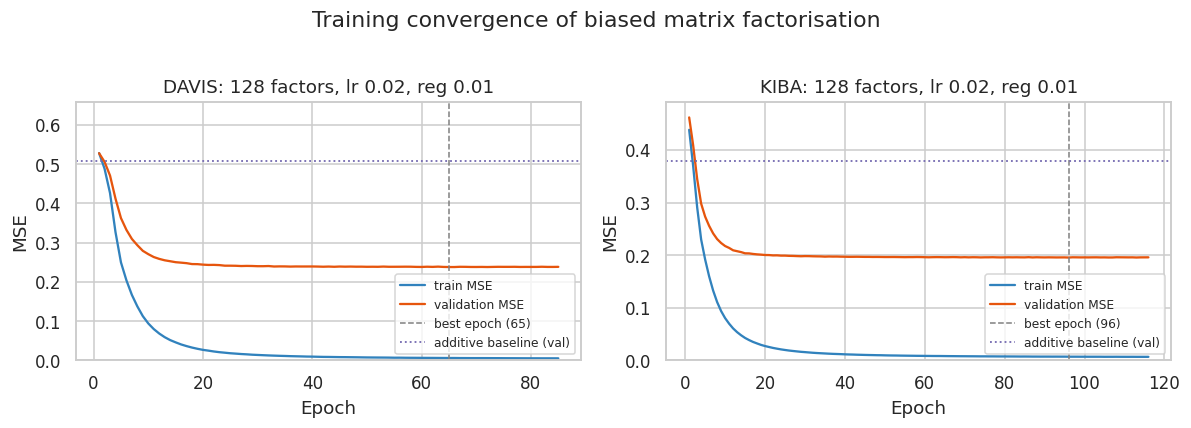

In [42]:
FINAL = {}
for name in ["DAVIS", "KIBA"]:
    s, b = SPLITS[name], MF_TUNING[name].iloc[0]
    mf = BiasedMatrixFactorization(int(b.n_factors), float(b.learning_rate), float(b.reg), epochs=MAX_EPOCHS, seed=SEED).fit(s["train"], s["val"], patience=PATIENCE)
    assert abs(mf.best_val_mse - b.val_MSE) < 1e-4, "refit does not reproduce the tuning run"
    kb = KNN_TUNING[name].iloc[0]
    knn = LigandKNN(int(kb.k), float(kb.lam), int(kb.min_shared), int(kb.min_neighbours)).fit(s["train"])
    FINAL[name] = dict(mf=mf, knn=knn, base=Baselines(s["train"]))
    print(f"{name}: MF {mf.n_factors} factors, lr {mf.lr}, reg {mf.reg}, best epoch {mf.best_epoch} of {len(mf.val_history)} run; "
          f"train MSE {mf.train_history[mf.best_epoch - 1]:.4f}, validation MSE {mf.best_val_mse:.4f}")
    print(f"        kNN k={knn.k}, lam={knn.lam}, min_shared={knn.min_shared}, min_neighbours={knn.min_neighbours}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, name in zip(axes, ["DAVIS", "KIBA"]):
    mf = FINAL[name]["mf"]; ep = np.arange(1, len(mf.val_history) + 1)
    ax.plot(ep, mf.train_history, label="train MSE", color="#3182bd"); ax.plot(ep, mf.val_history, label="validation MSE", color="#e6550d")
    ax.axvline(mf.best_epoch, color="grey", ls="--", lw=1, label=f"best epoch ({mf.best_epoch})")
    add_val = mse(SPLITS[name]["val"].score, FINAL[name]["base"].predict(SPLITS[name]["val"])["Additive baseline"])
    ax.axhline(add_val, color="#756bb1", ls=":", lw=1.2, label="additive baseline (val)")
    ax.set(xlabel="Epoch", ylabel="MSE", title=f"{name}: {mf.n_factors} factors, lr {mf.lr}, reg {mf.reg}", ylim=(0, min(1.0, add_val * 1.3)))
    ax.legend(fontsize=8)
fig.suptitle("Training convergence of biased matrix factorisation", y=1.02)
fig.tight_layout(); fig.savefig("figures/cf_training_convergence.png"); plt.show()

## 6. Test evaluation (each model scored once)

All predictions on the test partition are computed once in the next cell and stored in `PRED`; every later analysis re-uses those arrays. Nothing below is used to select anything.

In [43]:
MODEL_ORDER = ["Global mean", "Ligand mean", "Target mean", "Additive baseline", "Ligand-kNN", "Biased MF"]
PRED = {"DAVIS": {}, "KIBA": {}}; RANDOM_RT = {}
for name in ["DAVIS", "KIBA"]:
    s, f = SPLITS[name], FINAL[name]
    for part in ["train", "val", "test"]:
        d = s[part]; p = f["base"].predict(d)
        p["Biased MF"] = f["mf"].predict(d.ligand_id, d.target_id)
        if part != "train":                                   # kNN loop is pair-by-pair; train MSE for kNN would also see its own targets
            p["Ligand-kNN"] = f["knn"].predict(d.ligand_id, d.target_id)
        PRED[name][part] = p
    RANDOM_RT[name] = random_rank_table(s["test"])

rows_main, rows_rank = [], []
for name in ["DAVIS", "KIBA"]:
    s = SPLITS[name]
    for m in MODEL_ORDER:
        r = {"Dataset": name, "Model": m}
        for part in ["train", "val", "test"]:
            if m in PRED[name][part]:
                r[f"{part.capitalize()} MSE"] = mse(s[part].score, PRED[name][part][m])
                if part != "train" or m in ("Biased MF",):
                    r[f"{part.capitalize()} CI"] = exact_ci(s[part].score, PRED[name][part][m])
        rt = rank_table(s["test"], PRED[name]["test"][m]); PRED[name].setdefault("rank_tables", {})[m] = rt
        for label, mc in [("all", 1), (">=10 cand.", 10)]:
            rows_rank.append({"Dataset": name, "Model": m, "Ligands": label, **rank_summary(rt, mc)})
        rows_main.append(r)
    for label, mc in [("all", 1), (">=10 cand.", 10)]:
        rows_rank.append({"Dataset": name, "Model": "Random ranking (expected)", "Ligands": label, **rank_summary(RANDOM_RT[name], mc)})

main_tab = pd.DataFrame(rows_main); rank_tab = pd.DataFrame(rows_rank)
print("Table A. MSE and exact CI (train CI is only computed for the main model; kNN has no train score)")
display(main_tab.round(4))
print("Table B. Per-ligand ranking on the test partition")
display(rank_tab.round(3))

Table A. MSE and exact CI (train CI is only computed for the main model; kNN has no train score)


,Dataset,Model,Train MSE,Val MSE,Val CI,Test MSE,Test CI,Train CI
0,DAVIS,Global mean,0.8087,0.7753,0.5000,0.7875,0.5000,NaN
1,DAVIS,Ligand mean,0.6257,0.6007,0.7557,0.6123,0.7505,NaN
2,DAVIS,Target mean,0.7036,0.6875,0.6549,0.7222,0.6575,NaN
3,DAVIS,Additive baseline,0.5218,0.5070,0.8002,0.5473,0.7915,NaN
4,DAVIS,Ligand-kNN,NaN,0.2985,0.8612,0.3120,0.8646,NaN
5,DAVIS,Biased MF,0.0060,0.2377,0.8907,0.2468,0.8899,0.9931
6,KIBA,Global mean,0.7012,0.7041,0.5000,0.6936,0.5000,NaN
7,KIBA,Ligand mean,0.4032,0.4365,0.7035,0.4162,0.7056,NaN
8,KIBA,Target mean,0.6033,0.6002,0.6877,0.5988,0.6827,NaN
9,KIBA,Additive baseline,0.3515,0.3784,0.7808,0.3648,0.7797,NaN


Table B. Per-ligand ranking on the test partition


,Dataset,Model,Ligands,N ligands,Hit@1,Hit@5,MRR,NDCG@5
0,DAVIS,Global mean,all,68,0.059,0.103,0.111,0.159
1,DAVIS,Global mean,>=10 cand.,68,0.059,0.103,0.111,0.159
2,DAVIS,Ligand mean,all,68,0.059,0.103,0.111,0.159
3,DAVIS,Ligand mean,>=10 cand.,68,0.059,0.103,0.111,0.159
4,DAVIS,Target mean,all,68,0.162,0.309,0.265,0.410
5,DAVIS,Target mean,>=10 cand.,68,0.162,0.309,0.265,0.410
6,DAVIS,Additive baseline,all,68,0.162,0.309,0.265,0.410
7,DAVIS,Additive baseline,>=10 cand.,68,0.162,0.309,0.265,0.410
8,DAVIS,Ligand-kNN,all,68,0.397,0.647,0.522,0.699
9,DAVIS,Ligand-kNN,>=10 cand.,68,0.397,0.647,0.522,0.699


In [44]:
mf_rows = []
for name in ["DAVIS", "KIBA"]:
    for part in ["train", "val", "test"]:
        d = SPLITS[name][part]; p = PRED[name][part]["Biased MF"]
        r = {"Dataset": name, "Partition": part.capitalize(), "MSE": mse(d.score, p), "CI": exact_ci(d.score, p)}
        if part == "test":
            rk = rank_summary(PRED[name]["rank_tables"]["Biased MF"])
            r.update({"Hit@1": rk["Hit@1"], "Hit@5": rk["Hit@5"], "MRR": rk["MRR"], "NDCG@5": rk["NDCG@5"]})
        mf_rows.append(r)
cf_eval = pd.DataFrame(mf_rows); cf_eval.to_csv("results/cf_evaluation_results.csv", index=False)
print("Main CF model (biased MF) on all three partitions"); display(cf_eval.round(4))

summary = main_tab[["Dataset", "Model", "Val MSE", "Test MSE", "Test CI"]].merge(
    rank_tab[rank_tab.Ligands == "all"][["Dataset", "Model", "Hit@1", "Hit@5", "MRR", "NDCG@5"]], on=["Dataset", "Model"]).merge(
    rank_tab[rank_tab.Ligands == ">=10 cand."][["Dataset", "Model", "Hit@1", "Hit@5"]].rename(columns={"Hit@1": "Hit@1 (>=10 cand.)", "Hit@5": "Hit@5 (>=10 cand.)"}), on=["Dataset", "Model"])
rand = rank_tab[rank_tab.Model.str.startswith("Random")]
rand_wide = rand.pivot(index="Dataset", columns="Ligands", values=["Hit@1", "Hit@5", "MRR", "NDCG@5"])
rand_row = lambda ds: {"Dataset": ds, "Model": "Random ranking (expected)", "Hit@1": rand_wide.loc[ds, ("Hit@1", "all")], "Hit@5": rand_wide.loc[ds, ("Hit@5", "all")],
                       "MRR": rand_wide.loc[ds, ("MRR", "all")], "NDCG@5": rand_wide.loc[ds, ("NDCG@5", "all")],
                       "Hit@1 (>=10 cand.)": rand_wide.loc[ds, ("Hit@1", ">=10 cand.")], "Hit@5 (>=10 cand.)": rand_wide.loc[ds, ("Hit@5", ">=10 cand.")]}
summary = pd.concat([summary, pd.DataFrame([rand_row("DAVIS"), rand_row("KIBA")])]).sort_values(["Dataset"], kind="stable").reset_index(drop=True)
summary.to_csv("results/cf_vs_baseline.csv", index=False)
print("Final comparison table (also saved as results/cf_vs_baseline.csv)"); display(summary.round(3))

Main CF model (biased MF) on all three partitions


,Dataset,Partition,MSE,CI,Hit@1,Hit@5,MRR,NDCG@5
0,DAVIS,Train,0.0060,0.9931,NaN,NaN,NaN,NaN
1,DAVIS,Val,0.2377,0.8907,NaN,NaN,NaN,NaN
2,DAVIS,Test,0.2468,0.8899,0.4412,0.7206,0.5685,0.7585
3,KIBA,Train,0.0070,0.9841,NaN,NaN,NaN,NaN
4,KIBA,Val,0.1955,0.8552,NaN,NaN,NaN,NaN
5,KIBA,Test,0.1863,0.8534,0.6670,0.9391,0.7835,0.8686


Final comparison table (also saved as results/cf_vs_baseline.csv)


,Dataset,Model,Val MSE,Test MSE,Test CI,Hit@1,Hit@5,MRR,NDCG@5,Hit@1 (>=10 cand.),Hit@5 (>=10 cand.)
0,DAVIS,Global mean,0.775,0.787,0.500,0.059,0.103,0.111,0.159,0.059,0.103
1,DAVIS,Ligand mean,0.601,0.612,0.750,0.059,0.103,0.111,0.159,0.059,0.103
2,DAVIS,Target mean,0.688,0.722,0.658,0.162,0.309,0.265,0.410,0.162,0.309
3,DAVIS,Additive baseline,0.507,0.547,0.791,0.162,0.309,0.265,0.410,0.162,0.309
4,DAVIS,Ligand-kNN,0.298,0.312,0.865,0.397,0.647,0.522,0.699,0.397,0.647
5,DAVIS,Biased MF,0.238,0.247,0.890,0.441,0.721,0.569,0.759,0.441,0.721
6,DAVIS,Random ranking (expected),NaN,NaN,NaN,0.060,0.119,0.115,0.158,0.060,0.119
7,KIBA,Global mean,0.704,0.694,0.500,0.405,0.719,0.551,0.590,0.073,0.343
8,KIBA,Ligand mean,0.437,0.416,0.706,0.405,0.719,0.551,0.590,0.073,0.343
9,KIBA,Target mean,0.600,0.599,0.683,0.493,0.821,0.637,0.741,0.193,0.568


**Reading the comparison table.** Biased MF reaches test MSE 0.247 (DAVIS) and 0.186 (KIBA), against 0.547 and 0.365 for the additive baseline and 0.787 and 0.694 for the global mean. Its exact CI is 0.890 and 0.853, against 0.792 and 0.780 for the additive baseline. The first version of this notebook (32 factors, 100 fixed epochs) had test MSE 0.2547 and 0.1962; the wider search with early stopping lowers it to 0.2468 and 0.1863 (selection used validation only).

**Ranking.** Over all KIBA test ligands, a *random* ranking already scores Hit@1 = 0.399 and Hit@5 = 0.718, because many ligands have very few held-out candidates, so the all-ligand KIBA numbers (MF 0.667 and 0.939) overstate skill. On the 766 KIBA ligands with at least 10 candidates, MF scores 0.463 and 0.860 against 0.073 and 0.338 for random and 0.193 and 0.568 for the additive baseline. On DAVIS (about 66 candidates per ligand) MF scores 0.441 and 0.721 against 0.060 and 0.119 for random and 0.162 and 0.309 for the additive baseline.

**Overfitting.** Train MSE is 0.006 (DAVIS) and 0.007 (KIBA), against validation 0.238 and 0.195, and train CI is 0.993 and 0.984 against test 0.890 and 0.853. Early stopping and regularisation limit this but the model still fits the training pairs almost exactly.

**Ligand-kNN.** The neighbour model is a close competitor on KIBA (test MSE 0.197, CI 0.856, Hit@1 0.488 for ligands with at least 10 candidates) and somewhat weaker on DAVIS (0.312, 0.865, 0.397).

## 7. Save, reload and verify

Each final model is written to `saved_models/{dataset}_cf.npz` together with the score-scale information the brief asks for: a text description of the scale and transform, the training-set minimum and maximum score, and the DAVIS censoring limit (pKd = 5). The reload check loads the files into a fresh `CFModel` (which needs nothing but the file) and compares its predictions with the in-memory model on validation and test pairs.

In [45]:
SCORE_SCALE = {"DAVIS": "pKd = 9 - log10(Kd in nM); higher = stronger binding; pKd = 5 (Kd = 10,000 nM) is the assay screening limit, so values at 5 are right-censored",
               "KIBA": "KIBA score exactly as supplied in the DeepDTA file; higher = stronger binding; no unit conversion"}
LOADED = {}
for name in ["DAVIS", "KIBA"]:
    mf = FINAL[name]["mf"]
    cfm = CFModel.from_mf(mf, SPLITS[name]["train"], name, SCORE_SCALE[name], censor_limit=5.0 if name == "DAVIS" else np.nan)
    path = f"saved_models/{name.lower()}_cf.npz"; cfm.save(path)
    LOADED[name] = CFModel.load(path)
    worst = 0.0
    for part in ["val", "test"]:
        d = SPLITS[name][part]
        worst = max(worst, float(np.max(np.abs(LOADED[name].predict(d.ligand_id, d.target_id) - mf.predict(d.ligand_id, d.target_id)))))
    L = LOADED[name]
    print(f"{path}: {os.path.getsize(path) / 1e6:.2f} MB | max |difference| between reloaded and in-memory predictions = {worst}")
    print(f"   restored: dataset={L.dataset}, score range [{L.score_min:.3f}, {L.score_max:.3f}], censor limit={L.censor_limit}, hyper-parameters={L.hyperparameters}")
    print(f"   scale: {L.score_scale}")
    assert worst == 0.0

# Unseen IDs: documented fallback instead of KeyError (this is the "before" baseline for Task 3)
L = LOADED["KIBA"]; known_l, known_t = L.ligands[0], L.targets[0]
print("\nunseen target  ->", L.predict([known_l], ["NEW_TARGET"])[0], "(= ligand training mean", L.ligand_train_mean[0], ")")
print("unseen ligand  ->", L.predict(["NEW_LIGAND"], [known_t])[0], "(= global mean + target bias)")
print("both unseen    ->", L.predict(["NEW_LIGAND"], ["NEW_TARGET"])[0], "(= global mean", L.global_mean, ")")
try:
    L.predict(["NEW_LIGAND"], [known_t], fallback=False)
except KeyError as e:
    print("fallback=False -> KeyError, as intended:", e)

saved_models/davis_cf.npz: 0.59 MB | max |difference| between reloaded and in-memory predictions = 0.0
   restored: dataset=DAVIS, score range [5.000, 10.796], censor limit=5.0, hyper-parameters={"n_factors": 128, "learning_rate": 0.02, "reg": 0.01, "epochs_trained": 65, "seed": 42}
   scale: pKd = 9 - log10(Kd in nM); higher = stronger binding; pKd = 5 (Kd = 10,000 nM) is the assay screening limit, so values at 5 are right-censored
saved_models/kiba_cf.npz: 2.55 MB | max |difference| between reloaded and in-memory predictions = 0.0
   restored: dataset=KIBA, score range [0.000, 16.799], censor limit=nan, hyper-parameters={"n_factors": 128, "learning_rate": 0.02, "reg": 0.01, "epochs_trained": 96, "seed": 42}
   scale: KIBA score exactly as supplied in the DeepDTA file; higher = stronger binding; no unit conversion

unseen target  -> 10.4785580064 (= ligand training mean 10.4785580064 )
unseen ligand  -> 11.504088096842134 (= global mean + target bias)
both unseen    -> 11.718461122110

## 8. Analyses

### 8.1 KIBA: how does sparsity change accuracy, similarity, neighbour counts and fallbacks?

Test pairs are grouped by how many measurements their **ligand has in the training partition**. For the kNN model the table also reports how many neighbours were actually available, how often it had to fall back to the additive baseline, and how reliable the similarities are: the median number of targets that a ligand shares with its five most similar ligands, and their mean similarity.

,Ligand train count,Test ligands,Test pairs,MSE Global mean,MSE Additive baseline,MSE Ligand-kNN,MSE Biased MF,Mean neighbours available,% pairs with < 3 neighbours,% fallback to baseline,Median shared targets (top-5 neighbours),Mean similarity (top-5)
0,<=10,522,1199,1.707,0.648,0.404,0.351,4.953,0.751,0.584,7.0,0.108
1,11-20,410,1229,1.878,0.696,0.417,0.397,4.985,0.163,0.081,10.0,0.148
2,21-40,205,1237,0.912,0.388,0.212,0.237,4.994,0.081,0.000,21.0,0.244
3,41-80,395,4674,0.472,0.310,0.159,0.156,4.998,0.021,0.021,37.0,0.346
4,>80,471,9400,0.491,0.309,0.159,0.146,4.999,0.000,0.000,62.0,0.413
5,all,2003,17739,0.694,0.365,0.197,0.186,4.994,0.073,0.051,54.0,0.345


kNN settings used: k=5, lam=50.0, min_shared=3, min_neighbours=2 (fallback = fewer than min_neighbours neighbours)


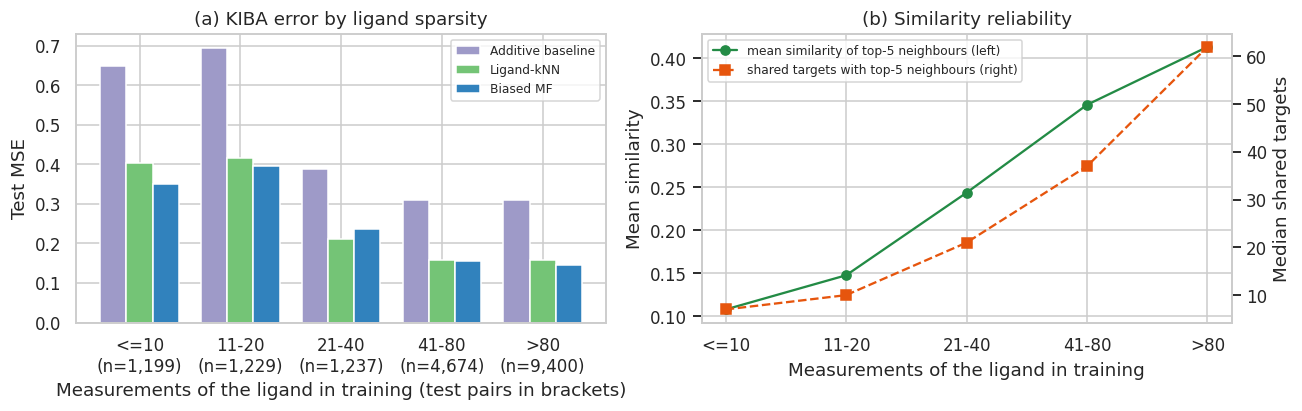

In [46]:
s = SPLITS["KIBA"]; f = FINAL["KIBA"]; knn = f["knn"]
cnt = s["train"].groupby("ligand_id").size()
te = s["test"].copy(); te["n_train"] = te.ligand_id.map(cnt)
BINS, LABELS = [0, 10, 20, 40, 80, np.inf], ["<=10", "11-20", "21-40", "41-80", ">80"]
te["bin"] = pd.cut(te.n_train, BINS, labels=LABELS)
_, nn_t, fb_t, ms_t = knn.predict(te.ligand_id, te.target_id, True)
te["nn"], te["fallback"], te["mean_sim"] = nn_t, fb_t, ms_t
for m in ["Global mean", "Additive baseline", "Ligand-kNN", "Biased MF"]:
    te[m] = PRED["KIBA"]["test"][m]

# reliability of similarities per ligand (training matrix): shared targets with the 5 most similar ligands
top5_shared = {}; top5_sim = {}
for l, li in knn.li.items():
    order = np.argsort(-knn.W[li])[:5]; order = order[knn.W[li][order] > 0]
    top5_shared[l] = np.median(knn.n_shared[li][order]) if len(order) else 0
    top5_sim[l] = knn.W[li][order].mean() if len(order) else 0
te["top5_shared"] = te.ligand_id.map(top5_shared); te["top5_sim"] = te.ligand_id.map(top5_sim)

rows = []
for b, g in te.groupby("bin", observed=True):
    rows.append({"Ligand train count": b, "Test ligands": g.ligand_id.nunique(), "Test pairs": len(g),
                 **{f"MSE {m}": mse(g.score, g[m]) for m in ["Global mean", "Additive baseline", "Ligand-kNN", "Biased MF"]},
                 "Mean neighbours available": g.nn.mean(), "% pairs with < 3 neighbours": 100 * (g.nn < 3).mean(), "% fallback to baseline": 100 * g.fallback.mean(),
                 "Median shared targets (top-5 neighbours)": g.top5_shared.median(), "Mean similarity (top-5)": g.top5_sim.mean()})
rows.append({"Ligand train count": "all", "Test ligands": te.ligand_id.nunique(), "Test pairs": len(te),
             **{f"MSE {m}": mse(te.score, te[m]) for m in ["Global mean", "Additive baseline", "Ligand-kNN", "Biased MF"]},
             "Mean neighbours available": te.nn.mean(), "% pairs with < 3 neighbours": 100 * (te.nn < 3).mean(), "% fallback to baseline": 100 * te.fallback.mean(),
             "Median shared targets (top-5 neighbours)": te.top5_shared.median(), "Mean similarity (top-5)": te.top5_sim.mean()})
sparsity = pd.DataFrame(rows); sparsity.to_csv("results/cf_kiba_sparsity_analysis.csv", index=False)
display(sparsity.round(3))
print(f"kNN settings used: k={knn.k}, lam={knn.lam}, min_shared={knn.min_shared}, min_neighbours={knn.min_neighbours} (fallback = fewer than min_neighbours neighbours)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]; plot = sparsity[sparsity["Ligand train count"] != "all"]; x = np.arange(len(plot)); w = 0.26
for off, (m, c) in zip([-w, 0, w], [("Additive baseline", "#9e9ac8"), ("Ligand-kNN", "#74c476"), ("Biased MF", "#3182bd")]):
    ax.bar(x + off, plot[f"MSE {m}"], w, label=m, color=c)
ax.set_xticks(x); ax.set_xticklabels([f"{l}\n(n={n:,})" for l, n in zip(plot["Ligand train count"], plot["Test pairs"])])
ax.set(xlabel="Measurements of the ligand in training (test pairs in brackets)", ylabel="Test MSE", title="(a) KIBA error by ligand sparsity"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(x, plot["Mean similarity (top-5)"], "o-", color="#238b45", label="mean similarity of top-5 neighbours (left)")
ax.set_xticks(x); ax.set_xticklabels(plot["Ligand train count"]); ax.set(xlabel="Measurements of the ligand in training", ylabel="Mean similarity", title="(b) Similarity reliability")
ax2 = ax.twinx(); ax2.plot(x, plot["Median shared targets (top-5 neighbours)"], "s--", color="#e6550d", label="shared targets with top-5 neighbours (right)"); ax2.set_ylabel("Median shared targets"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig("figures/cf_kiba_mse_by_ligand_sparsity.png"); plt.show()

**Sparsity on KIBA.** Test MSE of the biased MF model falls from 0.351 and 0.397 for ligands with at most 20 training measurements to 0.237 (21 to 40), 0.156 (41 to 80) and 0.146 (more than 80), so the sparsest ligands have about 2.4 times the error of the densest ones. The additive baseline shows the same pattern (0.648 and 0.696 against 0.309).

**Neighbours, similarity and fallbacks.** Neighbour *availability* is not what breaks down: with k = 5 and a minimum of 3 shared targets, almost every test pair still finds its five neighbours, and the kNN falls back to the baseline for only 0.58% of pairs in the sparsest group (0.05% overall). What degrades is the *quality* of the similarity. The five nearest neighbours of a ligand with at most 10 training measurements share a median of 7 targets with it and have mean similarity 0.11, against a median of 62 shared targets and mean similarity 0.41 for ligands with more than 80 measurements. Sparse ligands are therefore matched to neighbours on very little evidence. MF is better than kNN for the two sparsest groups (0.351 against 0.404, 0.397 against 0.417), kNN is better for the 21 to 40 group (0.212 against 0.237), and the two are about equal for dense ligands.

### 8.2 Censored and abnormal values

**DAVIS.** Training treats the censored pKd = 5 values as exact targets (a limitation, since the true value is only known to be at or below 5). Test error is split into censored pairs (true value at the screening limit) and measured binders (pKd > 5). A constant "always 5" predictor is added for reference.

**KIBA.** The 20 flagged low outliers (one ligand, CHEMBL373751, includes a 0.0) are kept. The cell shows how many fall into the test partition and how much of the test error they carry.

In [47]:
s = SPLITS["DAVIS"]; te_d = s["test"].copy(); cen = te_d.censored.to_numpy()
pd_ = dict(PRED["DAVIS"]["test"]); pd_["Always pKd = 5"] = np.full(len(te_d), 5.0)
rows = []
for m in ["Global mean", "Additive baseline", "Ligand-kNN", "Biased MF", "Always pKd = 5"]:
    p = pd_[m]; se = (te_d.score.to_numpy() - p) ** 2
    rows.append({"Model": m, "MSE censored (pKd = 5)": se[cen].mean(), "MSE measured binders (pKd > 5)": se[~cen].mean(), "MSE all": se.mean(),
                 "Share of squared error from measured binders": se[~cen].sum() / se.sum()})
dav_cen = pd.DataFrame(rows); dav_cen.to_csv("results/cf_davis_censored_vs_measured.csv", index=False)
print(f"DAVIS test pairs: {cen.sum():,} censored ({cen.mean():.1%}), {(~cen).sum():,} measured binders ({(~cen).mean():.1%})")
display(dav_cen.round(3))
p_mf = PRED["DAVIS"]["test"]["Biased MF"]
print(f"Biased MF on censored pairs: mean prediction {p_mf[cen].mean():.2f}, {np.mean(p_mf[cen] > 6):.1%} predicted above 6; "
      f"on measured binders: mean prediction {p_mf[~cen].mean():.2f} vs mean truth {te_d.score[~cen].mean():.2f}")

s = SPLITS["KIBA"]; te_k = s["test"].copy(); te_k["pred"] = PRED["KIBA"]["test"]["Biased MF"]; te_k["se"] = (te_k.score - te_k.pred) ** 2
out_te = te_k[te_k.low_outlier]
print(f"\nKIBA flagged low outliers: {int(s['train'].low_outlier.sum())} in train, {int(s['val'].low_outlier.sum())} in validation, {len(out_te)} in test")
display(out_te[["ligand_id", "target_id", "score", "pred", "se"]].round(3))
print(f"Share of KIBA test squared error carried by the flagged outliers: {out_te.se.sum() / te_k.se.sum():.2%}; "
      f"test MSE with all pairs {te_k.se.mean():.4f}, without the flagged pairs {te_k[~te_k.low_outlier].se.mean():.4f}")

DAVIS test pairs: 3,135 censored (69.5%), 1,374 measured binders (30.5%)


,Model,MSE censored (pKd = 5),MSE measured binders (pKd > 5),MSE all,Share of squared error from measured binders
0,Global mean,0.206,2.115,0.787,0.819
1,Additive baseline,0.210,1.316,0.547,0.733
2,Ligand-kNN,0.115,0.761,0.312,0.743
3,Biased MF,0.091,0.602,0.247,0.743
4,Always pKd = 5,0.000,3.245,0.989,1.000


Biased MF on censored pairs: mean prediction 5.15, 1.4% predicted above 6; on measured binders: mean prediction 6.14 vs mean truth 6.47

KIBA flagged low outliers: 16 in train, 2 in validation, 2 in test


,ligand_id,target_id,score,pred,se
4364,CHEMBL280074,P22694,8.799,8.912,0.013
13920,CHEMBL373751,P00533,1.100,3.284,4.771


Share of KIBA test squared error carried by the flagged outliers: 0.14%; test MSE with all pairs 0.1863, without the flagged pairs 0.1861


**DAVIS censoring.** 69.5% of DAVIS test pairs are censored at pKd = 5, but the 30.5% measured binders carry 74.3% of the squared error of the MF model (MSE 0.602 on binders, 0.091 on censored pairs). An "always 5" predictor has MSE 0.989 overall and 3.245 on binders, so the MF model has learned far more than "pKd = 5": its binder error is about 5.4 times lower. It does shrink towards the floor, though: on measured binders its mean prediction is 6.14 against a true mean of 6.47, and 1.4% of censored pairs are predicted above 6. Censored values were treated as exact targets in training (see limitations).

**KIBA outliers.** Only 2 of the 20 flagged low outliers fall in the test partition (16 in train, 2 in validation). One of them (CHEMBL373751 on P00533, true score 1.1, predicted 3.28) has squared error 4.77, but the two together carry only 0.14% of the test squared error, and test MSE is 0.1863 with them and 0.1861 without. The outliers matter for training and for similarity estimates, not for the test MSE.

### 8.3 Is it just a lookup? Is a recommender necessary?

Every test pair is, by construction, a ligand–target pair that never appeared in training, so no prediction is a table lookup of the pair. What the models can look up are **ligand-level and target-level averages**. The decomposition below measures how much of the improvement over a global mean is already available from those averages (the additive baseline) and how much needs ligand-specific structure (collaborative filtering). The ranking numbers in Table B / the comparison table say the same thing for the "best target for this ligand" task, where the additive baseline cannot personalise.

In [48]:
rows = []
for name in ["DAVIS", "KIBA"]:
    tm = main_tab[main_tab.Dataset == name].set_index("Model")["Test MSE"]
    g, a, k, m = tm["Global mean"], tm["Additive baseline"], tm["Ligand-kNN"], tm["Biased MF"]
    rt = rank_tab[(rank_tab.Dataset == name) & (rank_tab.Ligands == ">=10 cand.")].set_index("Model")
    rows.append({"Dataset": name, "Test MSE global mean": g, "additive": a, "kNN": k, "MF": m,
                 "MF vs additive (MSE reduction)": 1 - m / a, "MF vs global mean (MSE reduction)": 1 - m / g,
                 "Share of MF gain over global mean already given by ligand+target means": (g - a) / (g - m),
                 "Share needing ligand-specific structure": (a - m) / (g - m),
                 "Hit@1 (>=10 cand.) additive": rt.loc["Additive baseline", "Hit@1"], "Hit@1 (>=10 cand.) MF": rt.loc["Biased MF", "Hit@1"],
                 "Hit@1 (>=10 cand.) random": rt.loc["Random ranking (expected)", "Hit@1"]})
lookup = pd.DataFrame(rows).set_index("Dataset").T; lookup.to_csv("results/cf_lookup_argument.csv")
display(lookup.round(3))

# the test pairs really are unseen pairs
for name in ["DAVIS", "KIBA"]:
    tr_pairs = set(zip(SPLITS[name]["train"].ligand_id, SPLITS[name]["train"].target_id))
    assert not any(p in tr_pairs for p in zip(SPLITS[name]["test"].ligand_id, SPLITS[name]["test"].target_id))
print("Checked: no test pair occurs in the training partition.")

Dataset,DAVIS,KIBA
Test MSE global mean,0.787,0.694
additive,0.547,0.365
kNN,0.312,0.197
MF,0.247,0.186
MF vs additive (MSE reduction),0.549,0.489
MF vs global mean (MSE reduction),0.687,0.731
Share of MF gain over global mean already given by ligand+target means,0.444,0.648
Share needing ligand-specific structure,0.556,0.352
Hit@1 (>=10 cand.) additive,0.162,0.193
Hit@1 (>=10 cand.) MF,0.441,0.463


Checked: no test pair occurs in the training partition.


**Not a lookup.** No test pair occurs in training, so no prediction can be a table lookup of the pair. The ligand and target means *can* be looked up, and they supply 44% (DAVIS) and 65% (KIBA) of the improvement of MF over the global mean. The remaining 56% and 35% needs ligand-specific structure. MF lowers test MSE by 55% (DAVIS) and 49% (KIBA) relative to the additive baseline.

**Is a recommender necessary?** For predicting one score, KIBA is largely ligand-driven, and a simple neighbour model gets most of the way (kNN test MSE 0.197 against MF 0.186). For the task "which target is best for this ligand" the additive baseline cannot personalise at all, since it ranks targets by target mean for every ligand: Hit@1 for ligands with at least 10 candidates is 0.162 (DAVIS) and 0.193 (KIBA), against 0.441 and 0.463 for MF and 0.060 and 0.073 for random. A collaborative-filtering model is needed for ligand-specific ranking.

### 8.4 DAVIS mutants: how much can a sibling mutant leak?

Many DAVIS targets share one amino-acid sequence (for example ABL1 and its mutants). The model uses IDs only, which the brief allows, but it means that when a held-out pair `(ligand, mutant)` has a training pair `(same ligand, another target with the identical sequence)`, the model may be helped by a near-duplicate. The cell counts how often that happens and compares error with and without such a sibling.

In [49]:
_, _, pro_d = load_raw("davis")
seq = {t: sq for t, sq in pro_d.items()}
s = SPLITS["DAVIS"]
train_keys = set((l, seq[t]) for l, t in zip(s["train"].ligand_id, s["train"].target_id))
train_pairs_ = set(zip(s["train"].ligand_id, s["train"].target_id))
te_d = s["test"].copy(); te_d["pred"] = PRED["DAVIS"]["test"]["Biased MF"]; te_d["add"] = PRED["DAVIS"]["test"]["Additive baseline"]
te_d["sibling_in_train"] = [(l, seq[t]) in train_keys for l, t in zip(te_d.ligand_id, te_d.target_id)]
rows = []
for flag, g in te_d.groupby("sibling_in_train"):
    rows.append({"Same-sequence sibling of this ligand in train": bool(flag), "Test pairs": len(g), "Share of test": len(g) / len(te_d),
                 "MSE biased MF": mse(g.score, g.pred), "MSE additive": mse(g.score, g["add"]), "CI biased MF": exact_ci(g.score, g.pred),
                 "Share censored": g.censored.mean()})
sib = pd.DataFrame(rows); sib.to_csv("results/cf_davis_sibling_leakage.csv", index=False); display(sib.round(3))

,Same-sequence sibling of this ligand in train,Test pairs,Share of test,MSE biased MF,MSE additive,CI biased MF,Share censored
0,False,3729,0.827,0.238,0.426,0.882,0.721
1,True,780,0.173,0.289,1.125,0.911,0.572


**Sibling mutants.** 17.3% of DAVIS test pairs have a same-sequence sibling of the same ligand in training. For these pairs the MF test MSE is 0.289, against 0.238 for pairs without a sibling, so there is no sign that siblings make the task easier in MSE terms. They are more often measured binders (42.8% uncensored against 27.9%), which are harder to predict, so the two groups are not directly comparable. The within-group CI is higher for sibling pairs (0.911 against 0.882). Leakage through near-duplicate targets cannot be excluded and is listed as a limitation.

### 8.5 How much do these differences mean? Bootstrap over test ligands

The DAVIS test set has only 68 ligands, so Hit@k moves in steps of 1.5 percentage points and its sampling noise is large. The cell resamples **test ligands** with replacement (2,000 times) and reports the paired difference between the biased MF model and each competitor, with a 95% interval. A difference whose interval contains 0 is not distinguishable from noise on this split. Hit@k uses ligands with at least 10 candidates; MSE uses all test pairs (grouped by ligand).

In [50]:
rng = np.random.default_rng(SEED); B = 2000; rows = []
for name in ["DAVIS", "KIBA"]:
    rts = {m: PRED[name]["rank_tables"][m].set_index("ligand_id") for m in ["Additive baseline", "Ligand-kNN", "Biased MF"]}
    ids = rts["Biased MF"].index[rts["Biased MF"].n_cand >= 10]
    te_ = SPLITS[name]["test"]; grp = te_.ligand_id.to_numpy()
    sse = {}
    for m in rts:
        d = pd.DataFrame({"l": grp, "se": (te_.score.to_numpy() - PRED[name]["test"][m]) ** 2}).groupby("l").se.agg(["sum", "count"]); sse[m] = d
    L = sse["Biased MF"].index
    for comp in ["Additive baseline", "Ligand-kNN"]:
        for metric in ["Hit@1", "Hit@5"]:
            col = "hit1" if metric == "Hit@1" else "hit5"
            a, b = rts["Biased MF"].loc[ids, col].to_numpy(), rts[comp].loc[ids, col].to_numpy()
            idx = rng.integers(0, len(ids), (B, len(ids))); diff = a[idx].mean(1) - b[idx].mean(1)
            rows.append({"Dataset": name, "Metric": metric, "MF minus": comp, "Difference": a.mean() - b.mean(), "CI low": np.percentile(diff, 2.5), "CI high": np.percentile(diff, 97.5)})
        a_s, a_c = sse["Biased MF"].loc[L, "sum"].to_numpy(), sse["Biased MF"].loc[L, "count"].to_numpy()
        b_s = sse[comp].loc[L, "sum"].to_numpy()
        idx = rng.integers(0, len(L), (B, len(L)))
        diff = a_s[idx].sum(1) / a_c[idx].sum(1) - b_s[idx].sum(1) / a_c[idx].sum(1)
        rows.append({"Dataset": name, "Metric": "Test MSE", "MF minus": comp, "Difference": a_s.sum() / a_c.sum() - b_s.sum() / a_c.sum(),
                     "CI low": np.percentile(diff, 2.5), "CI high": np.percentile(diff, 97.5)})
boot = pd.DataFrame(rows); boot["Interval excludes 0"] = (boot["CI low"] > 0) | (boot["CI high"] < 0)
boot.to_csv("results/cf_uncertainty_bootstrap.csv", index=False); display(boot.round(4))

,Dataset,Metric,MF minus,Difference,CI low,CI high,Interval excludes 0
0,DAVIS,Hit@1,Additive baseline,0.2794,0.1618,0.3971,True
1,DAVIS,Hit@5,Additive baseline,0.4118,0.2794,0.5294,True
2,DAVIS,Test MSE,Additive baseline,-0.3005,-0.3701,-0.2384,True
3,DAVIS,Hit@1,Ligand-kNN,0.0441,-0.0294,0.1176,False
4,DAVIS,Hit@5,Ligand-kNN,0.0735,-0.0294,0.1765,False
5,DAVIS,Test MSE,Ligand-kNN,-0.0652,-0.0859,-0.0462,True
6,KIBA,Hit@1,Additive baseline,0.2702,0.2311,0.3094,True
7,KIBA,Hit@5,Additive baseline,0.2924,0.2558,0.3290,True
8,KIBA,Test MSE,Additive baseline,-0.1785,-0.1916,-0.1661,True
9,KIBA,Hit@1,Ligand-kNN,-0.0248,-0.0614,0.0131,False


**What the intervals say.** MF beats the additive baseline on every metric in both datasets, with intervals far from 0. MF against Ligand-kNN is different: MF has lower MSE (difference -0.065 on DAVIS, interval -0.086 to -0.046; -0.011 on KIBA, interval -0.018 to -0.004), but the Hit@1 and Hit@5 differences have intervals that include 0 on both datasets. On this split we cannot claim that MF ranks targets better than kNN, only that its squared error is lower.

## 9. Case study from the reloaded models

Three test ligands per dataset, **chosen by their situation before looking at any result**, so that the cases cover different conditions:

* **DAVIS 44259** is staurosporine (identified in Task 1 by its formula): it binds about 90% of all targets, so the best held-out target has many near-ties.
* **DAVIS 11338033** is moderately selective: it binds roughly one target in ten, so the correct answer is a clear single strong binder among mostly non-binders.
* **DAVIS 10127622** is very selective: almost every held-out pair sits at the pKd = 5 floor and only one is a (weak) binder.
* **KIBA CHEMBL1967538** is a sparse ligand (about 22 training measurements, 5 test pairs), **CHEMBL2004544** a medium one (about 68 training measurements, 14 test pairs), and **CHEMBL565612** a dense one (about 113 training measurements, 29 test pairs).

DAVIS ligand 11617559, the least promiscuous ligand in Task 1, is deliberately *not* used: the cell below shows that all of its test pairs are censored at pKd = 5, so every target ties for "best" and there is nothing to rank.

All predictions come from the models **reloaded from the `.npz` files**. Recommendations are the model's top 5 held-out targets for the ligand. A recommendation is labelled **correct** if its true score equals the highest true score among that ligand's held-out targets, and **wrong** otherwise. Note that "true best" means the best among the held-out targets, not among all targets.

In [51]:
d11 = SPLITS["DAVIS"]["test"]; d11 = d11[d11.ligand_id == "11617559"]
print(f"Ligand 11617559 (DAVIS): {len(d11)} test pairs, {int((d11.score > 5).sum())} above pKd = 5, {int((d11.score == d11.score.max()).sum())} tied for the best true score -> no ranking to evaluate")

CASES = {"DAVIS": [("44259", "promiscuous"), ("11338033", "moderately selective"), ("10127622", "very selective")],
         "KIBA": [("CHEMBL1967538", "sparse"), ("CHEMBL2004544", "medium density"), ("CHEMBL565612", "dense")]}
rec_rows, all_rows, case_rows = [], [], []
for name, items in CASES.items():
    s, model, base = SPLITS[name], LOADED[name], FINAL[name]["base"]
    for lig, cond in items:
        t = s["test"][s["test"].ligand_id == lig].copy(); assert len(t) > 0, f"{lig} is not in the test partition"
        t["predicted"] = model.predict(t.ligand_id, t.target_id)                      # from the reloaded .npz
        t["additive"] = base.predict(t)["Additive baseline"]
        t = t.sort_values("predicted", ascending=False).reset_index(drop=True); t["pred_rank"] = np.arange(1, len(t) + 1)
        best = t.score.max(); t["is_true_best"] = t.score == best
        t["true_rank"] = t.score.rank(ascending=False, method="min").astype(int)
        first_best = int(t.index[t.is_true_best][0]) + 1
        add_rank = int(t.sort_values("additive", ascending=False).reset_index(drop=True).is_true_best.idxmax()) + 1
        n_tr = int((s["train"].ligand_id == lig).sum()); tr_bind = s["train"][s["train"].ligand_id == lig].score
        case_rows.append({"Dataset": name, "Ligand": lig, "Condition": cond, "Train measurements": n_tr, "Test candidates": len(t), "True best score": best,
                          "Test MSE": mse(t.score, t.predicted), "Test CI": exact_ci(t.score, t.predicted), "Hit@1": float(first_best <= 1), "Hit@5": float(first_best <= 5),
                          "Predicted rank of true best": first_best, "Additive baseline: rank of true best": add_rank})
        for _, r in t.iterrows():
            all_rows.append({"Dataset": name, "Ligand": lig, "Condition": cond, "pred_rank": r.pred_rank, "target_id": r.target_id, "predicted": r.predicted,
                             "true": r.score, "true_rank": r.true_rank, "is_true_best": r.is_true_best})
        for _, r in t.head(5).iterrows():
            rec_rows.append({"Dataset": name, "Ligand": lig, "Condition": cond, "Rank": r.pred_rank, "Target": r.target_id, "Predicted score": r.predicted,
                             "True score": r.score, "Label": "correct" if r.is_true_best else "wrong"})
cases = pd.DataFrame(case_rows); recs = pd.DataFrame(rec_rows); allc = pd.DataFrame(all_rows)
cases.to_csv("results/cf_case_metrics.csv", index=False); recs.to_csv("results/cf_case_recommendations.csv", index=False); allc.to_csv("results/cf_case_all_candidates.csv", index=False)
print("\nCase-study metrics (one row per ligand)"); display(cases.round(3))
for (name, lig), g in recs.groupby(["Dataset", "Ligand"], sort=False):
    print(f"\n{name} {lig} ({g.Condition.iloc[0]}): top-5 recommendations from the reloaded model"); display(g.drop(columns=["Dataset", "Ligand", "Condition"]).round(3).reset_index(drop=True))

Ligand 11617559 (DAVIS): 66 test pairs, 0 above pKd = 5, 66 tied for the best true score -> no ranking to evaluate

Case-study metrics (one row per ligand)


,Dataset,Ligand,Condition,Train measurements,Test candidates,True best score,Test MSE,Test CI,Hit@1,Hit@5,Predicted rank of true best,Additive baseline: rank of true best
0,DAVIS,44259,promiscuous,301,62,9.796,0.785,0.766,0.0,0.0,29,42
1,DAVIS,11338033,moderately selective,301,57,8.585,0.261,0.956,1.0,1.0,1,46
2,DAVIS,10127622,very selective,319,55,5.276,0.008,0.981,0.0,1.0,2,10
3,KIBA,CHEMBL1967538,sparse,22,5,11.700,0.412,0.500,0.0,1.0,3,4
4,KIBA,CHEMBL2004544,medium density,68,14,12.600,0.079,0.835,0.0,1.0,3,1
5,KIBA,CHEMBL565612,dense,113,29,13.300,0.294,0.642,0.0,0.0,20,28



DAVIS 44259 (promiscuous): top-5 recommendations from the reloaded model


,Rank,Target,Predicted score,True score,Label
0,1,FLT3(D835Y),9.041,8.602,wrong
1,2,MAP4K2,8.711,8.056,wrong
2,3,PHKG1,8.686,9.187,wrong
3,4,ARK5,8.566,8.357,wrong
4,5,KIT(D816H),8.472,9.367,wrong



DAVIS 11338033 (moderately selective): top-5 recommendations from the reloaded model


,Rank,Target,Predicted score,True score,Label
0,1,CDKL5,7.598,8.585,correct
1,2,CDK4-cyclinD1,6.491,7.699,wrong
2,3,CDC2L2,6.435,8.284,wrong
3,4,TAOK3,6.411,7.244,wrong
4,5,CDC2L1,6.387,8.076,wrong


... (4 outputs left out)


KIBA CHEMBL2004544 (medium density): top-5 recommendations from the reloaded model


,Rank,Target,Predicted score,True score,Label
0,1,Q14680,12.152,11.9,wrong
1,2,Q9H3Y6,12.014,12.2,wrong
2,3,O00311,11.925,12.6,correct
3,4,O00444,11.915,11.7,wrong
4,5,P45983,11.845,11.6,wrong



KIBA CHEMBL565612 (dense): top-5 recommendations from the reloaded model


,Rank,Target,Predicted score,True score,Label
0,1,O95819,12.871,12.9,wrong
1,2,Q9Y4K4,12.669,12.9,wrong
2,3,Q14680,12.574,11.9,wrong
3,4,Q12851,12.446,11.4,wrong
4,5,Q5VT25,12.225,11.1,wrong


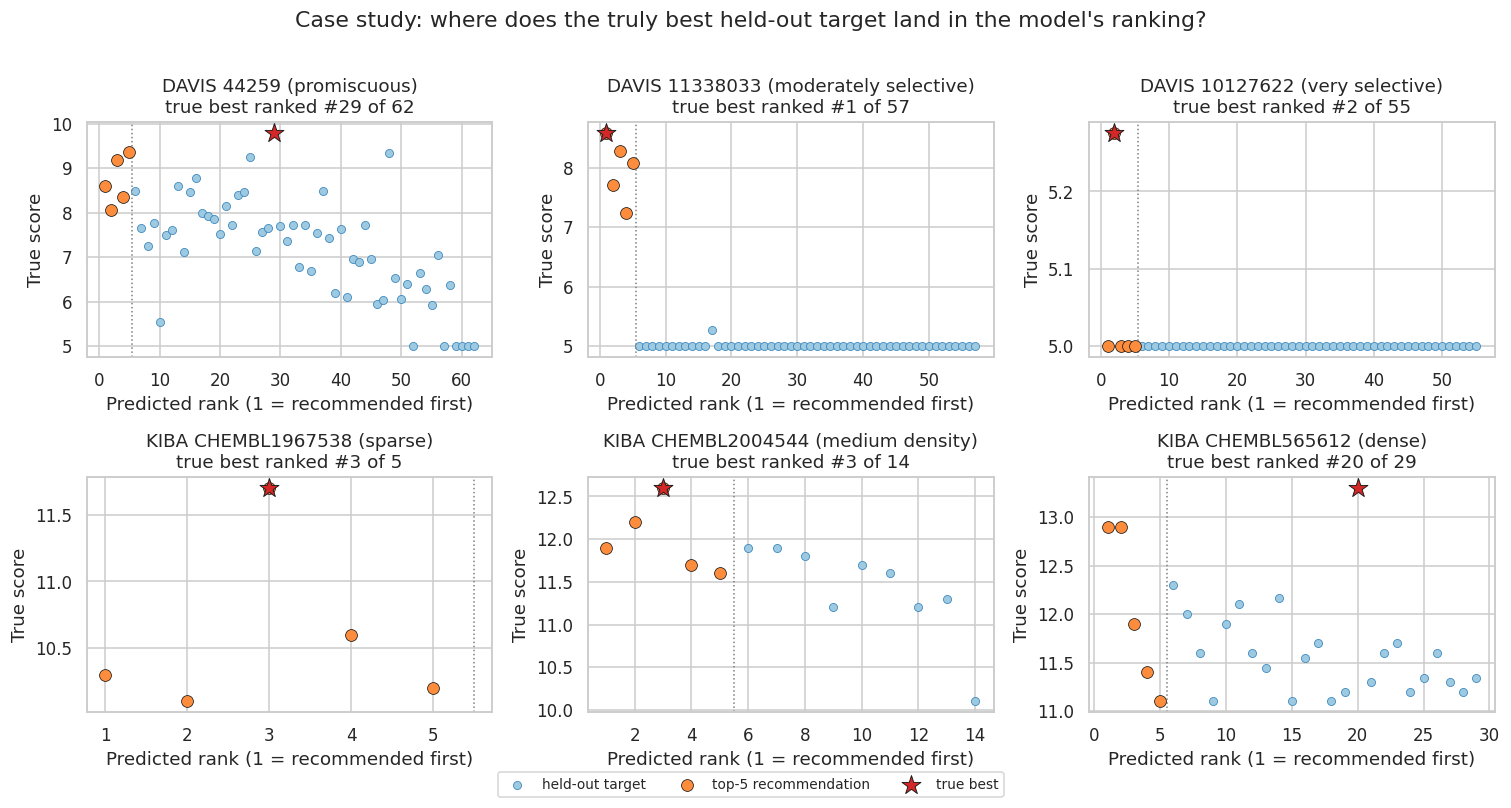

In [52]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (_, c) in zip(axes.ravel(), cases.iterrows()):
    g = allc[(allc.Dataset == c.Dataset) & (allc.Ligand == c.Ligand)]
    ax.scatter(g.pred_rank, g.true, s=28, color="#9ecae1", edgecolor="#3182bd", lw=0.5, label="held-out target")
    top = g[g.pred_rank <= 5]; ax.scatter(top.pred_rank, top.true, s=60, color="#fd8d3c", edgecolor="k", lw=0.5, label="top-5 recommendation", zorder=3)
    b = g[g.is_true_best]; ax.scatter(b.pred_rank, b.true, s=170, marker="*", color="#d62728", edgecolor="k", lw=0.6, label="true best", zorder=4)
    ax.axvline(5.5, color="grey", ls=":", lw=1)
    ax.set(xlabel="Predicted rank (1 = recommended first)", ylabel="True score", title=f"{c.Dataset} {c.Ligand} ({c.Condition})\ntrue best ranked #{int(c['Predicted rank of true best'])} of {int(c['Test candidates'])}")
h, l = axes[0, 0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Case study: where does the truly best held-out target land in the model's ranking?", y=1.01)
fig.tight_layout(); fig.savefig("figures/cf_case_study_rankings.png"); plt.show()

### Case discussion

Each case was chosen for its situation before any result was seen. The mix of outcomes is reported as it came out.

* **DAVIS 44259 (promiscuous), wrong: true best ranked 29 of 62, MSE 0.785 (the highest of the six).** Staurosporine binds most targets, so many candidates have high true scores and the best one (CAMKK2, 9.80) is only one of five targets with pKd of at least 9. The model's top five all have strong true scores (8.06 to 9.37, mean 8.71), so the recommendations are useful in practice, but under the strict rule they are all labelled "wrong". Predictions are compressed (standard deviation 0.90 against 1.21 for the truth), and the true best was under-predicted by 2.6 units (7.19 against 9.80).
* **DAVIS 11338033 (moderately selective), correct: true best ranked 1 of 57.** One target, CDKL5, stands clearly out of a field of mostly pKd = 5 pairs, and the model predicts it first (7.60 against a true 8.59). The additive baseline ranks the same target 46th, so this success needs ligand-specific information, not just a popular target.
* **DAVIS 10127622 (very selective), nearly correct: true best ranked 2 of 55, MSE 0.008.** Only one of 55 held-out pairs is above the floor (EGFR(L747S752del), pKd 5.28). The model puts it second with prediction 5.262, but the margin is tiny: the top five predictions lie between 5.18 and 5.26 and all but one of them are true non-binders. The hit is real but fragile. The additive baseline ranks this target 10th.
* **KIBA CHEMBL1967538 (sparse), wrong at rank 1 but true best at rank 3 of 5, CI 0.50.** With 22 training measurements and only 5 held-out candidates, Hit@5 = 1 is automatic and says nothing. The predictions are compressed (standard deviation 0.17 against 0.65 for the truth), so the model barely separates the five targets. This is the sparse-ligand weakness from section 8.1 in a single example.
* **KIBA CHEMBL2004544 (medium density), true best ranked 3 of 14, MSE 0.079.** The model's top three predictions are three of the five highest true scores (11.9, 12.2 and 12.6), and the true best is third. The additive baseline ranks it first here, so this is a case where the ligand-specific part did not help ranking.
* **KIBA CHEMBL565612 (dense), wrong: true best ranked 20 of 29.** The model's top two (O95819 and Q9Y4K4, both true 12.9) are near the top, but the true best (P53350, 13.30) was predicted only 11.59, an under-prediction of 1.7. Even with 113 training measurements the model can miss the one outlying strong interaction. The additive baseline ranks it 28th.

Across the six cases the true best is ranked first in 1, within the top five in 4 (including that one), and far down at ranks 20 and 29 in the other 2. Six cases are far too few to estimate a rate; the test-wide Hit@k figures are in the comparison table.

### Limitations

1. **Censored DAVIS values are treated as exact.** 69.6% of DAVIS pairs are only known to be at or below the screening limit pKd = 5, yet the squared-error loss uses 5 as if measured. A censored (Tobit-style) loss would be more faithful.
2. **DAVIS mutants share sequences.** The model is ID-based, as the brief allows, but sibling mutants in train can help held-out mutants. 17.3% of DAVIS test pairs have a same-sequence sibling of the same ligand in training (section 8.4).
3. **"True best" is relative.** It is the best among that ligand's *held-out* targets, not among all targets, and for a ligand with few held-out pairs it is a weak test. Ties count as correct. Hit@k is inflated for ligands with few candidates, which is why random-ranking and at-least-10-candidate results are reported.
4. **Small DAVIS test set.** The test partition has 68 ligands, so Hit@k differences of a few points between MF and kNN are within noise (section 8.5).
5. **One split, one seed.** There is no variation over splits; the intervals in 8.5 resample ligands within a single split.
6. **Hyper-parameter edges.** The best learning rate is at the upper edge of the grid on both datasets (0.02), and the best kNN shrinkage on DAVIS is at the edge (lam = 500). In both cases the ten best validation scores are within 0.0012 (DAVIS MF) and 0.0021 (KIBA MF) of each other, so a wider grid is unlikely to change conclusions.
7. **Overfitting.** Train MSE is only 2.5% (DAVIS) and 3.6% (KIBA) of validation MSE.
8. **Underprediction of strong binders.** Predictions are compressed towards the ligand and target means (case studies, and mean prediction 6.14 against 6.47 for DAVIS measured binders).
9. **KIBA outliers** are kept and flagged; they do not matter for test MSE (0.14% of squared error) but may distort similarities and training.
10. **Unseen entities.** The split guarantees every test ligand and target was seen in training, so MF's `predict` is only evaluated in that regime. The saved model has a simple fallback for unseen IDs, but it is not evaluated here; that is Task 3.
11. **Score scales differ** between the datasets (pKd against the KIBA score), so MSEs cannot be compared across them.

## 10. Output inventory and download

Everything below was written by this run. In Colab, run the last cell to download a zip of the three output folders before the runtime resets.

In [53]:
inv = []
for folder in ["saved_models", "results", "figures"]:
    for fn in sorted(os.listdir(folder)):
        inv.append({"file": f"{folder}/{fn}", "size_kB": round(os.path.getsize(f"{folder}/{fn}") / 1e3, 1)})
display(pd.DataFrame(inv))

,file,size_kB
0,saved_models/davis_cf.npz,586.8
1,saved_models/kiba_cf.npz,2553.4
2,results/cf_case_all_candidates.csv,16.9
3,results/cf_case_metrics.csv,0.8
4,results/cf_case_recommendations.csv,2.4
5,results/cf_davis_censored_vs_measured.csv,0.5
6,results/cf_davis_sibling_leakage.csv,0.3
7,results/cf_evaluation_results.csv,0.5
8,results/cf_kiba_sparsity_analysis.csv,1.2
9,results/cf_lookup_argument.csv,0.7


In [54]:
import subprocess
subprocess.run(["zip", "-rq", "outputs.zip", "saved_models", "results", "figures"], check=True)
try:
    from google.colab import files
    files.download("outputs.zip")          # only works inside Colab
except ImportError:
    print("outputs.zip written (not in Colab, so no browser download was triggered)")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>